# C01 - Xuất khẩu, nhập khẩu và cán cân thương mại Việt Nam

- **PIC:** Nguyễn Ngọc Khánh Vân. 
- **Phạm vi:** Việt Nam (`VNM`), 2005–2024; USD danh nghĩa, hiển thị tỷ USD.
- **Dữ liệu:** `data/clean/trade_year.csv`.
- **Thiết kế:** C01A hai đường cùng thang đo; C01B cột âm/dương qua mốc 0.
- **House Style:** import bộ hiện hành từ `notebooks/house_style/house_style.py`.


In [1]:
from pathlib import Path
import sys
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from IPython.display import display, Image

ROOT_C01 = next((p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / "data/clean/trade_year.csv").is_file()
                 and (p / "notebooks/house_style/house_style.py").is_file()), None)
if ROOT_C01 is None:
    raise FileNotFoundError("Mở notebook từ trong repository P03 có data/clean/ và House Style.")
if str(ROOT_C01 / "notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT_C01 / "notebooks"))

from house_style.house_style import (
    apply_style, declutter, format_number, TRADE_FLOW_COLORS,
    TRADE_FLOW_LINESTYLES, TRADE_FLOW_MARKERS, DIVERGING_CMAP,
    diverging_norm, DIRECT_LABEL, SUBTITLE, SOURCE, SLIDE_SIZE, BAR_WIDTH,
)

DATA_C01 = ROOT_C01 / "data/clean/trade_year.csv"
OUT_C01 = ROOT_C01 / "outputs/core_charts/C01"
OUT_C01.mkdir(parents=True, exist_ok=True)
df_c01_raw = pd.read_csv(DATA_C01, dtype={"country_iso3": "string"}, encoding="utf-8-sig")

FORMATS_C01 = ("png", "svg")

def check_c01(condition, message):
    if not bool(condition):
        raise ValueError(message)

def save_c01(fig, code, formats=FORMATS_C01):
    check_c01(set(formats) <= {"png", "svg"}, "Định dạng ảnh không được hỗ trợ.")
    folder_c01 = OUT_C01
    folder_c01.mkdir(parents=True, exist_ok=True)
    paths_c01 = []
    with apply_style():
        for extension_c01 in formats:
            path_c01 = folder_c01 / f"{code}.{extension_c01}"
            fig.savefig(path_c01, dpi=300, bbox_inches="tight", facecolor="white")
            check_c01(path_c01.is_file() and path_c01.stat().st_size > 0, f"Chưa lưu được {path_c01}.")
            paths_c01.append(path_c01)
    return paths_c01

print("Dữ liệu:", DATA_C01.relative_to(ROOT_C01))
print("Số dòng nguồn:", len(df_c01_raw))

def add_value_tables_c01(fig, data, fields, signed=False):
    """Bảng đủ từng năm, tối đa 10 năm/khối để không thu nhỏ chữ."""
    for block_c01, start_c01 in enumerate(range(0, len(data), 10)):
        part_c01 = data.iloc[start_c01:start_c01 + 10]
        bottom_c01 = 0.255 - block_c01 * 0.145
        table_ax_c01 = fig.add_axes([0.09, bottom_c01, 0.87, 0.095])
        table_ax_c01.axis("off")
        labels_c01 = ["Chỉ tiêu"] + [str(int(y)) for y in part_c01.year]
        values_c01 = [[label] + [format_number(v, 1, signed=signed) for v in part_c01[column]]
                      for column, label in fields]
        table_c01 = table_ax_c01.table(
            cellText=values_c01, colLabels=labels_c01, cellLoc="center", loc="center",
            colWidths=[0.15] + [0.85 / len(part_c01)] * len(part_c01), bbox=[0, 0, 1, 1])
        table_c01.auto_set_font_size(False)
        table_c01.set_fontsize(9)
        for (row_c01, col_c01), cell_c01 in table_c01.get_celld().items():
            cell_c01.set_edgecolor("#C6C6C6")
            cell_c01.set_linewidth(0.5)
            if row_c01 == 0:
                cell_c01.set_facecolor("#F2F2F2")
                cell_c01.get_text().set_fontweight("bold")
            if col_c01 == 0:
                cell_c01.get_text().set_fontweight("bold")
        fig.text(0.09, bottom_c01 + 0.105,
                 f"Bảng giá trị (tỷ USD) · {int(part_c01.year.iloc[0])}–{int(part_c01.year.iloc[-1])}",
                 fontsize=9, color="#555555", ha="left")

Dữ liệu: data\clean\trade_year.csv
Số dòng nguồn: 20


## C01A — Xu hướng xuất khẩu và nhập khẩu

- **Câu hỏi phụ Q1.1:** Xuất khẩu và nhập khẩu Việt Nam thay đổi như thế nào trong 2005–2024?
- **Task (action + target):** Xác định xu hướng và so sánh kim ngạch xuất khẩu/nhập khẩu qua thời gian.
- **Dạng:** line chart, hai đường chung một thang đo.
- **Lý do chọn:** trục năm liên tục giúp theo dõi thay đổi và khoảng cách hai chiều; không dùng trục kép.
- **Nguồn/cột:** `data/clean/trade_year.csv` — `year`, `country_iso3`, `export_usd`, `import_usd`.
- **Xử lý:** lọc VNM, kiểm tra đủ 20 năm, khóa duy nhất, kim ngạch hữu hạn/không âm; chia USD cho 1 tỷ.

In [2]:
# [C01A] HÀM XỬ LÝ DỮ LIỆU
def prep_c01a(raw, start_year=2005, end_year=2024, country="VNM"):
    check_c01(isinstance(start_year, int) and isinstance(end_year, int)
              and start_year < end_year, "Cần ít nhất hai năm nguyên theo thứ tự tăng.")
    required_c01a = {"year", "country_iso3", "export_usd", "import_usd"}
    check_c01(required_c01a <= set(raw.columns), f"Thiếu cột: {sorted(required_c01a - set(raw.columns))}")
    data_c01a = raw.copy(deep=True)
    year_c01a = pd.to_numeric(data_c01a["year"], errors="raise")
    check_c01(np.isfinite(year_c01a).all() and year_c01a.mod(1).eq(0).all(), "Năm thiếu hoặc không nguyên.")
    data_c01a["year"] = year_c01a.astype(int)
    data_c01a["country_iso3"] = data_c01a["country_iso3"].astype("string").str.strip()
    data_c01a = data_c01a.loc[
        data_c01a["country_iso3"].eq(country)
        & data_c01a["year"].between(start_year, end_year)
    ].sort_values("year").reset_index(drop=True)
    check_c01(not data_c01a.duplicated(["country_iso3", "year"]).any(), "Trùng khóa quốc gia × năm.")
    expected_c01a = list(range(start_year, end_year + 1))
    check_c01(data_c01a["year"].tolist() == expected_c01a, "Thiếu năm hoặc sai phạm vi sau lọc.")
    for column_c01a in ("export_usd", "import_usd"):
        data_c01a[column_c01a] = pd.to_numeric(data_c01a[column_c01a], errors="raise")
        check_c01(np.isfinite(data_c01a[column_c01a]).all()
                  and data_c01a[column_c01a].ge(0).all(), f"{column_c01a}: thiếu, âm hoặc không hữu hạn.")
    check_c01((data_c01a.loc[0, ["export_usd", "import_usd"]] > 0).all(),
              "Kim ngạch năm đầu phải dương để tính số lần tăng.")
    data_c01a["export_bn"] = data_c01a["export_usd"] / 1e9
    data_c01a["import_bn"] = data_c01a["import_usd"] / 1e9
    return data_c01a

In [3]:
# [C01A] HÀM VẼ — CHÚ GIẢI, NHÃN SỐ, ACTION TITLE VÀ BẢNG GIÁ TRỊ
def plot_c01a(data, figsize=(12, 9)):
    first_c01a, last_c01a = data.iloc[0], data.iloc[-1]
    start_c01a, end_c01a = int(first_c01a.year), int(last_c01a.year)
    export_ratio_c01a = last_c01a.export_usd / first_c01a.export_usd
    import_ratio_c01a = last_c01a.import_usd / first_c01a.import_usd
    title_c01a = (f"Xuất khẩu tăng {format_number(export_ratio_c01a, 1)} lần; "
                  f"nhập khẩu tăng {format_number(import_ratio_c01a, 1)} lần")
    ticks_c01a = sorted({start_c01a, end_c01a,
                        *range(((start_c01a + 4) // 5) * 5, end_c01a + 1, 5)})
    with apply_style():
        fig_c01a = plt.figure(figsize=figsize)
        ax_c01a = fig_c01a.add_axes([0.09, 0.46, 0.87, 0.32])
        for flow_c01a, column_c01a, label_c01a, offset_c01a in (
            ("Export", "export_bn", "Xuất khẩu", 12),
            ("Import", "import_bn", "Nhập khẩu", -17),
        ):
            color_c01a = TRADE_FLOW_COLORS[flow_c01a]
            ax_c01a.plot(data.year, data[column_c01a], color=color_c01a,
                         linestyle=TRADE_FLOW_LINESTYLES[flow_c01a],
                         marker=TRADE_FLOW_MARKERS[flow_c01a], markersize=4,
                         linewidth=2, label=label_c01a)
            for row_c01a in data.loc[data.year.isin(ticks_c01a)].itertuples():
                value_c01a = getattr(row_c01a, column_c01a)
                # Hai giá trị đầu kỳ gần nhau: lệch ngang để không đè nhãn.
                dx_c01a = 5 if row_c01a.year == start_c01a else 0
                ax_c01a.annotate(format_number(value_c01a, 1),
                                 (row_c01a.year, value_c01a),
                                 xytext=(dx_c01a, (28 if flow_c01a == "Export" else 12)
                                         if row_c01a.year == start_c01a else offset_c01a),
                                 textcoords="offset points",
                                 ha="left" if dx_c01a else "center", va="center",
                                 fontsize=9, fontweight="medium", color=color_c01a)
        ax_c01a.set_xlim(start_c01a - 0.4, end_c01a + 0.6)
        high_c01a = max(data.export_bn.max(), data.import_bn.max())
        ax_c01a.set_ylim(0, np.ceil(high_c01a * 1.12 / 100) * 100)
        ax_c01a.set_xticks(ticks_c01a)
        ax_c01a.set_xlabel("Năm")
        ax_c01a.set_ylabel("Kim ngạch (tỷ USD)")
        ax_c01a.yaxis.set_major_formatter(FuncFormatter(lambda v, _: format_number(v, 0)))
        declutter(ax_c01a, "y")
        ax_c01a.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2)
        fig_c01a.suptitle("C01A · Xu hướng xuất khẩu và nhập khẩu", y=0.955, va="center")
        fig_c01a.text(0.5, 0.900, f"Việt Nam · {start_c01a}–{end_c01a}",
                      **(SUBTITLE | {"color": "#A51C30", "va": "center"}))
        fig_c01a.text(0.5, 0.855, title_c01a, fontsize=11, ha="center", va="center", color="#444444")
        add_value_tables_c01(fig_c01a, data,
                             [("export_bn", "Xuất khẩu"), ("import_bn", "Nhập khẩu")])
        fig_c01a.text(0.5, 0.055,
                      "Nhãn trên đường: các mốc năm trên trục X · Bảng: đủ từng năm, làm tròn 1 chữ số",
                      **SOURCE)
        fig_c01a.text(0.5, 0.025,
                      "Nguồn: CEPII BACI HS2002 V202601 · trade_year.csv · USD danh nghĩa", **SOURCE)
    return fig_c01a, ax_c01a, title_c01a

Xuất khẩu tăng 13.5 lần; nhập khẩu tăng 9.5 lần
Kiểm tra đạt: 20 năm; không trùng/thiếu; chung thang tỷ USD.
Đã lưu: ['outputs\\core_charts\\C01\\C01A.png', 'outputs\\core_charts\\C01\\C01A.svg']


,year,export_bn,import_bn
0,2005,37.476,39.654
19,2024,505.202,376.826


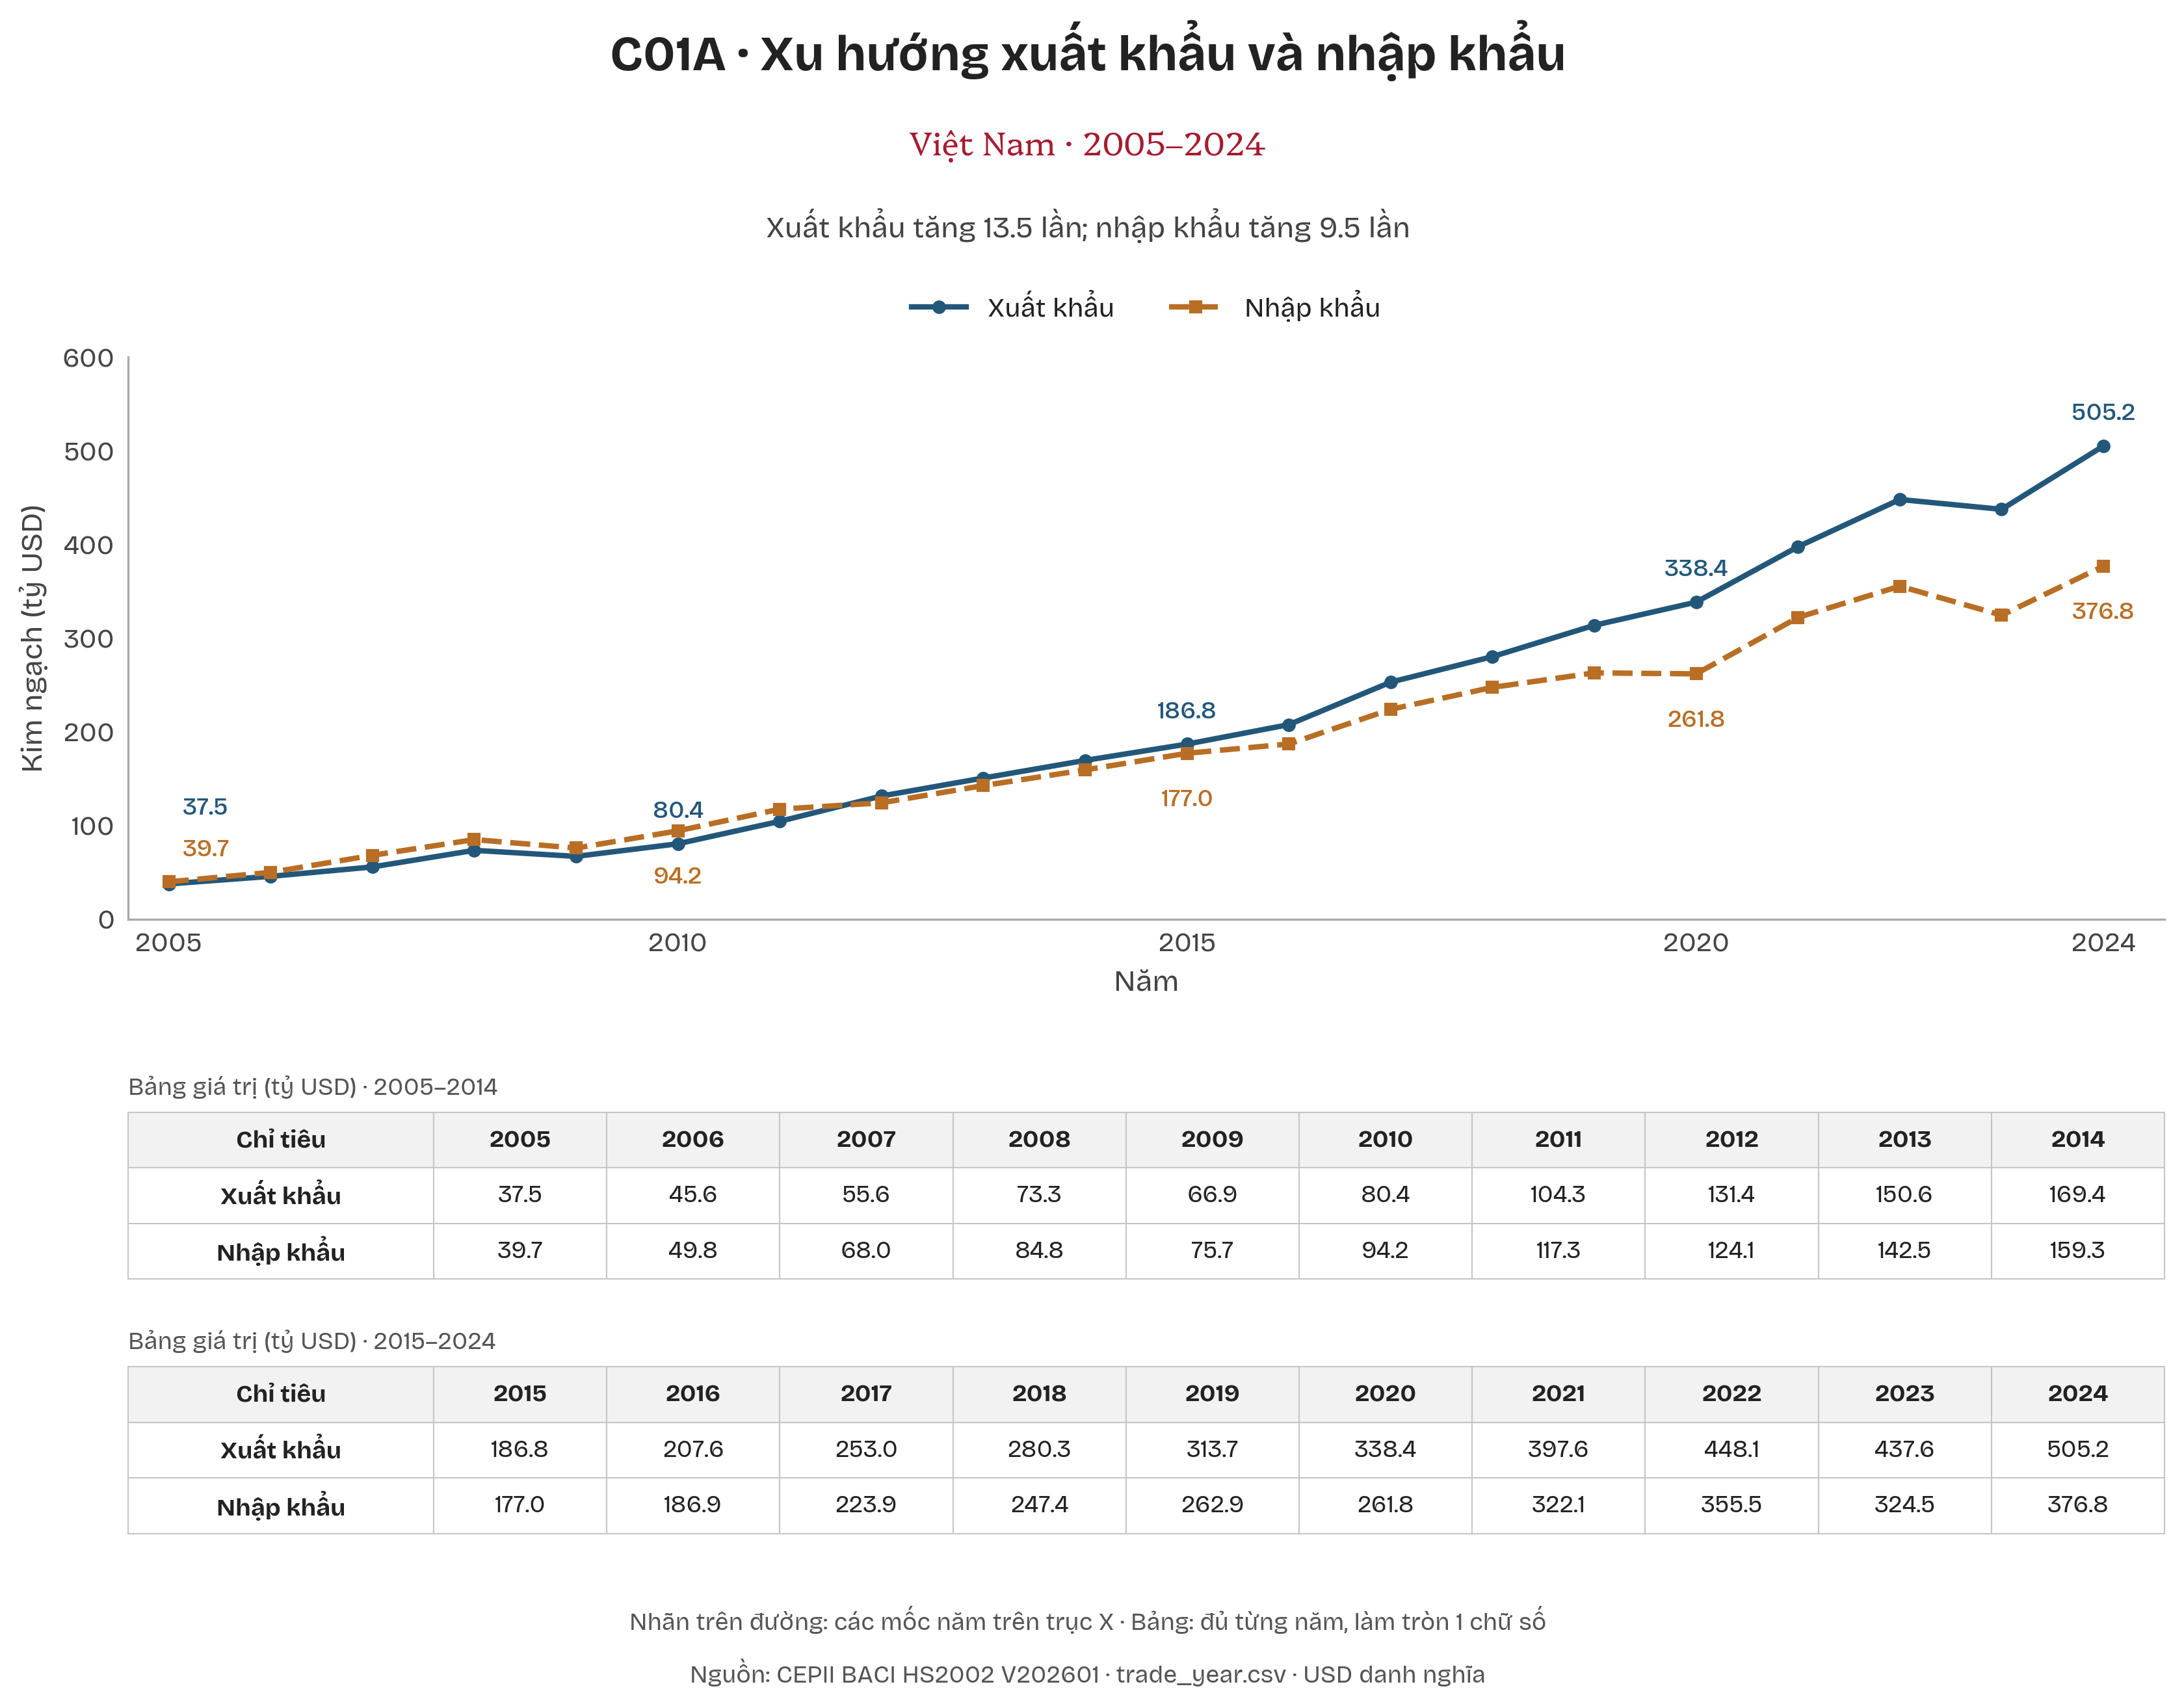

In [4]:
# [C01A] THAM SỐ → GỌI HÀM → KIỂM TRA → LƯU HÌNH
START_YEAR_C01A = 2005
END_YEAR_C01A = 2024
COUNTRY_C01A = "VNM"

df_c01a = prep_c01a(df_c01_raw, START_YEAR_C01A, END_YEAR_C01A, COUNTRY_C01A)
fig_c01a, ax_c01a, title_c01a = plot_c01a(df_c01a)
check_c01(len(df_c01a) == END_YEAR_C01A - START_YEAR_C01A + 1, "Sai số năm C01A.")
check_c01(len(ax_c01a.lines) == 2, "C01A phải có đúng hai đường trên trục biểu đồ.")
check_c01(ax_c01a.get_ylim()[0] == 0, "C01A cần trục Y bắt đầu từ 0.")
files_c01a = save_c01(fig_c01a, "C01A")
print(title_c01a)
display(df_c01a[["year", "export_bn", "import_bn"]].iloc[[0, -1]].round(3))
print("Kiểm tra đạt:", len(df_c01a), "năm; không trùng/thiếu; chung thang tỷ USD.")
print("Đã lưu:", [str(p.relative_to(ROOT_C01)) for p in files_c01a])
plt.close(fig_c01a)
# Hiển thị chính tệp PNG vừa xuất để notebook và output luôn giống nhau.
display(Image(data=(OUT_C01 / "C01A.png").read_bytes(), width=1000))

### Insight, kết luận và hạn chế — C01A
- Xuất khẩu tăng từ **37.476** lên **505.202 tỷ USD**, khoảng **13.48 lần**; nhập khẩu từ **39.654** lên **376.826 tỷ USD**, khoảng **9.50 lần**.
- Cả hai chiều giảm trong 2009 và 2023 so với năm liền trước; xu hướng toàn kỳ không phải tăng liên tục.
- Xuất khẩu vượt nhập khẩu từ 2012 trong chuỗi đang xét. Khoảng cách hai đường là chênh lệch giá trị, được thể hiện trực tiếp ở C01B.
- **Hạn chế:** đây là USD danh nghĩa và số liệu BACI đã hòa giải; không phải tăng trưởng khối lượng thực, không đồng nhất với số Việt Nam tự báo cáo. Biểu đồ tổng quan chưa trả lời cơ cấu theo HS hoặc nguyên nhân biến động.

## C01B — Cán cân thương mại

- **Câu hỏi phụ Q1.1:** Cán cân thương mại Việt Nam biến động ra sao trong 2005–2024?
- **Task (action + target):** So sánh dấu và độ lớn cán cân thương mại giữa các năm.
- **Dạng:** bar chart âm/dương; 20 cột gắn với mốc 0.
- **Lý do chọn:** chiều dài cột và hướng qua 0 thể hiện thặng dư/thâm hụt trực tiếp, không cần suy từ khoảng cách hai đường.
- **Nguồn/cột:** `data/clean/trade_year.csv` — `year`, `country_iso3`, `export_usd`, `import_usd`, `trade_balance_usd`.
- **Xử lý:** tự tính `export_usd − import_usd`, đối chiếu cột cán cân với dung sai tuyệt đối 0.01 USD; sau đó chia 1 tỷ.

In [5]:
# [C01B] HÀM XỬ LÝ DỮ LIỆU
def prep_c01b(raw, start_year=2005, end_year=2024, country="VNM"):
    check_c01("trade_balance_usd" in raw.columns, "Thiếu trade_balance_usd để đối chiếu.")
    data_c01b = prep_c01a(raw, start_year, end_year, country)
    source_balance_c01b = pd.to_numeric(data_c01b["trade_balance_usd"], errors="raise")
    check_c01(np.isfinite(source_balance_c01b).all(), "Cán cân nguồn thiếu hoặc không hữu hạn.")
    recomputed_c01b = data_c01b["export_usd"] - data_c01b["import_usd"]
    check_c01(np.isclose(recomputed_c01b, source_balance_c01b, rtol=0, atol=0.01).all(),
              "Cán cân không khớp xuất khẩu − nhập khẩu trong dung sai 0.01 USD.")
    data_c01b["balance_difference_usd"] = recomputed_c01b - source_balance_c01b
    data_c01b["balance_bn"] = recomputed_c01b / 1e9
    return data_c01b

In [6]:
# [C01B] HÀM VẼ — CHÚ GIẢI, NHÃN TỪNG CỘT VÀ BẢNG GIÁ TRỊ
def plot_c01b(data, figsize=(12, 9)):
    first_c01b, last_c01b = data.iloc[0], data.iloc[-1]
    start_c01b, end_c01b = int(first_c01b.year), int(last_c01b.year)
    def describe_c01b(value):
        if value == 0:
            return "cân bằng"
        return ("thặng dư " if value > 0 else "thâm hụt ") + format_number(abs(value), 1)
    title_c01b = (f"Từ {describe_c01b(first_c01b.balance_bn)} "
                  f"đến {describe_c01b(last_c01b.balance_bn)} tỷ USD")
    # Hai màu cố định lấy từ bảng màu phân kỳ của House Style.
    deficit_color_c01b = DIVERGING_CMAP(0.15)
    surplus_color_c01b = DIVERGING_CMAP(0.85)
    with apply_style():
        fig_c01b = plt.figure(figsize=figsize)
        ax_c01b = fig_c01b.add_axes([0.09, 0.46, 0.87, 0.32])
        bars_c01b = ax_c01b.bar(data.year, data.balance_bn, width=BAR_WIDTH,
                               color=[deficit_color_c01b if v < 0 else surplus_color_c01b
                                      for v in data.balance_bn],
                               edgecolor="#555555", linewidth=0.65)
        for bar_c01b, row_c01b in zip(bars_c01b, data.itertuples()):
            if row_c01b.balance_bn < 0:
                bar_c01b.set_hatch("///")
            ax_c01b.annotate(format_number(row_c01b.balance_bn, 1, signed=True),
                             (row_c01b.year, row_c01b.balance_bn),
                             xytext=(0, 5 if row_c01b.balance_bn >= 0 else -7),
                             textcoords="offset points", ha="center",
                             va="bottom" if row_c01b.balance_bn >= 0 else "top", fontsize=8)
        ax_c01b.axhline(0, color="#444444", linewidth=1.1, zorder=3)
        bottom_c01b = min(-30.0, float(data.balance_bn.min()) - 20)
        top_c01b = max(10.0, float(data.balance_bn.max()) * 1.2 + 4)
        ax_c01b.set_ylim(bottom_c01b, top_c01b)
        ax_c01b.set_xlim(start_c01b - 0.65, end_c01b + 0.65)
        ax_c01b.set_xticks(sorted({start_c01b, end_c01b,
                                  *range(((start_c01b + 4) // 5) * 5, end_c01b + 1, 5)}))
        ax_c01b.set_xlabel("Năm")
        ax_c01b.set_ylabel("Cán cân (tỷ USD)")
        ax_c01b.yaxis.set_major_formatter(FuncFormatter(lambda v, _: format_number(v, 0)))
        declutter(ax_c01b, "y")
        ticks_y_c01b = {0.0, *(float(t) for t in ax_c01b.get_yticks()
                               if bottom_c01b <= t <= top_c01b)}
        if data.balance_bn.min() < 0:
            ticks_y_c01b.add(float(np.floor(data.balance_bn.min() / 10) * 10))
        ax_c01b.set_yticks(sorted(ticks_y_c01b))
        ax_c01b.set_ylim(bottom_c01b, top_c01b)
        legend_c01b = [
            Patch(facecolor=deficit_color_c01b, edgecolor="#555555", hatch="///",
                  label="Thâm hụt: Nhập khẩu > Xuất khẩu"),
            Patch(facecolor=surplus_color_c01b, edgecolor="#555555",
                  label="Thặng dư: Xuất khẩu > Nhập khẩu"),
        ]
        ax_c01b.legend(handles=legend_c01b, loc="lower center",
                         bbox_to_anchor=(0.5, 1.02), ncol=2, fontsize=9)
        fig_c01b.suptitle("C01B · Cán cân thương mại", y=0.955, va="center")
        fig_c01b.text(0.5, 0.900, f"Việt Nam · {start_c01b}–{end_c01b}",
                      **(SUBTITLE | {"color": "#A51C30", "va": "center"}))
        fig_c01b.text(0.5, 0.855, title_c01b, fontsize=11, ha="center", va="center", color="#444444")
        add_value_tables_c01(fig_c01b, data, [("balance_bn", "Cán cân")], signed=True)
        fig_c01b.text(0.5, 0.065,
                      "Cán cân = Xuất khẩu − Nhập khẩu (tỷ USD). Cột dưới 0: thâm hụt; cột trên 0: thặng dư.",
                      **SOURCE)
        fig_c01b.text(0.5, 0.025,
                      "Nguồn: CEPII BACI HS2002 V202601 · trade_year.csv · USD danh nghĩa", **SOURCE)
    return fig_c01b, ax_c01b, title_c01b

Từ thâm hụt 2.2 đến thặng dư 128.4 tỷ USD
Số năm thâm hụt: 7 | thặng dư: 13
Lệch cán cân tối đa so với cột nguồn: 0.0 USD
Đã lưu: ['outputs\\core_charts\\C01\\C01B.png', 'outputs\\core_charts\\C01\\C01B.svg']


,year,balance_bn
0,2005,-2.178
1,2006,-4.246
2,2007,-12.407
3,2008,-11.479
4,2009,-8.873
5,2010,-13.822
6,2011,-12.990
7,2012,7.256
8,2013,8.073
9,2014,10.156


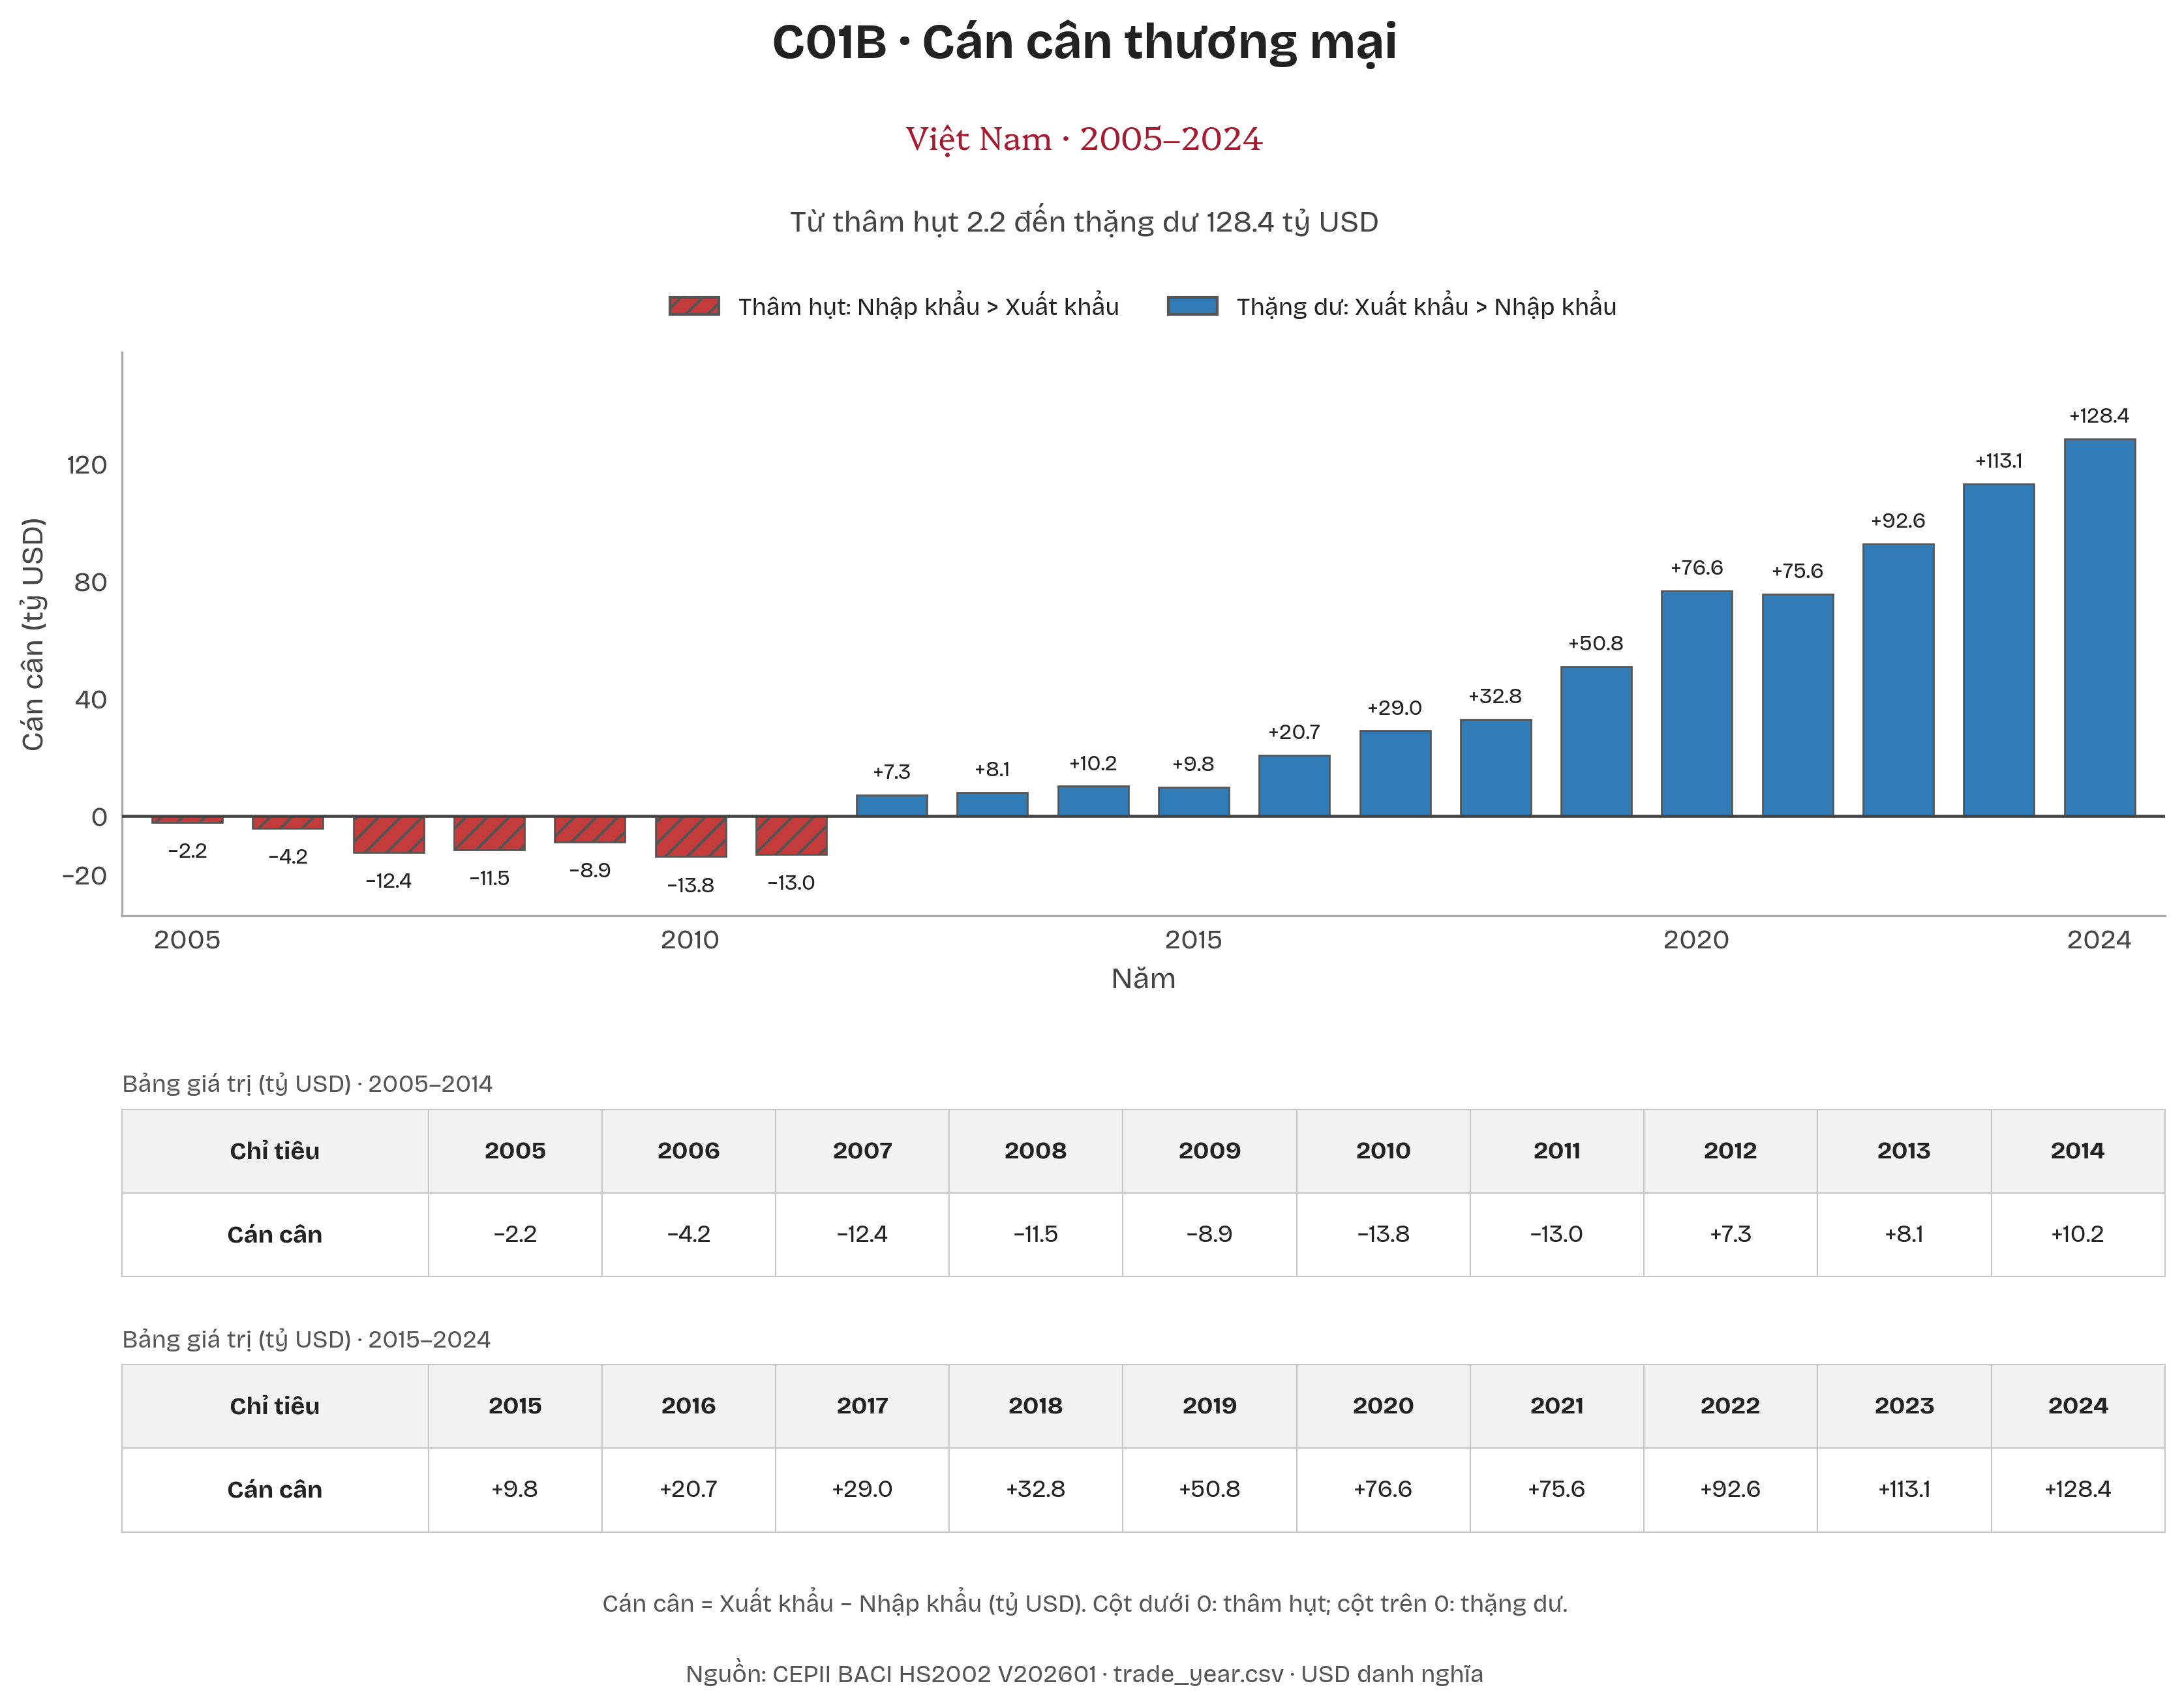

In [7]:
# [C01B] THAM SỐ → GỌI HÀM → KIỂM TRA → LƯU HÌNH
START_YEAR_C01B = 2005
END_YEAR_C01B = 2024
COUNTRY_C01B = "VNM"

df_c01b = prep_c01b(df_c01_raw, START_YEAR_C01B, END_YEAR_C01B, COUNTRY_C01B)
fig_c01b, ax_c01b, title_c01b = plot_c01b(df_c01b)
check_c01(len(ax_c01b.patches) == len(df_c01b), "C01B thiếu hoặc thừa cột.")
check_c01(ax_c01b.get_ylim()[0] < 0 < ax_c01b.get_ylim()[1], "C01B cần thể hiện mốc 0.")
np.testing.assert_allclose([bar.get_height() for bar in ax_c01b.patches], df_c01b.balance_bn, rtol=0, atol=1e-10)
files_c01b = save_c01(fig_c01b, "C01B")
print(title_c01b)
print("Số năm thâm hụt:", int(df_c01b.balance_bn.lt(0).sum()),
      "| thặng dư:", int(df_c01b.balance_bn.gt(0).sum()))
print("Lệch cán cân tối đa so với cột nguồn:", df_c01b.balance_difference_usd.abs().max(), "USD")
display(df_c01b[["year", "balance_bn"]].round(3))
print("Đã lưu:", [str(p.relative_to(ROOT_C01)) for p in files_c01b])
plt.close(fig_c01b)
# Hiển thị chính tệp PNG vừa xuất để notebook và output luôn giống nhau.
display(Image(data=(OUT_C01 / "C01B.png").read_bytes(), width=1000))

### Insight, kết luận và hạn chế — C01B
- Cán cân từ **−2.178 tỷ USD năm 2005** sang **+128.376 tỷ USD năm 2024**.
- Có **7 năm thâm hụt (2005–2011)** và **13 năm thặng dư (2012–2024)** trong dữ liệu đang xét.
- Thâm hụt lớn nhất toàn kỳ ở **2010, khoảng −13.822 tỷ USD**. Thặng dư lớn nhất ở **2024, khoảng +128.376 tỷ USD**.
- Mức thặng dư không tăng đều từng năm: 2015 và 2021 giảm so với năm liền trước. Dương không tự động đồng nghĩa với hiệu quả kinh tế cao hơn.
- **Hạn chế:** cán cân hàng hóa danh nghĩa theo BACI, không phải cán cân dịch vụ/tài khoản vãng lai. 

# C02 · Thương mại Việt Nam theo phần và chương HS

**Câu hỏi Q1.** Xuất khẩu và nhập khẩu của Việt Nam thay đổi thế nào theo nhóm sản phẩm ở cấp phần và chương HS?

C02A là biểu đồ bắt buộc, C02B–E bổ trợ. Bộ C02 có 5 biểu đồ, tổng cộng 6 ô vì C02E có 2 ô. Chọn **Run All** để dựng cả bộ. C02A/C dùng Top 5 xuất khẩu, C02B/D dùng Top 5 nhập khẩu riêng.

## C02A · Cơ cấu xuất khẩu theo phần HS

- **Task (Q1.2)** · So sánh cơ cấu xuất khẩu của Việt Nam giữa các phần HS qua 5 mốc 2005, 2010, 2015, 2020 và 2024.
- **Dạng** · Cột chồng 100% (*100% stacked column*). Mỗi năm một cột, mỗi màu đại diện cho một nhóm phần HS.
- **Lý do** · Chuẩn hóa mỗi cột về 100% giúp so tỷ trọng qua các năm có tổng kim ngạch khác nhau. Giữ thứ tự và màu nhóm qua 5 mốc để theo dõi chuyển dịch.
- **Xử lý** · Lọc `Export` ở 5 mốc. Cộng `trade_usd` theo `section_code` để chọn Top 5 **XVI, XI, XII, XX, II**. Giữ tập này qua cả 5 mốc và gộp các phần còn lại vào **Khác**. Tỷ trọng mỗi nhóm bằng kim ngạch nhóm chia cho tổng xuất khẩu cùng năm, nhân 100. Kiểm tra mỗi cột cộng thành 100% trước khi làm tròn.

**Nguồn** · `data/clean/section_year.csv`, CEPII BACI HS2002 V202601.

In [8]:
import sys
from functools import lru_cache
from pathlib import Path

from IPython.display import Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "notebooks" / "house_style" / "house_style.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


from csv import DictReader
from dataclasses import dataclass
from decimal import Decimal
import re

from notebooks.house_style.house_style import HS_ORDER, OTHER, TRADE_FLOW_ORDER


DATA_DIR = ROOT / "data" / "clean"
YEARS = tuple(range(2005, 2025))
MILESTONES = (2005, 2010, 2015, 2020, 2024)
CHAPTERS = ("84", "85")


@dataclass(frozen=True)
class C02Data:
    groups: tuple[str, ...]
    sections: dict[tuple[int, str, str], Decimal]
    products: dict[tuple[int, str, str], Decimal]
    totals: dict[tuple[int, str], Decimal]
    import_groups: tuple[str, ...]
    import_sections: dict[tuple[int, str, str], Decimal]

    def share(self, year, flow, group):
        values = self.import_sections if flow == "Import" else self.sections
        return values[year, flow, group] / self.totals[year, flow]


def read_values(path, code_field, *, extra_fields=()):
    values = {}
    with path.open(encoding="utf-8-sig", newline="") as stream:
        reader = DictReader(stream)
        fields = {"year", "trade_flow", code_field, "trade_usd", *extra_fields}
        if missing := fields.difference(reader.fieldnames or ()):
            raise ValueError(f"{path.name}: thiếu cột {sorted(missing)}")
        for row in reader:
            line = reader.line_num
            try:
                if any(not (row[field] or "").strip() for field in fields):
                    raise ValueError("thiếu giá trị")
                year = int(row["year"])
                flow, code = row["trade_flow"], row[code_field]
                amount = Decimal(row["trade_usd"])
                if flow not in TRADE_FLOW_ORDER or not amount.is_finite() or amount < 0:
                    raise ValueError("chiều thương mại hoặc kim ngạch không hợp lệ")
                if code_field == "hs2" and not re.fullmatch(r"[0-9]{2}", code):
                    raise ValueError("hs2 phải có hai ký tự số")
                if code_field == "section_code" and code not in HS_ORDER[:-1]:
                    raise ValueError("mã phần HS không hợp lệ")
                if year not in YEARS:
                    continue
                key = (year, flow, code)
                if key in values:
                    raise ValueError(f"trùng khóa {key}")
                values[key] = amount
            except (ValueError, ArithmeticError) as error:
                raise ValueError(f"{path.name}:{line}: {error}") from error
    return values


def require_coverage(values, codes, filename):
    for year in YEARS:
        for flow in TRADE_FLOW_ORDER:
            for code in codes:
                if (year, flow, code) not in values:
                    raise ValueError(f"{filename}: thiếu {(year, flow, code)}")


def group_sections(raw, rank_flow, flows):
    codes = [code for code in HS_ORDER if code != OTHER]
    require_coverage(raw, codes, "section_year.csv")
    # Stable ties follow the shared HS order.
    top = sorted(codes, key=lambda code: -sum(raw[y, rank_flow, code] for y in MILESTONES))[:5]
    groups = (*top, OTHER)
    others = [code for code in codes if code not in top]
    totals = {}
    grouped = {}
    for year in YEARS:
        for flow in flows:
            key = (year, flow)
            total = sum(raw[year, flow, code] for code in codes)
            totals[key] = total
            for code in top:
                grouped[year, flow, code] = raw[year, flow, code]
            grouped[year, flow, OTHER] = sum(raw[year, flow, code] for code in others)
            if total <= 0 or sum(grouped[year, flow, code] for code in groups) != total:
                raise ValueError(f"Tổng phần HS không hợp lệ sau khi gộp: {key}")
    return groups, grouped, totals


def load_data(data_dir=DATA_DIR):
    """Check the input schema and return exact USD values, shared groups and totals."""
    data_dir = Path(data_dir)
    sections = read_values(data_dir / "section_year.csv", "section_code", extra_fields=("section_name",))
    products = read_values(data_dir / "product_year.csv", "hs2")
    require_coverage(products, sorted({key[2] for key in products} | set(CHAPTERS)), "product_year.csv")
    groups, grouped, totals = group_sections(sections, 'Export', TRADE_FLOW_ORDER)
    import_groups, import_sections, _ = group_sections(sections, 'Import', ('Import',))
    for year, flow in totals:
        if sum(amount for (y, f, _), amount in products.items() if (y, f) == (year, flow)) != totals[year, flow]:
            raise ValueError(f"Tổng kim ngạch theo chương và phần lệch nhau: {(year, flow)}")
    return C02Data(groups, grouped, products, totals, import_groups, import_sections)


@lru_cache(maxsize=1)
def tai_du_lieu(data_dir):
    """Đọc và kiểm tra hai bảng BACI một lần cho cả notebook."""
    return load_data(data_dir)


def xu_ly_c02a(data_dir):
    """Chuẩn bị Top 5 xuất khẩu và tỷ trọng từng nhóm tại 5 mốc."""
    data = tai_du_lieu(data_dir)
    groups = data.groups
    shares = {year: tuple(data.share(year, "Export", group) for group in groups)
              for year in MILESTONES}
    return data, groups, shares

In [9]:
from matplotlib import rc_context, rcParams
from matplotlib.colors import to_rgb
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter, MaxNLocator, MultipleLocator

from notebooks.house_style.house_style import (
    BAR_WIDTH, COUNTRY_COLORS, DIRECT_LABEL, HS_COLORS, HS_LABELS, SOURCE, SUBTITLE,
    TRADE_FLOW_COLORS, TRADE_FLOW_LABELS, TRADE_FLOW_LINESTYLES, TRADE_FLOW_MARKERS,
    TRADE_FLOW_ORDER, apply_style, format_number, format_percent, format_year, grayscale,
)


# Redundant symbols distinguish HS lines and stack segments independently of colour.
HS_MARKS = ("o", "s", "^", "D", "P", "x")
HS_HATCHES = ("/", chr(92), "x", ".", "-", "")


def heading(fig, title, scope, source):
    fig.suptitle(title, y=.98)
    fig.text(.5, .925, "Việt Nam · " + scope, va="top", **{**SUBTITLE, "color": COUNTRY_COLORS["VNM"]})
    fig.text(.5, .027, f"Nguồn · CEPII BACI HS2002 V202601 · {source}", **SOURCE)


def add_table(ax, headings, rows):
    ax.set_axis_off()
    table = ax.table(cellText=rows, colLabels=headings, cellLoc="center", bbox=(0, 0, 1, 1))
    table.auto_set_font_size(False)
    table.set_fontsize(rcParams["legend.fontsize"])
    for (row, _), cell in table.get_celld().items():
        cell.set_edgecolor(rcParams["axes.edgecolor"])
        cell.set_linewidth(rcParams["axes.linewidth"] / 2)
        if row == 0:
            cell.get_text().set_weight(rcParams["figure.titleweight"])


def section_heading(code):
    return HS_LABELS[code].split(" · ")[0]


def legend_above(ax):
    ax.legend(ncols=3, loc="lower center", bbox_to_anchor=(.5, 1.01))


def composition(data, flow, title):
    fig = Figure(figsize=(11, 7))
    ax, table = fig.subplots(2, gridspec_kw={"height_ratios": (3, 1.5)})
    fig.subplots_adjust(left=.09, right=.94, bottom=.09, top=.79, hspace=.44)
    heading(fig, title, "5 mốc năm từ 2005 đến 2024", "section_year.csv")
    groups = data.import_groups if flow == "Import" else data.groups
    positions = list(range(len(MILESTONES)))
    bottoms = [0.] * len(positions)
    for group, hatch in zip(groups, HS_HATCHES):
        color = HS_COLORS[group]
        dark = float(grayscale(to_rgb(color))[0]) < .55
        ink = rcParams["axes.facecolor"] if dark else rcParams["text.color"]
        shares = [float(data.share(year, flow, group)) for year in MILESTONES]
        ax.bar(positions, shares, bottom=bottoms, width=BAR_WIDTH, color=color,
               edgecolor=ink, linewidth=0, hatch=hatch, label=HS_LABELS[group])
        for x, bottom, share in zip(positions, bottoms, shares):
            if share >= .085:
                ax.text(x, bottom + share / 2, format_percent(share),
                        ha="center", va="center", color=ink,
                        bbox={"facecolor": color, "edgecolor": "none", "pad": 1}, **DIRECT_LABEL)
        bottoms = [bottom + share for bottom, share in zip(bottoms, shares)]
    ax.set(ylim=(0, 1), xlabel="Năm", ylabel=f"Tỷ trọng {TRADE_FLOW_LABELS[flow].lower()} (%)")
    ax.set_xticks(positions, [format_year(year) for year in MILESTONES])
    ax.yaxis.set_major_locator(MultipleLocator(.25))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: format_percent(value, 0)))
    legend_above(ax)
    rows = [[section_heading(code), *[format_percent(float(data.share(y, flow, code))) for y in MILESTONES]]
            for code in groups]
    add_table(table, ["Phần HS", *map(format_year, MILESTONES)], rows)
    return fig


def plot_c02a(data):
    """Return the 100% stacked export composition figure."""
    with apply_style():
        return composition(data, "Export", "C02A · Cơ cấu xuất khẩu theo phần HS")

Nhóm theo thứ tự: XVI, XI, XII, XX, II, Other
Đã kiểm tra 5/5 cột có tổng tỷ trọng 100%.
Đã lưu: outputs\core_charts\C02\C02A.png và outputs\core_charts\C02\C02A.svg


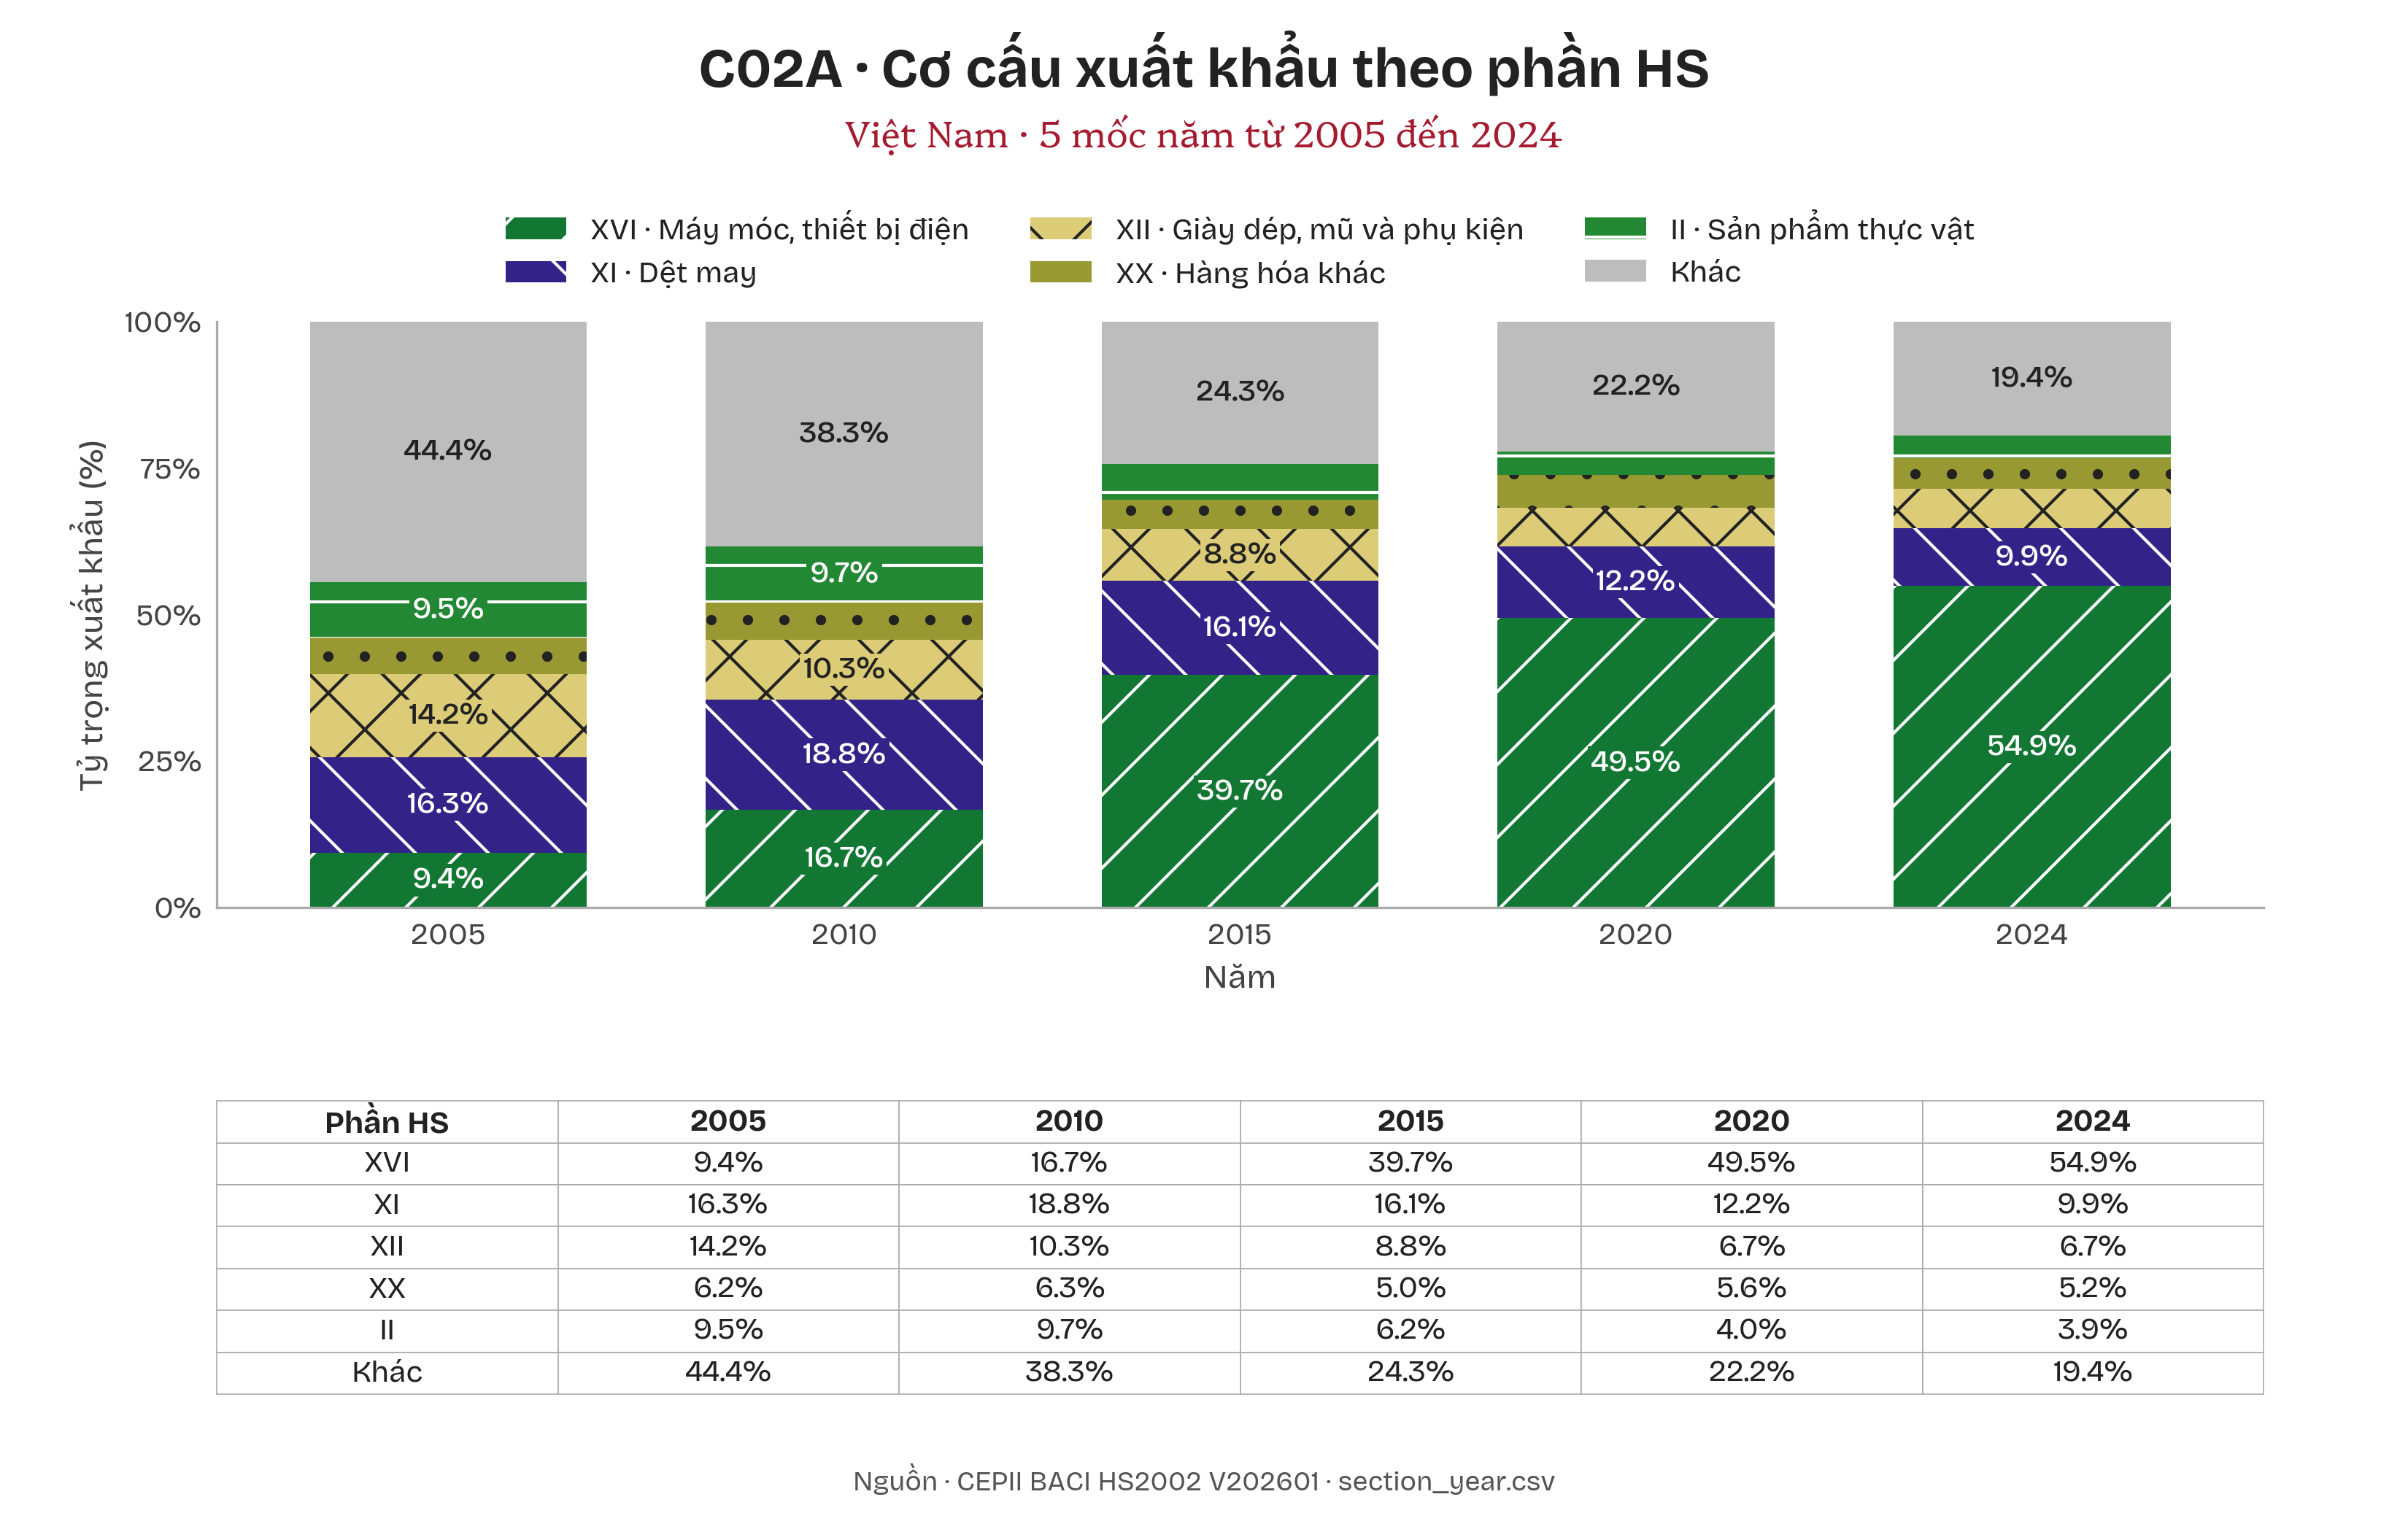

In [10]:
OUTPUT_DIR = ROOT / "outputs" / "core_charts" / "C02"


def save_figure(fig, name, output_dir=OUTPUT_DIR):
    """Save PNG and SVG using the shared export theme and return their paths."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    paths = tuple(output_dir / f"{name}.{extension}" for extension in ("png", "svg"))
    with apply_style(), rc_context({"svg.fonttype": "path"}):
        for path in paths:
            fig.savefig(path)
    return paths


MA_BIEU_DO = "C02A"
DU_LIEU = DATA_DIR
THU_MUC_ANH = OUTPUT_DIR

data, groups, shares = xu_ly_c02a(DU_LIEU)
fig = plot_c02a(data)
assert len(groups) == 6
assert all(abs(sum(shares[year]) - 1) < 1e-12 for year in MILESTONES)
for i, bars in enumerate(fig.axes[0].containers):
    expected = tuple(float(shares[year][i]) for year in MILESTONES)
    assert all(abs(bar.get_height() - share) < 1e-12
               for bar, share in zip(bars, expected, strict=True))
assert len(fig.axes[0].containers) == len(groups)
print("Nhóm theo thứ tự:", ", ".join(groups))
print("Đã kiểm tra 5/5 cột có tổng tỷ trọng 100%.")
png, svg = save_figure(fig, MA_BIEU_DO, THU_MUC_ANH)
print("Đã lưu:", png.relative_to(ROOT), "và", svg.relative_to(ROOT))
display(Image(filename=str(png), width=900))

### Kết luận C02A

Phần XVI tăng từ **9.4%** năm 2005 lên **54.9%** năm 2024. Tỷ trọng nhóm Khác giảm từ **44.4%** xuống **19.4%**. Các tỷ trọng dùng tổng xuất khẩu của từng năm.

## C02B · Cơ cấu nhập khẩu theo phần HS

- **Task (Q1.2 mở rộng)** · So sánh cơ cấu nhập khẩu của Việt Nam giữa các phần HS qua 5 mốc 2005, 2010, 2015, 2020 và 2024.
- **Dạng** · Cột chồng 100% (*100% stacked column*), cùng quy cách trục và cách mã hóa màu theo phần HS như C02A.
- **Lý do** · Các cột cùng cao 100% giúp đọc trực tiếp mức thay đổi tỷ trọng của các nhóm nhập khẩu. Những phần xuất hiện trên cả C02A và C02B giữ cùng màu.
- **Xử lý** · Lọc `Import` ở 5 mốc và chọn Top 5 theo tổng nhập khẩu **XVI, XV, XI, VI, VII**. Gộp các phần còn lại vào **Khác**. Chia kim ngạch mỗi nhóm cho tổng nhập khẩu cùng năm, nhân 100. Kiểm tra mỗi cột cộng thành 100% trước khi làm tròn.

**Nguồn** · `data/clean/section_year.csv`, CEPII BACI HS2002 V202601.

In [11]:
def xu_ly_c02b(data_dir):
    """Chuẩn bị Top 5 nhập khẩu và tỷ trọng từng nhóm tại 5 mốc."""
    data = tai_du_lieu(data_dir)
    groups = data.import_groups
    shares = {year: tuple(data.share(year, "Import", group) for group in groups)
              for year in MILESTONES}
    return data, groups, shares

In [12]:
def plot_c02b(data):
    """Return the 100% stacked import composition figure."""
    with apply_style():
        return composition(data, "Import", "C02B · Cơ cấu nhập khẩu theo phần HS")

Nhóm theo thứ tự: XVI, XV, XI, VI, VII, Other
Đã kiểm tra 5/5 cột có tổng tỷ trọng 100%.
Đã lưu: outputs\core_charts\C02\C02B.png và outputs\core_charts\C02\C02B.svg


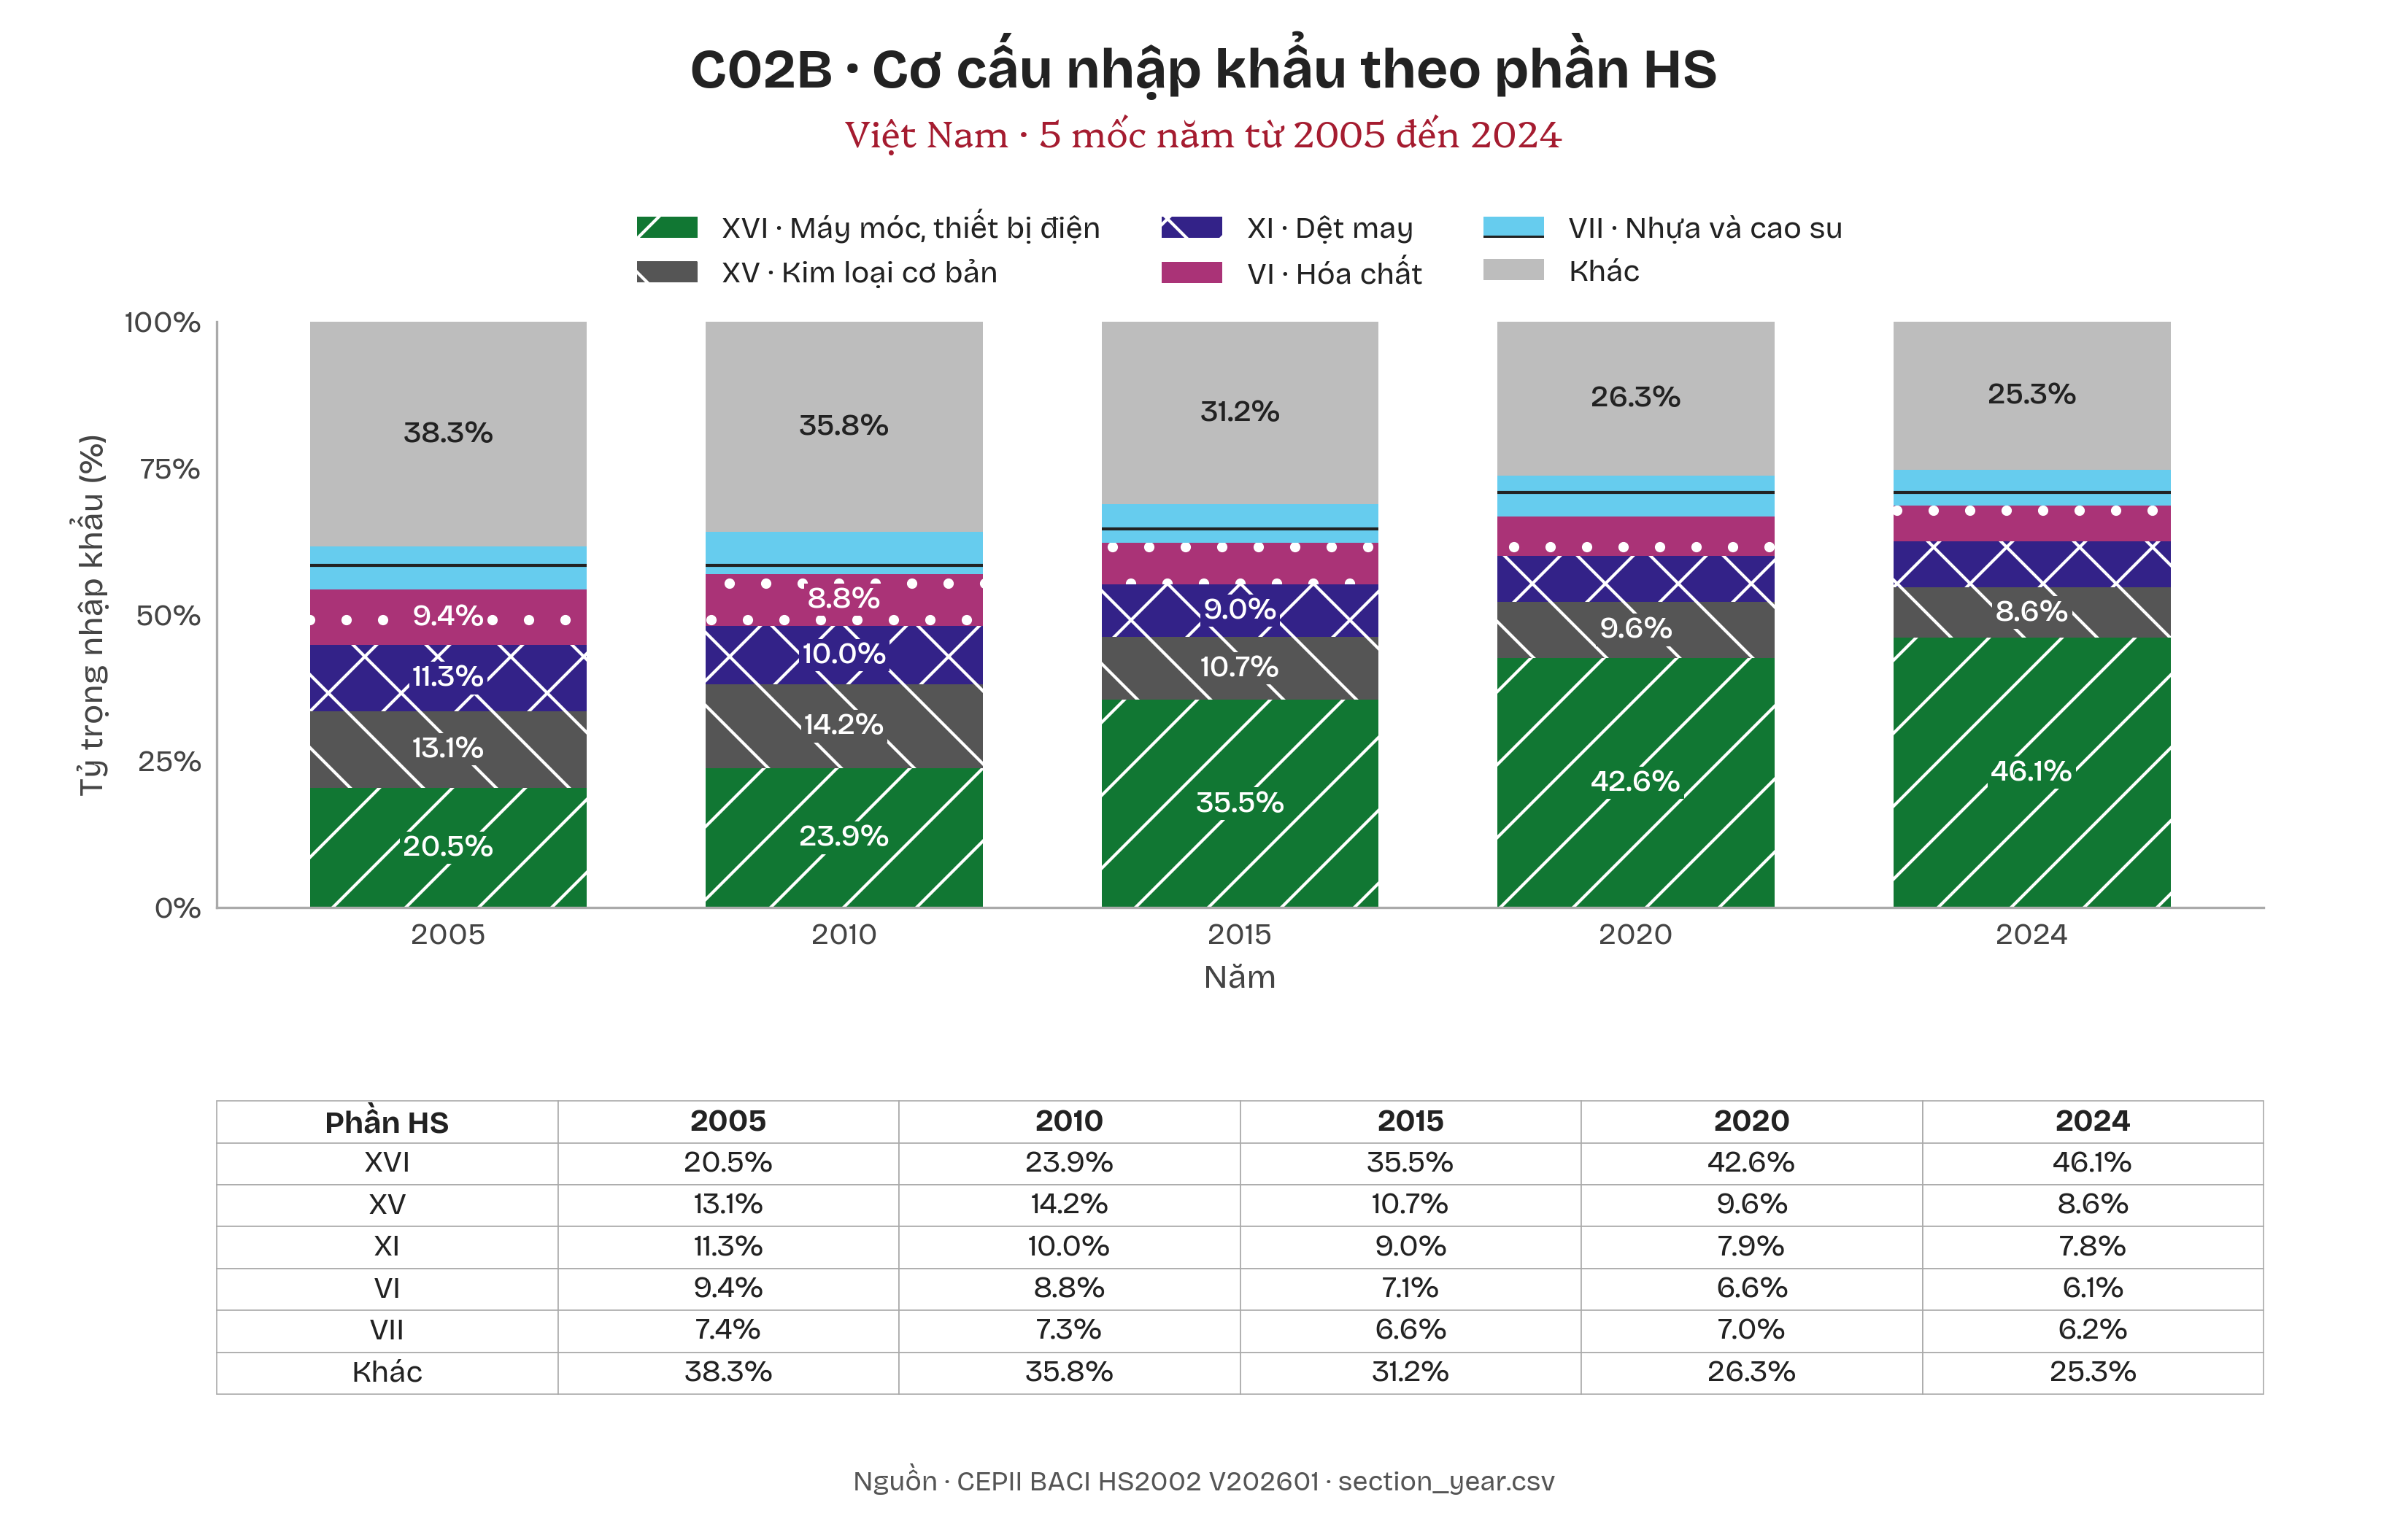

In [13]:
MA_BIEU_DO = "C02B"
DU_LIEU = DATA_DIR
THU_MUC_ANH = OUTPUT_DIR

data, groups, shares = xu_ly_c02b(DU_LIEU)
fig = plot_c02b(data)
assert len(groups) == 6
assert all(abs(sum(shares[year]) - 1) < 1e-12 for year in MILESTONES)
for i, bars in enumerate(fig.axes[0].containers):
    expected = tuple(float(shares[year][i]) for year in MILESTONES)
    assert all(abs(bar.get_height() - share) < 1e-12
               for bar, share in zip(bars, expected, strict=True))
assert len(fig.axes[0].containers) == len(groups)
print("Nhóm theo thứ tự:", ", ".join(groups))
print("Đã kiểm tra 5/5 cột có tổng tỷ trọng 100%.")
png, svg = save_figure(fig, MA_BIEU_DO, THU_MUC_ANH)
print("Đã lưu:", png.relative_to(ROOT), "và", svg.relative_to(ROOT))
display(Image(filename=str(png), width=900))

### Kết luận C02B

Phần XVI tăng từ **20.5%** lên **46.1%** nhập khẩu. Nhóm Khác giảm từ **38.3%** xuống **25.3%**. Nhóm Khác của nhập khẩu được xác định theo Top 5 nhập khẩu.

## C02C · Kim ngạch xuất khẩu theo phần HS

- **Task (Q1.2 bổ trợ)** · Phân tích xu hướng kim ngạch xuất khẩu của từng nhóm phần HS trong giai đoạn 2005–2024.
- **Dạng** · Biểu đồ nhiều đường (*multi-line chart*). Một ô có 6 đường, tương ứng Top 5 xuất khẩu và **Khác**.
- **Lý do** · Kim ngạch tuyệt đối giúp nhận ra nhóm có giá trị xuất khẩu tăng dù tỷ trọng giảm. C02C và C02D dùng chung thang dọc để so trực tiếp quy mô.
- **Xử lý** · Lọc `Export` cho đủ 20 năm và giữ Top 5 từ C02A. Gộp các phần còn lại theo từng năm, kiểm tra tổng trước và sau khi gộp, rồi chia kim ngạch USD cho 1 tỷ để vẽ.

**Nguồn** · `data/clean/section_year.csv`, CEPII BACI HS2002 V202601.

In [14]:
def xu_ly_c02c(data_dir):
    """Lấy chuỗi tỷ USD theo từng nhóm và giữ số USD để đối chiếu tổng."""
    data = tai_du_lieu(data_dir)
    groups, values = data.groups, data.sections
    usd = tuple(tuple(values[year, "Export", group] for year in YEARS) for group in groups)
    return data, groups, usd

In [15]:
def format_value(usd):
    return format_number(float(usd / 1_000_000_000), 1)


def value_axis(ax, limit, ylabel):
    ax.set(xlim=(YEARS[0], YEARS[-1]), ylim=(0, limit), xlabel="Năm", ylabel=ylabel)
    ax.set_xticks(MILESTONES, [format_year(year) for year in MILESTONES])
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: format_number(value)))


def section_trends(data, flow, title):
    fig = Figure(figsize=(11, 10))
    ax, table = fig.subplots(2, gridspec_kw={"height_ratios": (3, 3.7)})
    fig.subplots_adjust(left=.09, right=.94, bottom=.075, top=.83, hspace=.31)
    heading(fig, title, "2005–2024", "section_year.csv")
    groups, values = (data.groups, data.sections) if flow == "Export" else (data.import_groups, data.import_sections)
    export_peak = max(v for (_, direction, _), v in data.sections.items() if direction == "Export")
    limit = float(max(export_peak, max(data.import_sections.values())) / 1_000_000_000) * 1.08
    for group, marker in zip(groups, HS_MARKS):
        ax.plot(YEARS, [float(values[y, flow, group] / 1_000_000_000) for y in YEARS],
                color=HS_COLORS[group], marker=marker, label=HS_LABELS[group])
    value_axis(ax, limit, f"{TRADE_FLOW_LABELS[flow]} (tỷ USD)")
    legend_above(ax)
    rows = [[format_year(y), *[format_value(values[y, flow, code]) for code in groups]] for y in YEARS]
    add_table(table, ["Năm", *map(section_heading, groups)], rows)
    return fig


def plot_c02c(data):
    """Return the six-series export figure."""
    with apply_style():
        return section_trends(data, "Export", "C02C · Kim ngạch xuất khẩu theo phần HS")

Nhóm theo thứ tự: XVI, XI, XII, XX, II, Other
Đã kiểm tra 120 điểm và 20/20 tổng năm từ 2005 đến 2024.
Đã lưu: outputs\core_charts\C02\C02C.png và outputs\core_charts\C02\C02C.svg


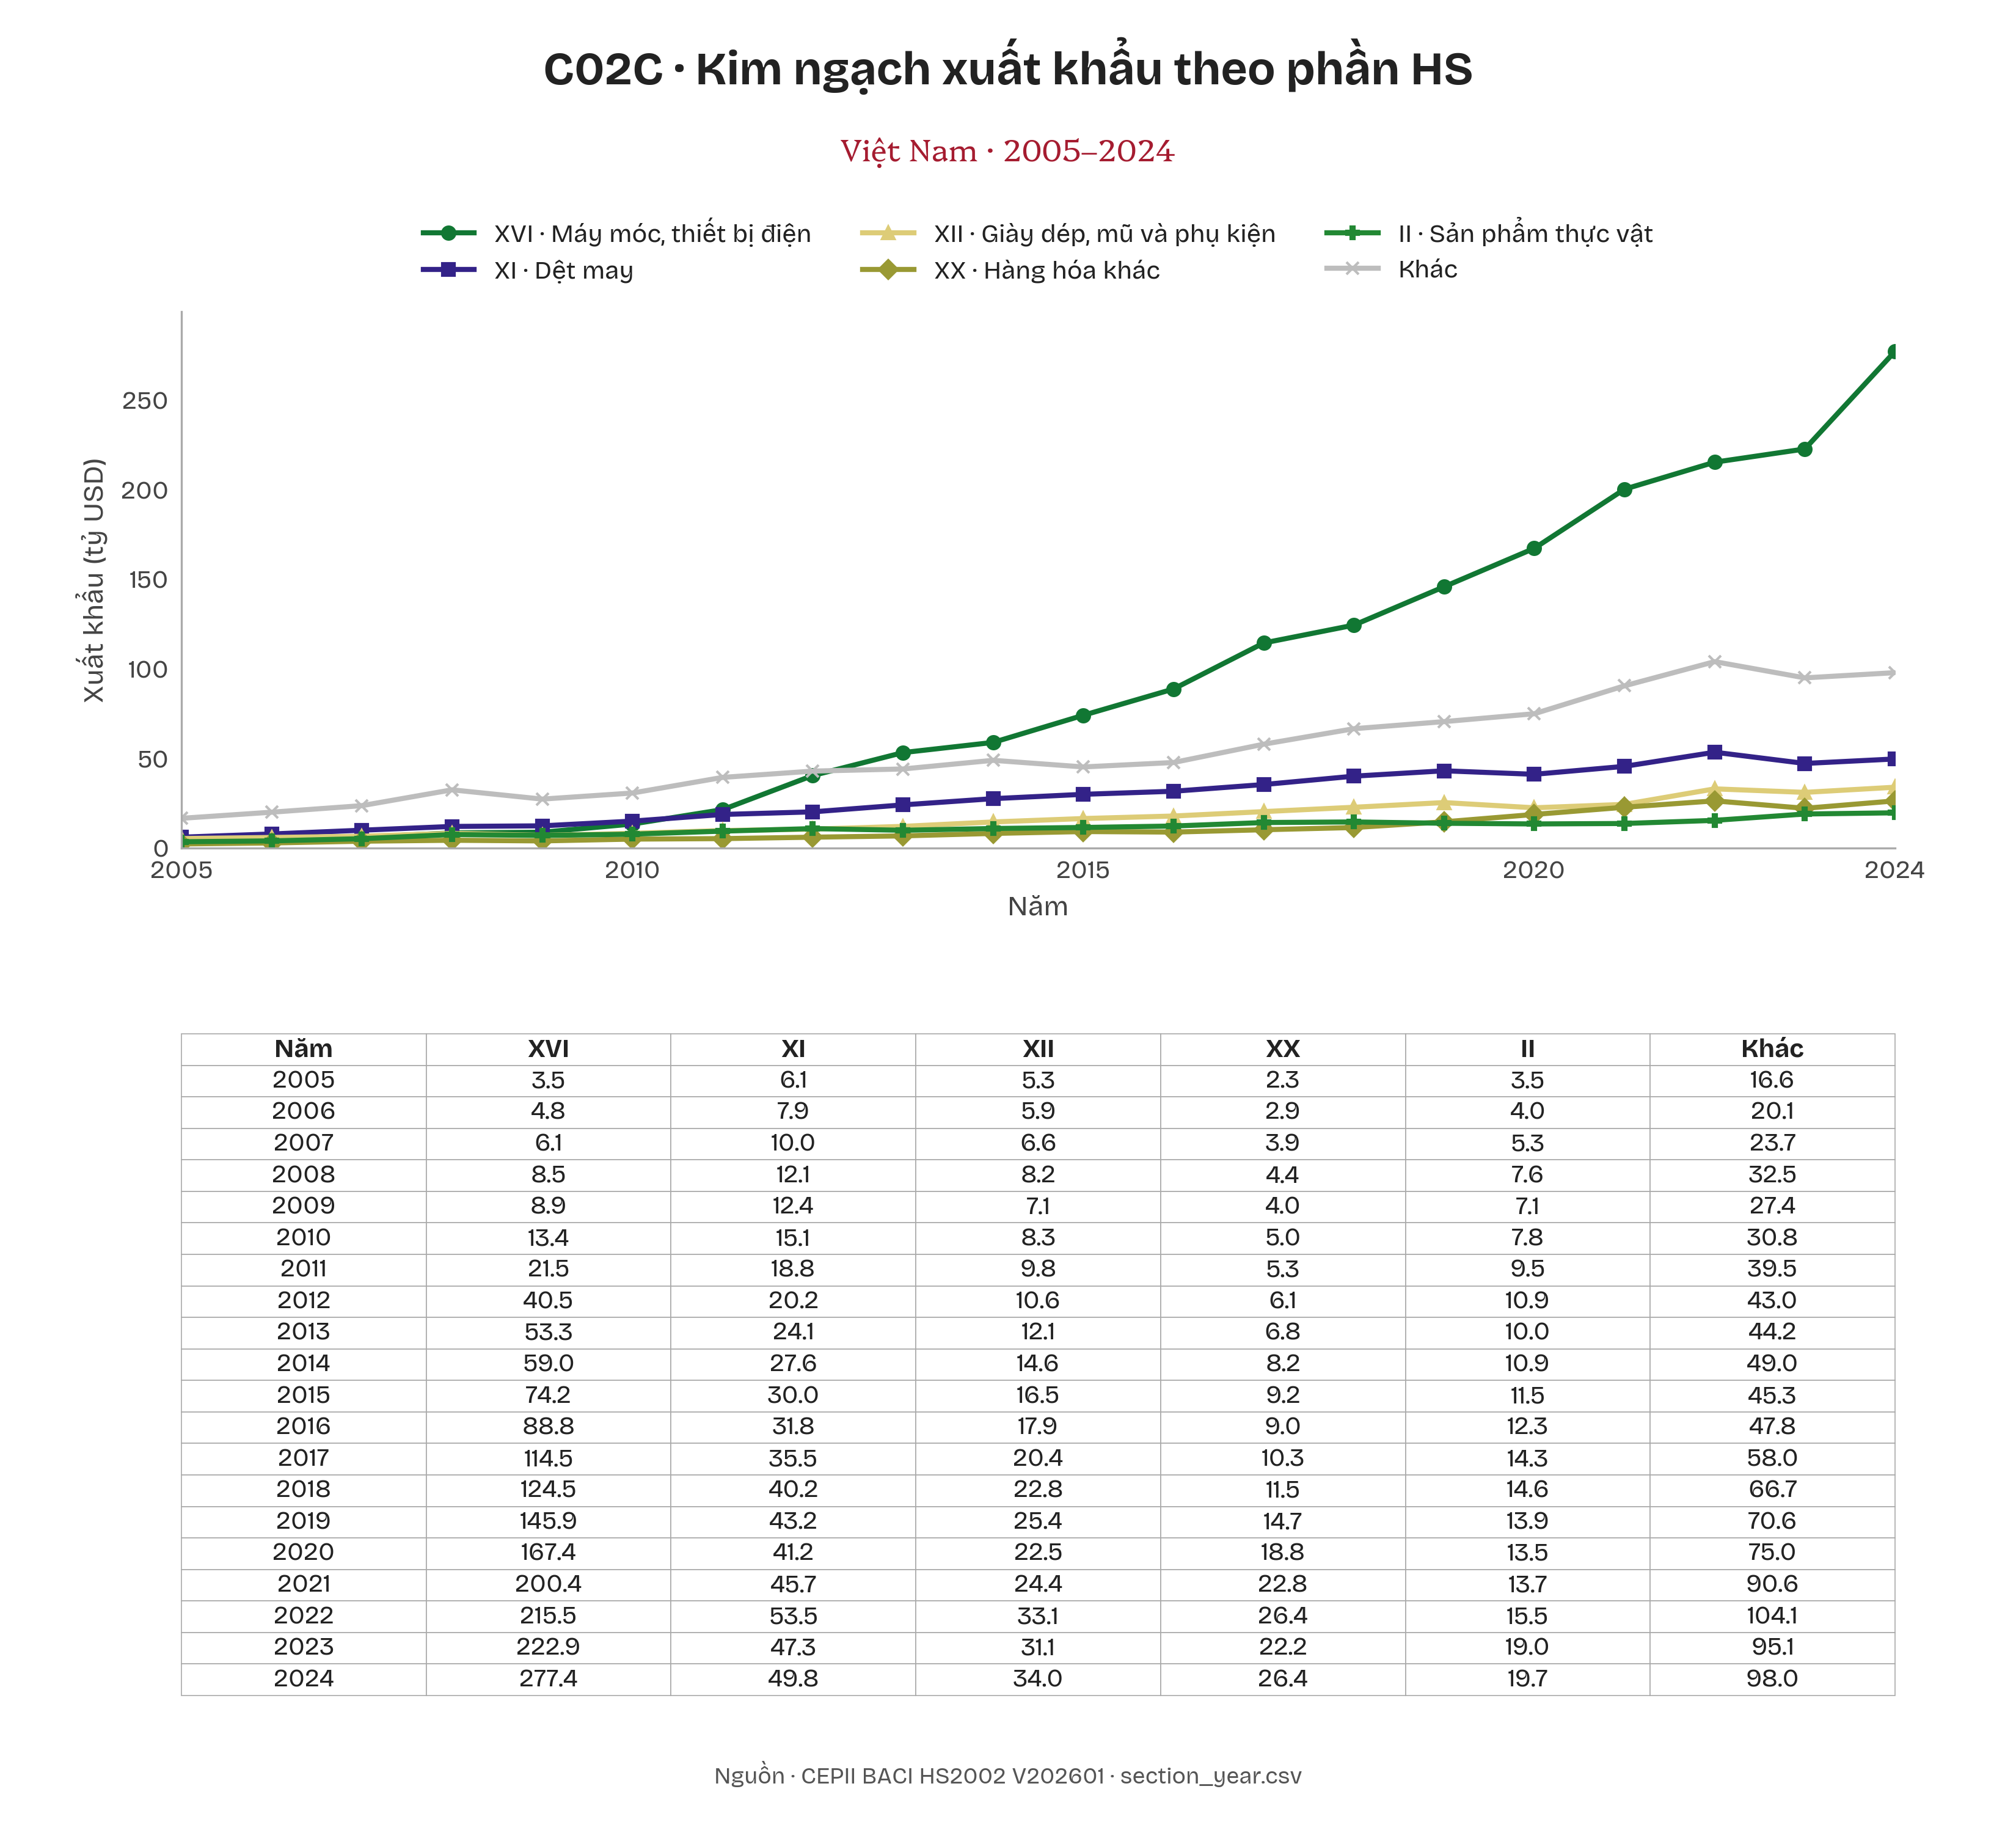

In [16]:
def kiem_tra_duong(ax, chuoi):
    """Đối chiếu từng điểm trên Figure với chuỗi tỷ USD đã xử lý."""
    for line, expected in zip(ax.lines, chuoi, strict=True):
        assert tuple(line.get_xdata()) == YEARS
        assert tuple(line.get_ydata()) == expected


MA_BIEU_DO = "C02C"
DU_LIEU = DATA_DIR
THU_MUC_ANH = OUTPUT_DIR

data, groups, usd = xu_ly_c02c(DU_LIEU)
fig = plot_c02c(data)
assert len(groups) == 6
assert all(sum(column) == data.totals[year, "Export"]
           for year, column in zip(YEARS, zip(*usd, strict=True), strict=True))
kiem_tra_duong(fig.axes[0], tuple(tuple(float(value / 10**9) for value in row) for row in usd))
print("Nhóm theo thứ tự:", ", ".join(groups))
print(f"Đã kiểm tra 120 điểm và 20/20 tổng năm từ {format_year(YEARS[0])} đến {format_year(YEARS[-1])}.")
png, svg = save_figure(fig, MA_BIEU_DO, THU_MUC_ANH)
print("Đã lưu:", png.relative_to(ROOT), "và", svg.relative_to(ROOT))
display(Image(filename=str(png), width=900))

### Kết luận C02C

Kim ngạch xuất khẩu dệt may (XI) tăng từ **6.1** lên **49.8 tỷ USD**, dù tỷ trọng giảm từ **16.3%** xuống **9.9%**. Kim ngạch và tỷ trọng trả lời hai câu hỏi khác nhau.

## C02D · Kim ngạch nhập khẩu theo phần HS

- **Task (Q1.2 bổ trợ)** · Phân tích xu hướng kim ngạch nhập khẩu của từng nhóm phần HS trong giai đoạn 2005–2024.
- **Dạng** · Biểu đồ nhiều đường (*multi-line chart*). Một ô có 6 đường, tương ứng Top 5 nhập khẩu và **Khác**.
- **Lý do** · Đường theo năm cho thấy quy mô và biến động nhập khẩu mà tỷ trọng ở C02B có thể che khuất. Dùng cùng thang dọc với C02C để so kim ngạch của các phần xuất hiện trên cả hai hình.
- **Xử lý** · Lọc `Import` cho đủ 20 năm và giữ Top 5 từ C02B. Gộp các phần còn lại theo từng năm, kiểm tra tổng trước và sau khi gộp, rồi chia kim ngạch USD cho 1 tỷ để vẽ.

**Nguồn** · `data/clean/section_year.csv`, CEPII BACI HS2002 V202601.

In [17]:
def xu_ly_c02d(data_dir):
    """Lấy chuỗi tỷ USD theo từng nhóm và giữ số USD để đối chiếu tổng."""
    data = tai_du_lieu(data_dir)
    groups, values = data.import_groups, data.import_sections
    usd = tuple(tuple(values[year, "Import", group] for year in YEARS) for group in groups)
    return data, groups, usd

In [18]:
def plot_c02d(data):
    """Return the six-series import figure."""
    with apply_style():
        return section_trends(data, "Import", "C02D · Kim ngạch nhập khẩu theo phần HS")

Nhóm theo thứ tự: XVI, XV, XI, VI, VII, Other
Đã kiểm tra 120 điểm và 20/20 tổng năm từ 2005 đến 2024.
Đã lưu: outputs\core_charts\C02\C02D.png và outputs\core_charts\C02\C02D.svg


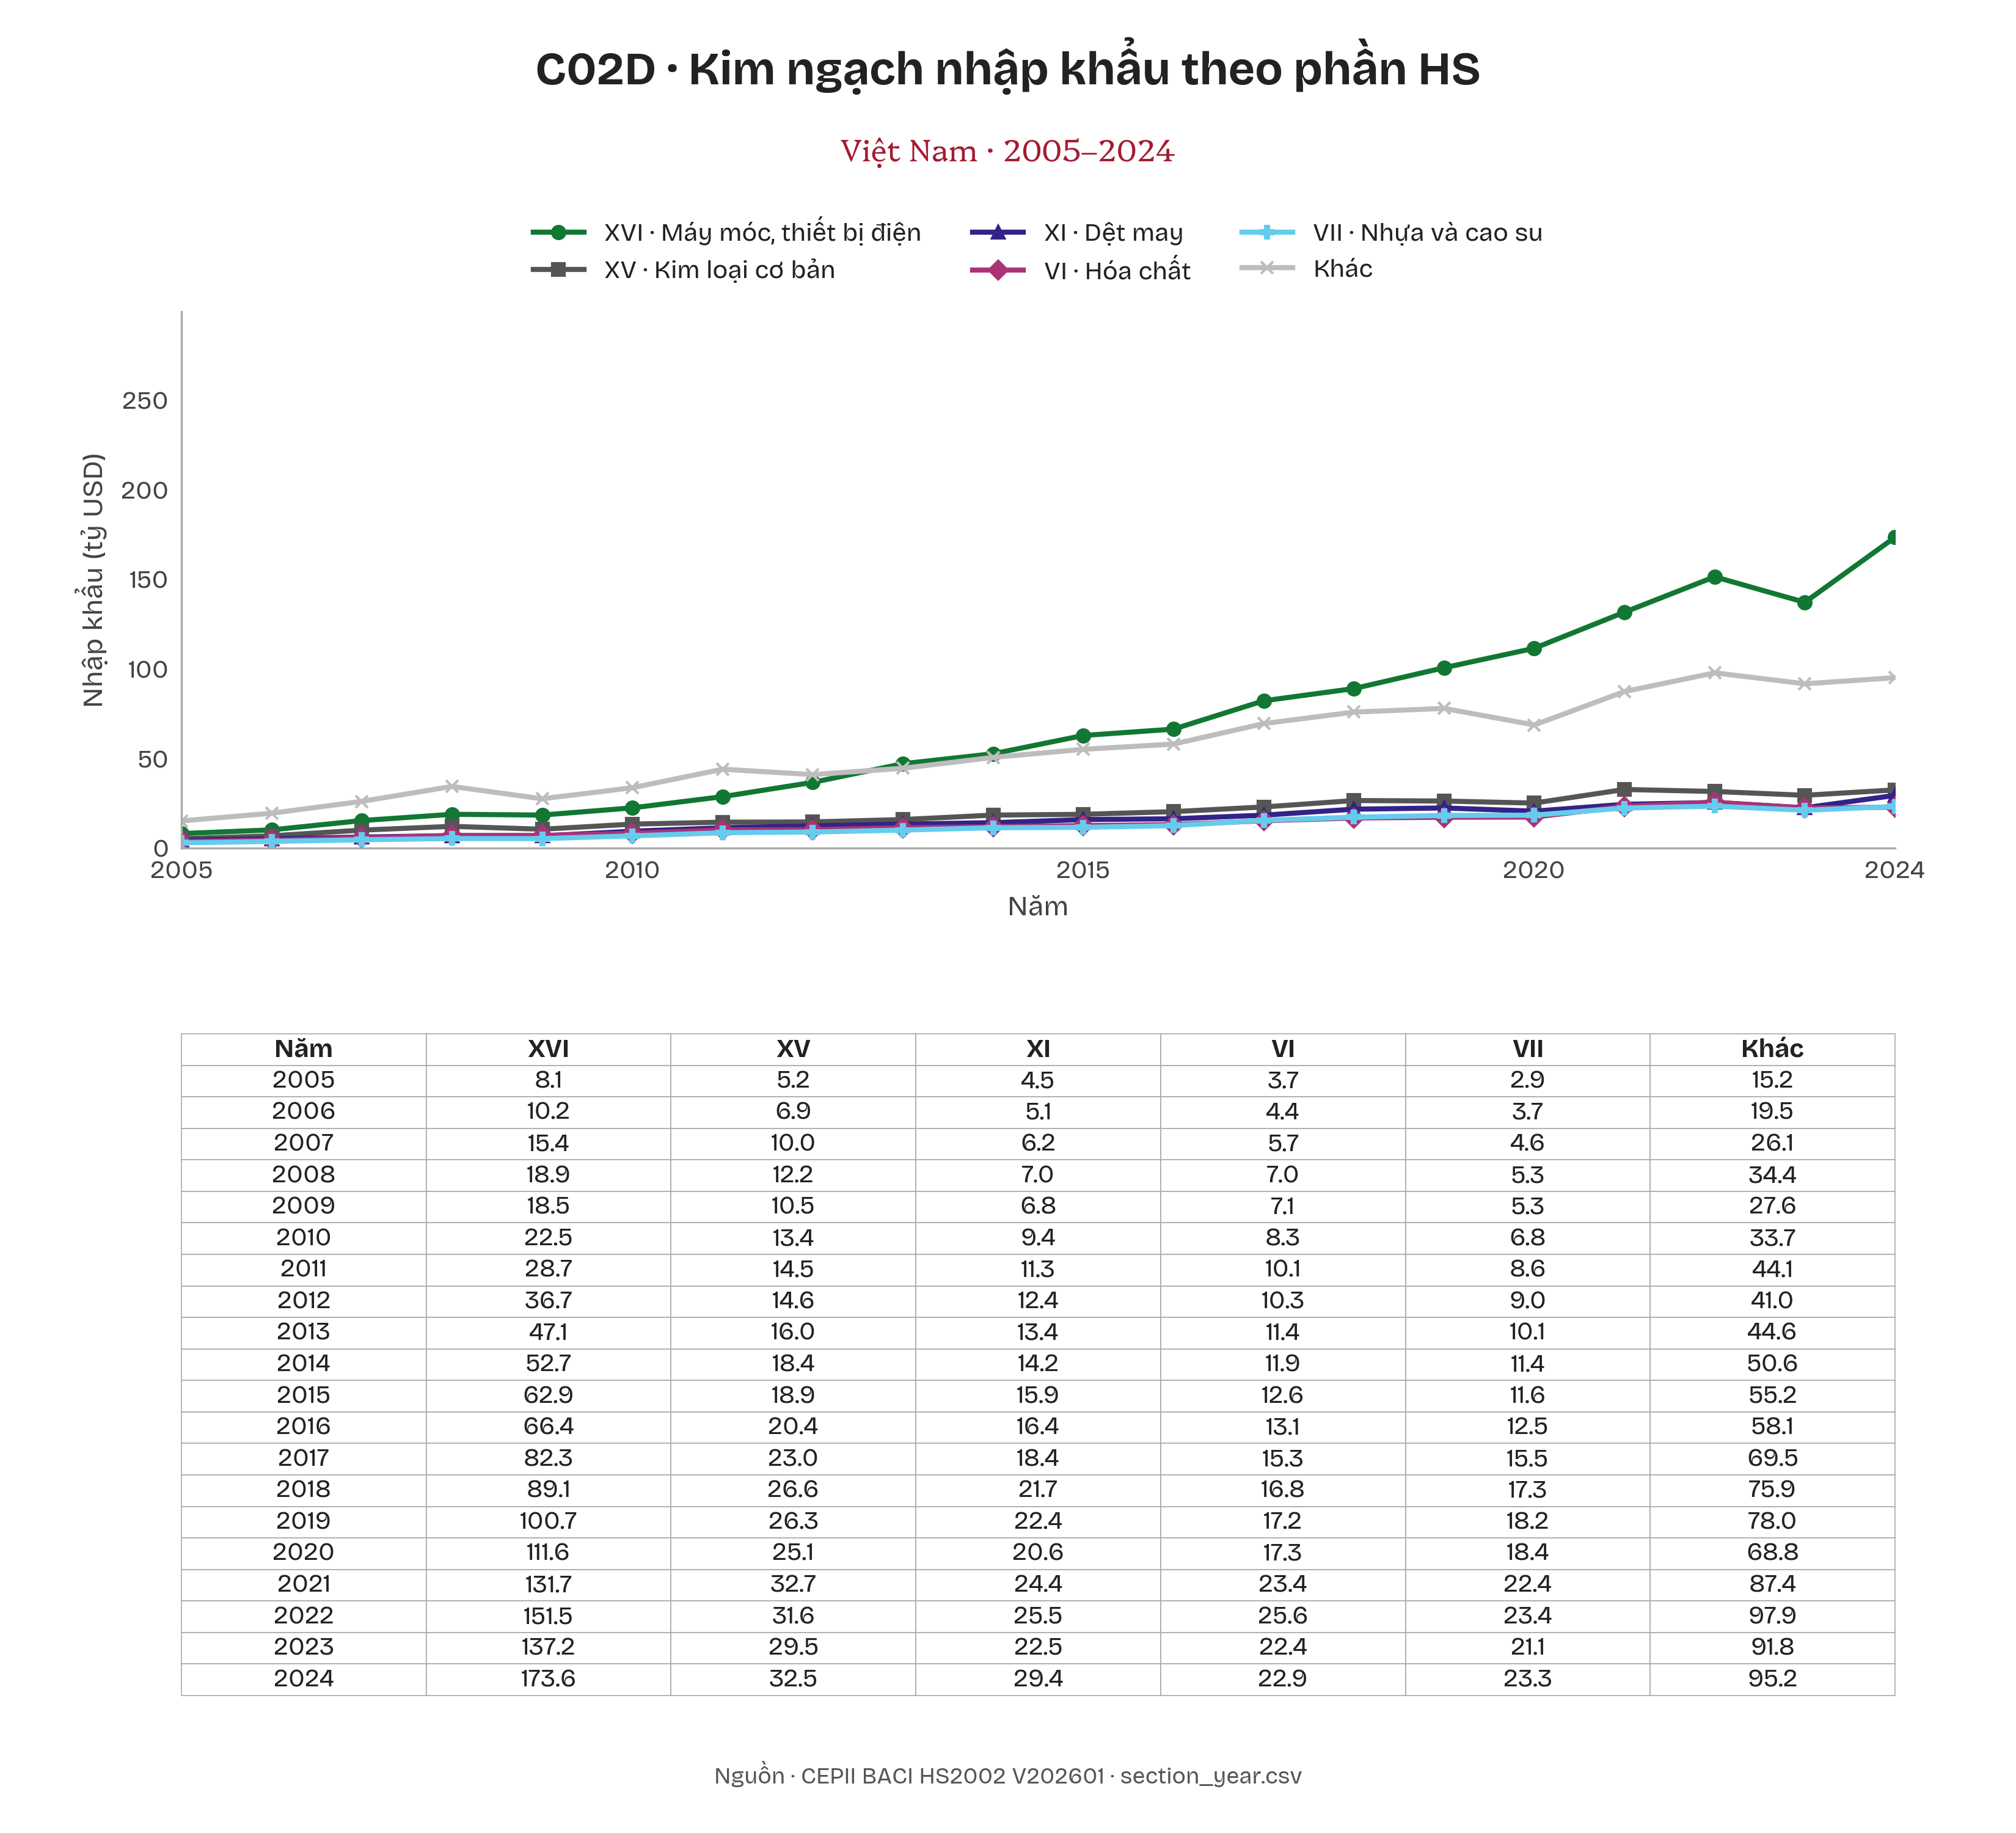

In [19]:
MA_BIEU_DO = "C02D"
DU_LIEU = DATA_DIR
THU_MUC_ANH = OUTPUT_DIR

data, groups, usd = xu_ly_c02d(DU_LIEU)
fig = plot_c02d(data)
assert len(groups) == 6
assert all(sum(column) == data.totals[year, "Import"]
           for year, column in zip(YEARS, zip(*usd, strict=True), strict=True))
kiem_tra_duong(fig.axes[0], tuple(tuple(float(value / 10**9) for value in row) for row in usd))
assert fig.axes[0].get_ylim() == plot_c02c(data).axes[0].get_ylim()
print("Nhóm theo thứ tự:", ", ".join(groups))
print(f"Đã kiểm tra 120 điểm và 20/20 tổng năm từ {format_year(YEARS[0])} đến {format_year(YEARS[-1])}.")
png, svg = save_figure(fig, MA_BIEU_DO, THU_MUC_ANH)
print("Đã lưu:", png.relative_to(ROOT), "và", svg.relative_to(ROOT))
display(Image(filename=str(png), width=900))

### Kết luận C02D

Nhập khẩu phần XVI tăng từ **8.1** lên **173.6 tỷ USD** giữa 2005 và 2024. Nhóm Khác đạt **95.2 tỷ USD** năm 2024 theo cách gộp của chiều nhập khẩu.

## C02E · Xuất nhập khẩu của HS84 và HS85

- **Task (Q1.4)** · So sánh kim ngạch xuất khẩu và nhập khẩu của từng chương HS84 và HS85 trong giai đoạn 2005–2024.
- **Dạng** · Biểu đồ đường hai ô (*small multiples line*). Mỗi chương một ô, mỗi ô có hai đường xuất khẩu và nhập khẩu.
- **Lý do** · Hai đường giúp thấy chiều nào có kim ngạch lớn hơn trong từng chương. Dùng chung thang dọc để đối chiếu quy mô và khoảng cách xuất–nhập giữa hai chương.
- **Xử lý** · Lọc `hs2` là chuỗi `"84"` hoặc `"85"`, giữ `Export` và `Import` đủ 20 năm. Chia `trade_usd` cho 1 tỷ để vẽ. Khi đọc chênh lệch, lấy xuất khẩu trừ nhập khẩu trên số gốc rồi mới làm tròn.

**Nguồn** · `data/clean/product_year.csv`, CEPII BACI HS2002 V202601.

In [20]:
def xu_ly_c02e(data_dir):
    """Lấy hai chuỗi XK/NK cho từng chương HS84 và HS85."""
    data = tai_du_lieu(data_dir)
    series = {code: tuple(tuple(float(data.products[year, flow, code] / 10**9)
                                for year in YEARS)
                          for flow in TRADE_FLOW_ORDER)
              for code in CHAPTERS}
    return data, series

In [21]:
def plot_c02e(data):
    """Return the two-panel trade-flow figure for HS84 and HS85."""
    with apply_style():
        fig = Figure(figsize=(11, 12))
        axes = fig.subplots(2, 2, sharey="row", gridspec_kw={"height_ratios": (3, 4.2)})
        fig.subplots_adjust(left=.09, right=.94, bottom=.085, top=.79, hspace=.35, wspace=.2)
        heading(fig, "C02E · Kim ngạch xuất nhập khẩu HS84 và HS85", "2005–2024", "product_year.csv")
        limit = float(max(v for (_, _, code), v in data.products.items() if code in CHAPTERS) / 1_000_000_000) * 1.08
        for code, ax, table in zip(CHAPTERS, *axes):
            ax.set_title(f"HS{code}")
            for flow in TRADE_FLOW_ORDER:
                ax.plot(YEARS, [float(data.products[y, flow, code] / 1_000_000_000) for y in YEARS],
                        color=TRADE_FLOW_COLORS[flow], linestyle=TRADE_FLOW_LINESTYLES[flow],
                        marker=TRADE_FLOW_MARKERS[flow], label=TRADE_FLOW_LABELS[flow])
            value_axis(ax, limit, "Kim ngạch (tỷ USD)" if code == CHAPTERS[0] else "")
            rows = [[format_year(y), *[format_value(data.products[y, flow, code]) for flow in TRADE_FLOW_ORDER]] for y in YEARS]
            add_table(table, ["Năm", *[TRADE_FLOW_LABELS[f] for f in TRADE_FLOW_ORDER]], rows)
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(handles, labels, ncols=2, loc="upper center", bbox_to_anchor=(.5, .88))
        return fig

Đã kiểm tra 80 điểm và chung thang dọc cho HS84 và HS85.
Đã lưu: outputs\core_charts\C02\C02E.png và outputs\core_charts\C02\C02E.svg


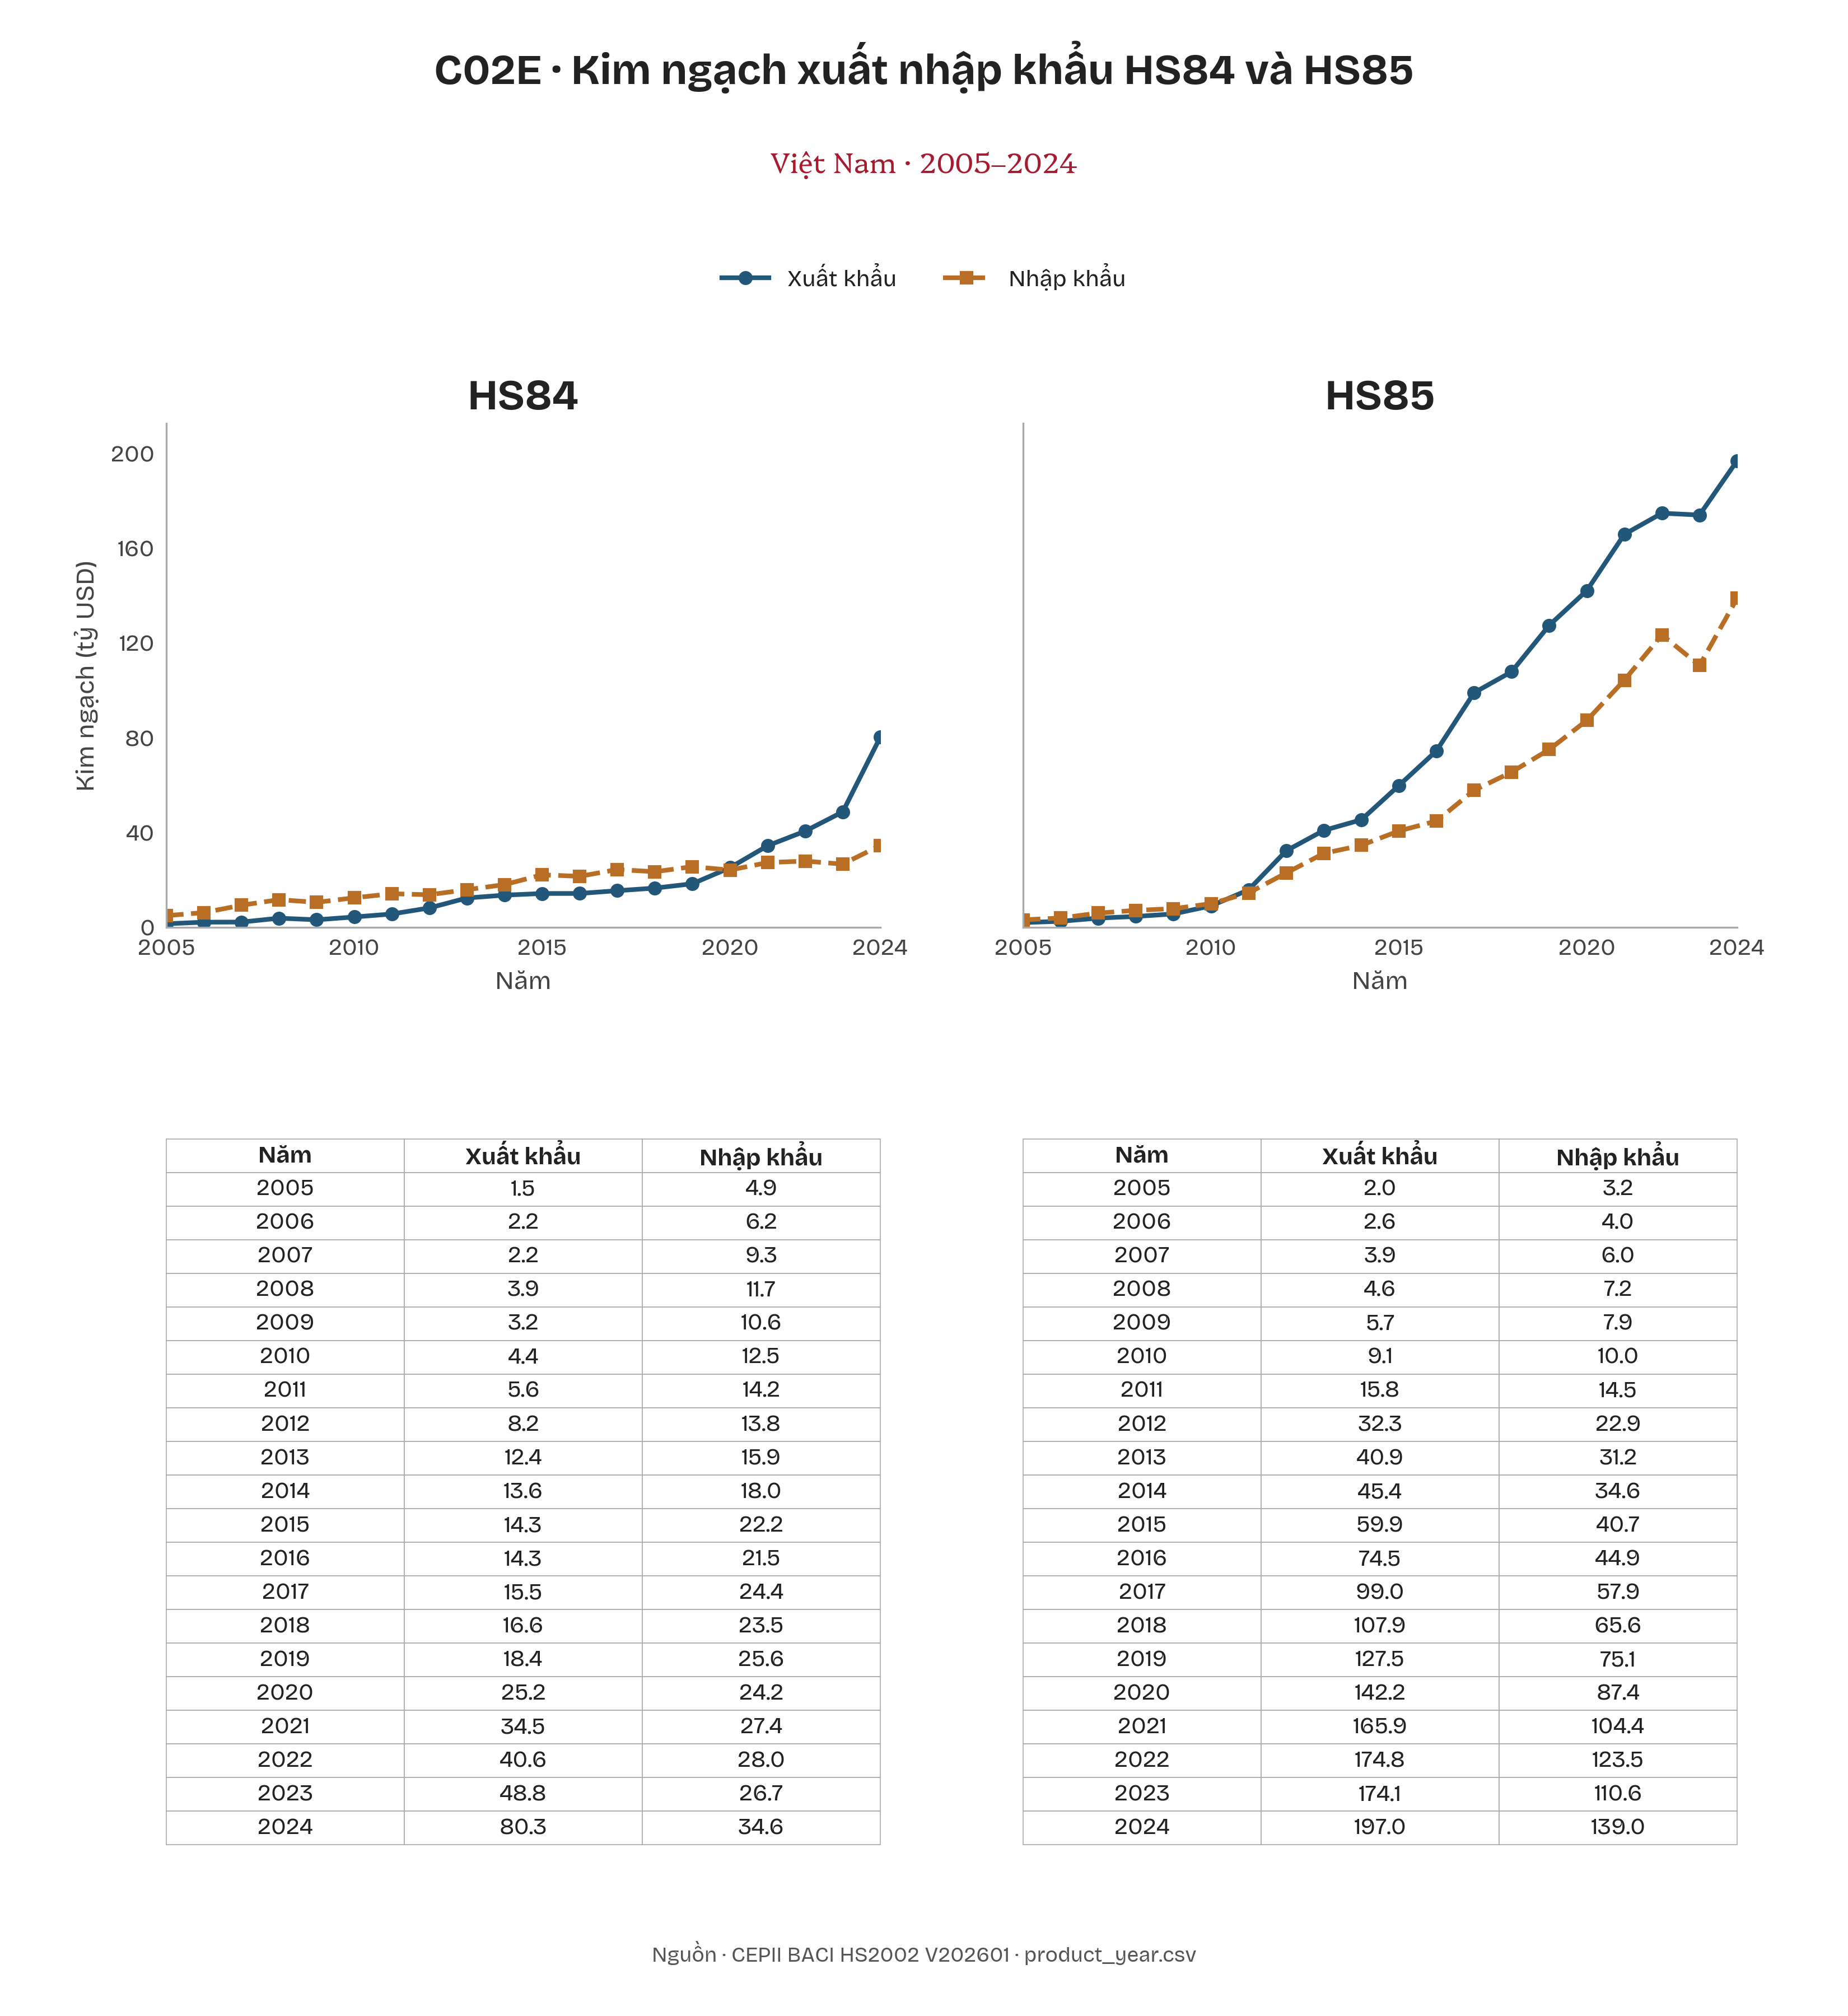

In [22]:
MA_BIEU_DO = "C02E"
DU_LIEU = DATA_DIR
THU_MUC_ANH = OUTPUT_DIR

data, series = xu_ly_c02e(DU_LIEU)
fig = plot_c02e(data)
axes = fig.axes[:2]
for code, ax in zip(CHAPTERS, axes, strict=True):
    assert ax.get_title() == f"HS{code}"
    kiem_tra_duong(ax, series[code])
assert axes[0].get_ylim() == axes[1].get_ylim()
print("Đã kiểm tra 80 điểm và chung thang dọc cho HS84 và HS85.")
png, svg = save_figure(fig, MA_BIEU_DO, THU_MUC_ANH)
print("Đã lưu:", png.relative_to(ROOT), "và", svg.relative_to(ROOT))
display(Image(filename=str(png), width=900))

### Kết luận C02E

Năm 2024, cả hai chương xuất siêu. Chênh lệch xuất khẩu trừ nhập khẩu là **45.8 tỷ USD** ở HS84 và **58.0 tỷ USD** ở HS85.

## C03A – Top 10 đối tác xuất khẩu năm 2024

- **Câu hỏi phụ** - Q2.1.
- **Task** - Xếp hạng 10 đối tác xuất khẩu lớn nhất năm 2024.
- **Dạng** - Thanh ngang xếp hạng.
- **Lý do** - Thanh ngang dễ đọc tên đối tác và so sánh kim ngạch theo thứ hạng.
- **Nguồn** - `data/clean/partner_year.csv`.

In [23]:
import pandas as pd

def lay_du_lieu_c03a(path, year, flow, top_n):
    """Lọc đối tác, tính tỷ trọng trên toàn bộ đối tác hợp lệ rồi lấy Top N."""
    data = pd.read_csv(path, dtype={"partner_iso3": "string"})
    valid = data["partner_iso3"].notna() & ~data["partner_iso3"].isin(["S19", "WLD"])
    selected = data.loc[data["year"].eq(year) & data["trade_flow"].eq(flow) & valid]
    partners = (selected.groupby("partner_iso3", as_index=False)
                .agg(partner_name=("partner_name", "first"),
                     trade_usd=("trade_usd", "sum"))
                .sort_values(["trade_usd", "partner_iso3"], ascending=[False, True]))
    total = partners["trade_usd"].sum()
    if total <= 0 or not 1 <= top_n <= len(partners):
        raise ValueError("Kiểm tra lại năm, chiều thương mại hoặc Top N.")
    partners["trade_billion_usd"] = partners["trade_usd"] / 1e9
    partners["share_pct"] = 100 * partners["trade_usd"] / total
    return partners.head(top_n).reset_index(drop=True)

In [24]:
import matplotlib.pyplot as plt

def ve_c03a(data, year, flow, color):
    """Vẽ thanh ngang từ 0 và tạo action title từ đối tác dẫn đầu."""
    label, verb = {"Export": ("xuất khẩu", "nhận"), "Import": ("nhập khẩu", "cung cấp")}[flow]
    names = {"USA": "Hoa Kỳ", "CHN": "Trung Quốc", "KOR": "Hàn Quốc", "JPN": "Nhật Bản",
             "HKG": "Hồng Kông", "DEU": "Đức", "MEX": "Mexico", "GBR": "Anh",
             "IND": "Ấn Độ", "CAN": "Canada", "SGP": "Singapore", "MYS": "Malaysia",
             "THA": "Thái Lan", "IDN": "Indonesia", "AUS": "Úc"}
    display_names = data["partner_iso3"].map(names).fillna(data["partner_name"])
    fig, ax = plt.subplots(figsize=(9, max(3.5, 0.36 * len(data) + 1.6)), layout="constrained")
    # Giữ từng đối tác riêng. Các mã ngoài bảng màu T10 dùng màu bối cảnh.
    colors = data["partner_iso3"].map(hs.PARTNER_COLORS).fillna(hs.OTHER_COLOR) if color is None else color
    bars = ax.barh(display_names, data["trade_billion_usd"], color=colors, height=hs.BAR_WIDTH)
    ax.invert_yaxis()
    ax.bar_label(bars, labels=[f"{hs.format_number(v, 1)} ({hs.format_percent(p / 100)})" for v, p in
                               zip(data["trade_billion_usd"], data["share_pct"])], padding=4)
    ax.set(xlim=(0, data["trade_billion_usd"].max() * 1.27), xlabel="Kim ngạch (tỷ USD)")
    ax.set_title(f"{display_names.iloc[0]} {verb} {hs.format_percent(data.iloc[0]['share_pct'] / 100)} tổng {label} năm {year}",
                 loc="center", fontweight="bold")
    hs.declutter(ax, quantitative_axis="x")
    fig.supxlabel("Nguồn: partner_year.csv", x=.99, **(hs.SOURCE | {"ha": "right"}))
    return fig, ax

        partner_name  trade_billion_usd  share_pct
                 USA              140.5       28.2
               China               94.0       18.9
       Rep. of Korea               28.4        5.7
               Japan               26.5        5.3
China, Hong Kong SAR               21.0        4.2
             Germany               15.4        3.1
              Mexico               13.2        2.7
      United Kingdom               10.8        2.2
               India               10.6        2.1
              Canada               10.4        2.1


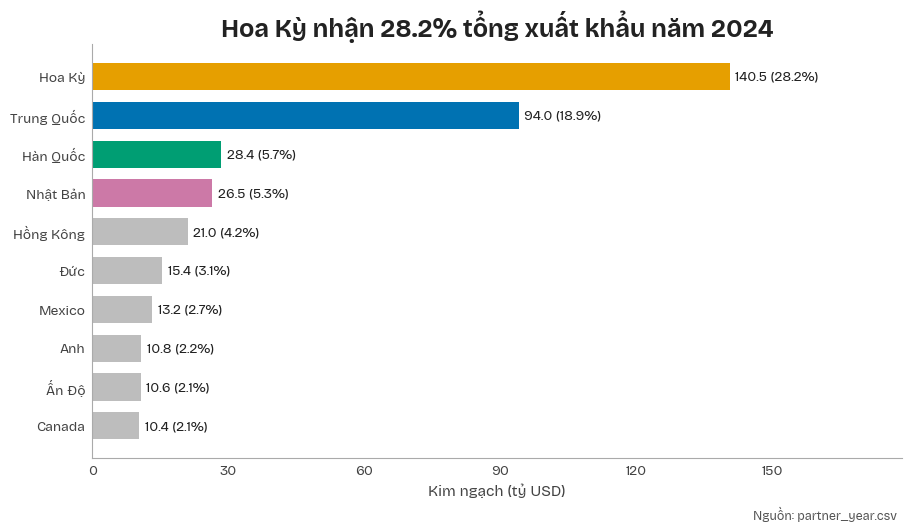

In [25]:
from pathlib import Path
import sys

year_c03a = 2024
flow_c03a = "Export"
top_n_c03a = 10
color_c03a = None  # None dùng màu T10 theo ISO3. Nhập mã hex để đổi sang một màu.

root_c03a = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/clean/partner_year.csv").is_file()),
    Path.cwd(),
)
style_dir_c03a = str(root_c03a / "notebooks")
if style_dir_c03a not in sys.path:
    sys.path.insert(0, style_dir_c03a)
from house_style import house_style as hs

df_c03a = lay_du_lieu_c03a(root_c03a / "data/clean/partner_year.csv",
                                year_c03a, flow_c03a, top_n_c03a)
assert len(df_c03a) == top_n_c03a and df_c03a["trade_usd"].is_monotonic_decreasing
assert df_c03a["share_pct"].sum() <= 100 + 1e-8
print(df_c03a[["partner_name", "trade_billion_usd", "share_pct"]].to_string(index=False, float_format=lambda x: f"{x:.1f}"))
with hs.apply_style():
    fig_c03a, ax_c03a = ve_c03a(df_c03a, year_c03a, flow_c03a, color_c03a)
    output_c03a = root_c03a / f"outputs/core_charts/C03/C03A_{year_c03a}.png"
    output_c03a.parent.mkdir(parents=True, exist_ok=True)
    fig_c03a.savefig(output_c03a, dpi=hs.THEME["savefig.dpi"])
    plt.show()


### Kết luận · C03A

**Action title** - Hoa Kỳ nhận 28.2% tổng xuất khẩu của Việt Nam năm 2024.

Đối tác dẫn đầu đạt **140.5 tỷ USD**. Tỷ trọng tính trên tổng kim ngạch của mọi đối tác hợp lệ trong cùng năm và chiều thương mại. Nhóm gộp Other Asia, nes (S19) được loại khỏi xếp hạng và mẫu số.

## C03B – Top 10 đối tác nhập khẩu năm 2024

- **Câu hỏi phụ** - Q2.1.
- **Task** - Xếp hạng 10 đối tác nhập khẩu lớn nhất năm 2024.
- **Dạng** - Thanh ngang xếp hạng.
- **Lý do** - Thanh ngang dễ đọc tên đối tác và so sánh kim ngạch theo thứ hạng.
- **Nguồn** - `data/clean/partner_year.csv`.

In [26]:
import pandas as pd

def lay_du_lieu_c03b(path, year, flow, top_n):
    """Lọc đối tác, tính tỷ trọng trên toàn bộ đối tác hợp lệ rồi lấy Top N."""
    data = pd.read_csv(path, dtype={"partner_iso3": "string"})
    valid = data["partner_iso3"].notna() & ~data["partner_iso3"].isin(["S19", "WLD"])
    selected = data.loc[data["year"].eq(year) & data["trade_flow"].eq(flow) & valid]
    partners = (selected.groupby("partner_iso3", as_index=False)
                .agg(partner_name=("partner_name", "first"),
                     trade_usd=("trade_usd", "sum"))
                .sort_values(["trade_usd", "partner_iso3"], ascending=[False, True]))
    total = partners["trade_usd"].sum()
    if total <= 0 or not 1 <= top_n <= len(partners):
        raise ValueError("Kiểm tra lại năm, chiều thương mại hoặc Top N.")
    partners["trade_billion_usd"] = partners["trade_usd"] / 1e9
    partners["share_pct"] = 100 * partners["trade_usd"] / total
    return partners.head(top_n).reset_index(drop=True)

In [27]:
import matplotlib.pyplot as plt

def ve_c03b(data, year, flow, color):
    """Vẽ thanh ngang từ 0 và tạo action title từ đối tác dẫn đầu."""
    label, verb = {"Export": ("xuất khẩu", "nhận"), "Import": ("nhập khẩu", "cung cấp")}[flow]
    names = {"USA": "Hoa Kỳ", "CHN": "Trung Quốc", "KOR": "Hàn Quốc", "JPN": "Nhật Bản",
             "HKG": "Hồng Kông", "DEU": "Đức", "MEX": "Mexico", "GBR": "Anh",
             "IND": "Ấn Độ", "CAN": "Canada", "SGP": "Singapore", "MYS": "Malaysia",
             "THA": "Thái Lan", "IDN": "Indonesia", "AUS": "Úc"}
    display_names = data["partner_iso3"].map(names).fillna(data["partner_name"])
    fig, ax = plt.subplots(figsize=(9, max(3.5, 0.36 * len(data) + 1.6)), layout="constrained")
    # Giữ từng đối tác riêng. Các mã ngoài bảng màu T10 dùng màu bối cảnh.
    colors = data["partner_iso3"].map(hs.PARTNER_COLORS).fillna(hs.OTHER_COLOR) if color is None else color
    bars = ax.barh(display_names, data["trade_billion_usd"], color=colors, height=hs.BAR_WIDTH)
    ax.invert_yaxis()
    ax.bar_label(bars, labels=[f"{hs.format_number(v, 1)} ({hs.format_percent(p / 100)})" for v, p in
                               zip(data["trade_billion_usd"], data["share_pct"])], padding=4)
    ax.set(xlim=(0, data["trade_billion_usd"].max() * 1.27), xlabel="Kim ngạch (tỷ USD)")
    ax.set_title(f"{display_names.iloc[0]} {verb} {hs.format_percent(data.iloc[0]['share_pct'] / 100)} tổng {label} năm {year}",
                 loc="center", fontweight="bold")
    hs.declutter(ax, quantitative_axis="x")
    fig.supxlabel("Nguồn: partner_year.csv", x=.99, **(hs.SOURCE | {"ha": "right"}))
    return fig, ax

        partner_name  trade_billion_usd  share_pct
               China              158.8       43.8
       Rep. of Korea               58.3       16.1
China, Hong Kong SAR               19.7        5.4
           Singapore               17.0        4.7
               Japan               15.9        4.4
                 USA               12.6        3.5
            Malaysia               11.8        3.2
            Thailand               11.8        3.2
           Indonesia                9.5        2.6
           Australia                6.9        1.9


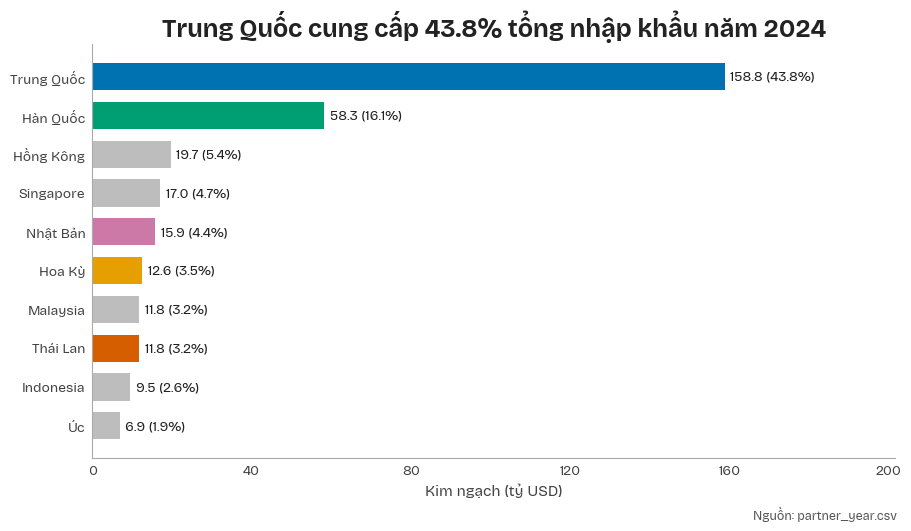

In [28]:
from pathlib import Path
import sys

year_c03b = 2024
flow_c03b = "Import"
top_n_c03b = 10
color_c03b = None  # None dùng màu T10 theo ISO3. Nhập mã hex để đổi sang một màu.

root_c03b = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/clean/partner_year.csv").is_file()),
    Path.cwd(),
)
style_dir_c03b = str(root_c03b / "notebooks")
if style_dir_c03b not in sys.path:
    sys.path.insert(0, style_dir_c03b)
from house_style import house_style as hs

df_c03b = lay_du_lieu_c03b(root_c03b / "data/clean/partner_year.csv",
                                year_c03b, flow_c03b, top_n_c03b)
assert len(df_c03b) == top_n_c03b and df_c03b["trade_usd"].is_monotonic_decreasing
assert df_c03b["share_pct"].sum() <= 100 + 1e-8
print(df_c03b[["partner_name", "trade_billion_usd", "share_pct"]].to_string(index=False, float_format=lambda x: f"{x:.1f}"))
with hs.apply_style():
    fig_c03b, ax_c03b = ve_c03b(df_c03b, year_c03b, flow_c03b, color_c03b)
    output_c03b = root_c03b / f"outputs/core_charts/C03/C03B_{year_c03b}.png"
    output_c03b.parent.mkdir(parents=True, exist_ok=True)
    fig_c03b.savefig(output_c03b, dpi=hs.THEME["savefig.dpi"])
    plt.show()


### Kết luận · C03B

**Action title** - Trung Quốc cung cấp 43.8% tổng nhập khẩu của Việt Nam năm 2024.

Đối tác dẫn đầu đạt **158.8 tỷ USD**. Tỷ trọng tính trên tổng kim ngạch của mọi đối tác hợp lệ trong cùng năm và chiều thương mại. Nhóm gộp Other Asia, nes (S19) được loại khỏi xếp hạng và mẫu số.

# C04 · Tỷ trọng đối tác thương mại

**Câu hỏi Q2.** Mức độ tập trung đối tác của Việt Nam thay đổi thế nào theo thời gian?

**Lâm Thanh Nghi** · Mở notebook trong dự án đã giải nén có cài các thư viện từ `requirements.txt` và chọn **Run All** để tạo hai hình.

Dùng quy tắc mã đối tác của bộ định dạng dự án. Loại nhóm BACI `490 / S19` (*Các nền kinh tế châu Á khác, chưa phân loại*) và mã tổng hợp khỏi cả bảng xếp hạng lẫn mẫu số. Tính tỷ trọng theo từng năm và từng chiều thương mại.

## C04A · Thay đổi tỷ trọng đối tác xuất khẩu

- **Task** · (Q2.2) So sánh tỷ trọng đối tác xuất khẩu năm 2005 và 2024.
- **Dạng** · Biểu đồ hai điểm nối ngang. Mỗi hàng là một đối tác.
- **Lý do** · Đo hướng và độ lớn thay đổi bằng điểm phần trăm.
- **Xử lý** · Chọn sáu đối tác theo tổng kim ngạch xuất khẩu ở hai mốc. Chia cho tổng xuất khẩu của toàn bộ đối tác hợp lệ cùng năm. Giữ cùng sáu đối tác tại hai mốc. Nếu một đối tác vắng mặt trong bảng của một năm, dùng 0 tại năm đó.

**Nguồn** · `data/clean/partner_year.csv`, CEPII BACI HS2002 V202601.

In [29]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import rc_context
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "notebooks/house_style/house_style.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook trong thư mục dự án đã giải nén.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from notebooks.house_style.house_style import (
    SOURCE, SUBTITLE, TRADE_FLOW_COLORS, TRADE_FLOW_LABELS,
    TRADE_FLOW_LINESTYLES, TRADE_FLOW_MARKERS, TRADE_FLOW_ORDER,
    apply_style, format_number, format_percent, format_percentage_points,
    is_partner_code,
)

DATA_DIR = ROOT / "data" / "clean"
YEARS = tuple(range(2005, 2025))

def tai_du_lieu(data_dir=DATA_DIR):
    raw = pd.read_csv(data_dir / "partner_year.csv",
                      dtype={"partner_code": str, "partner_iso3": str})
    valid = raw.partner_iso3.fillna("").map(is_partner_code)
    valid &= ~raw.partner_code.str.lstrip("0").isin(["", "999"])
    data = raw.loc[valid & raw.year.between(2005, 2024)
                   & raw.trade_flow.isin(TRADE_FLOW_ORDER)].copy()
    assert np.isfinite(data.trade_usd).all() and data.trade_usd.ge(0).all()
    keys = ["year", "trade_flow", "partner_code"]
    data = data.groupby(keys, as_index=False).agg(
        trade_usd=("trade_usd", "sum"), partner_iso3=("partner_iso3", "first"))
    totals = data.groupby(["year", "trade_flow"]).trade_usd.transform("sum")
    assert totals.gt(0).all()
    data["share"] = data.trade_usd / totals
    summed = data.groupby(["year", "trade_flow"]).share.sum()
    assert len(summed) == 40 and np.allclose(summed, 1, atol=1e-12, rtol=0)
    return data

partners = tai_du_lieu()

In [30]:
NAMES = {"USA": "Hoa Kỳ", "CHN": "Trung Quốc", "JPN": "Nhật Bản", "KOR": "Hàn Quốc",
         "HKG": "Hồng Kông (Trung Quốc)", "DEU": "Đức", "SGP": "Singapore", "THA": "Thái Lan"}

def xu_ly_c04(data, flow):
    rows = data.loc[data.year.isin([2005, 2024]) & data.trade_flow.eq(flow)]
    totals = rows.groupby("partner_code").trade_usd.sum()
    top = totals.sort_index().nlargest(6).index
    chosen = rows.loc[rows.partner_code.isin(top)]
    wide = chosen.pivot(index="partner_code", columns="year", values="share")
    wide = wide.reindex(index=top, columns=[2005, 2024]).fillna(0)
    iso = chosen.sort_values("year").drop_duplicates("partner_code", keep="last")
    iso = iso.set_index("partner_code").partner_iso3.reindex(top)
    wide.index = iso.map(NAMES).fillna(iso)
    wide.index.name = "Đối tác"
    wide["Thay đổi"] = 100 * (wide[2024] - wide[2005])
    return wide

def plot_c04(data, title, flow):
    with apply_style():
        fig = Figure(figsize=(10.5, 5.5))
        ax = fig.subplots()
        fig.subplots_adjust(left=.26, right=.95, top=.72, bottom=.18)
        trang_tri(fig, title, "Việt Nam · 2005 và 2024")
        y = np.arange(len(data))
        ax.hlines(y, data[[2005, 2024]].min(axis=1), data[[2005, 2024]].max(axis=1),
                  color="#8D959B", linewidth=1.5)
        for year, marker, fill, dy in [(2005, "o", "white", 7), (2024, "s", TRADE_FLOW_COLORS[flow], -7)]:
            values = data[year]
            ax.scatter(values, y, marker=marker, edgecolors=TRADE_FLOW_COLORS[flow],
                       facecolors=fill, label=str(year), zorder=3)
            for yi, value in zip(y, values):
                ax.annotate(format_percent(value), (value, yi), xytext=(0, dy),
                            textcoords="offset points", ha="center",
                            va="bottom" if year == 2005 else "top", fontsize=9)
        ax.set(yticks=y, yticklabels=data.index, ylim=(len(data) - .5, -.5),
               xlim=(0, .5), xticks=np.arange(6)/10, xlabel="Tỷ trọng (%)")
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: format_percent(v, 0)))
        ax.grid(axis="x", alpha=.25)
        handles, labels = ax.get_legend_handles_labels()
        fig.legend(handles, labels, loc="center", bbox_to_anchor=(.5, .79),
                   ncol=2)
    return fig

def trang_tri(fig, title, scope):
    fig.suptitle(title, y=.96)
    fig.text(.5, .86, scope, **SUBTITLE)
    fig.text(.5, .035, "Nguồn dữ liệu: CEPII BACI HS2002 V202601 · partner_year.csv", **SOURCE)

def luu_hinh(fig, name):
    folder = ROOT / "outputs" / "core_charts" / name[:3]
    folder.mkdir(parents=True, exist_ok=True)
    paths = tuple(folder / f"{name}.{ext}" for ext in ("png", "svg"))
    with apply_style(), rc_context({"svg.fonttype": "path"}):
        for path in paths:
            fig.savefig(path)
    display(Image(filename=str(paths[0]), width=900))

                         2005   2024 Thay đổi (điểm %)
Đối tác                                               
Hoa Kỳ                  19.6%  28.2%              +8.6
Trung Quốc               7.6%  18.9%             +11.3
Nhật Bản                13.0%   5.3%              −7.7
Hàn Quốc                 2.2%   5.7%              +3.5
Hồng Kông (Trung Quốc)   1.6%   4.2%              +2.7
Đức                      4.8%   3.1%              −1.7


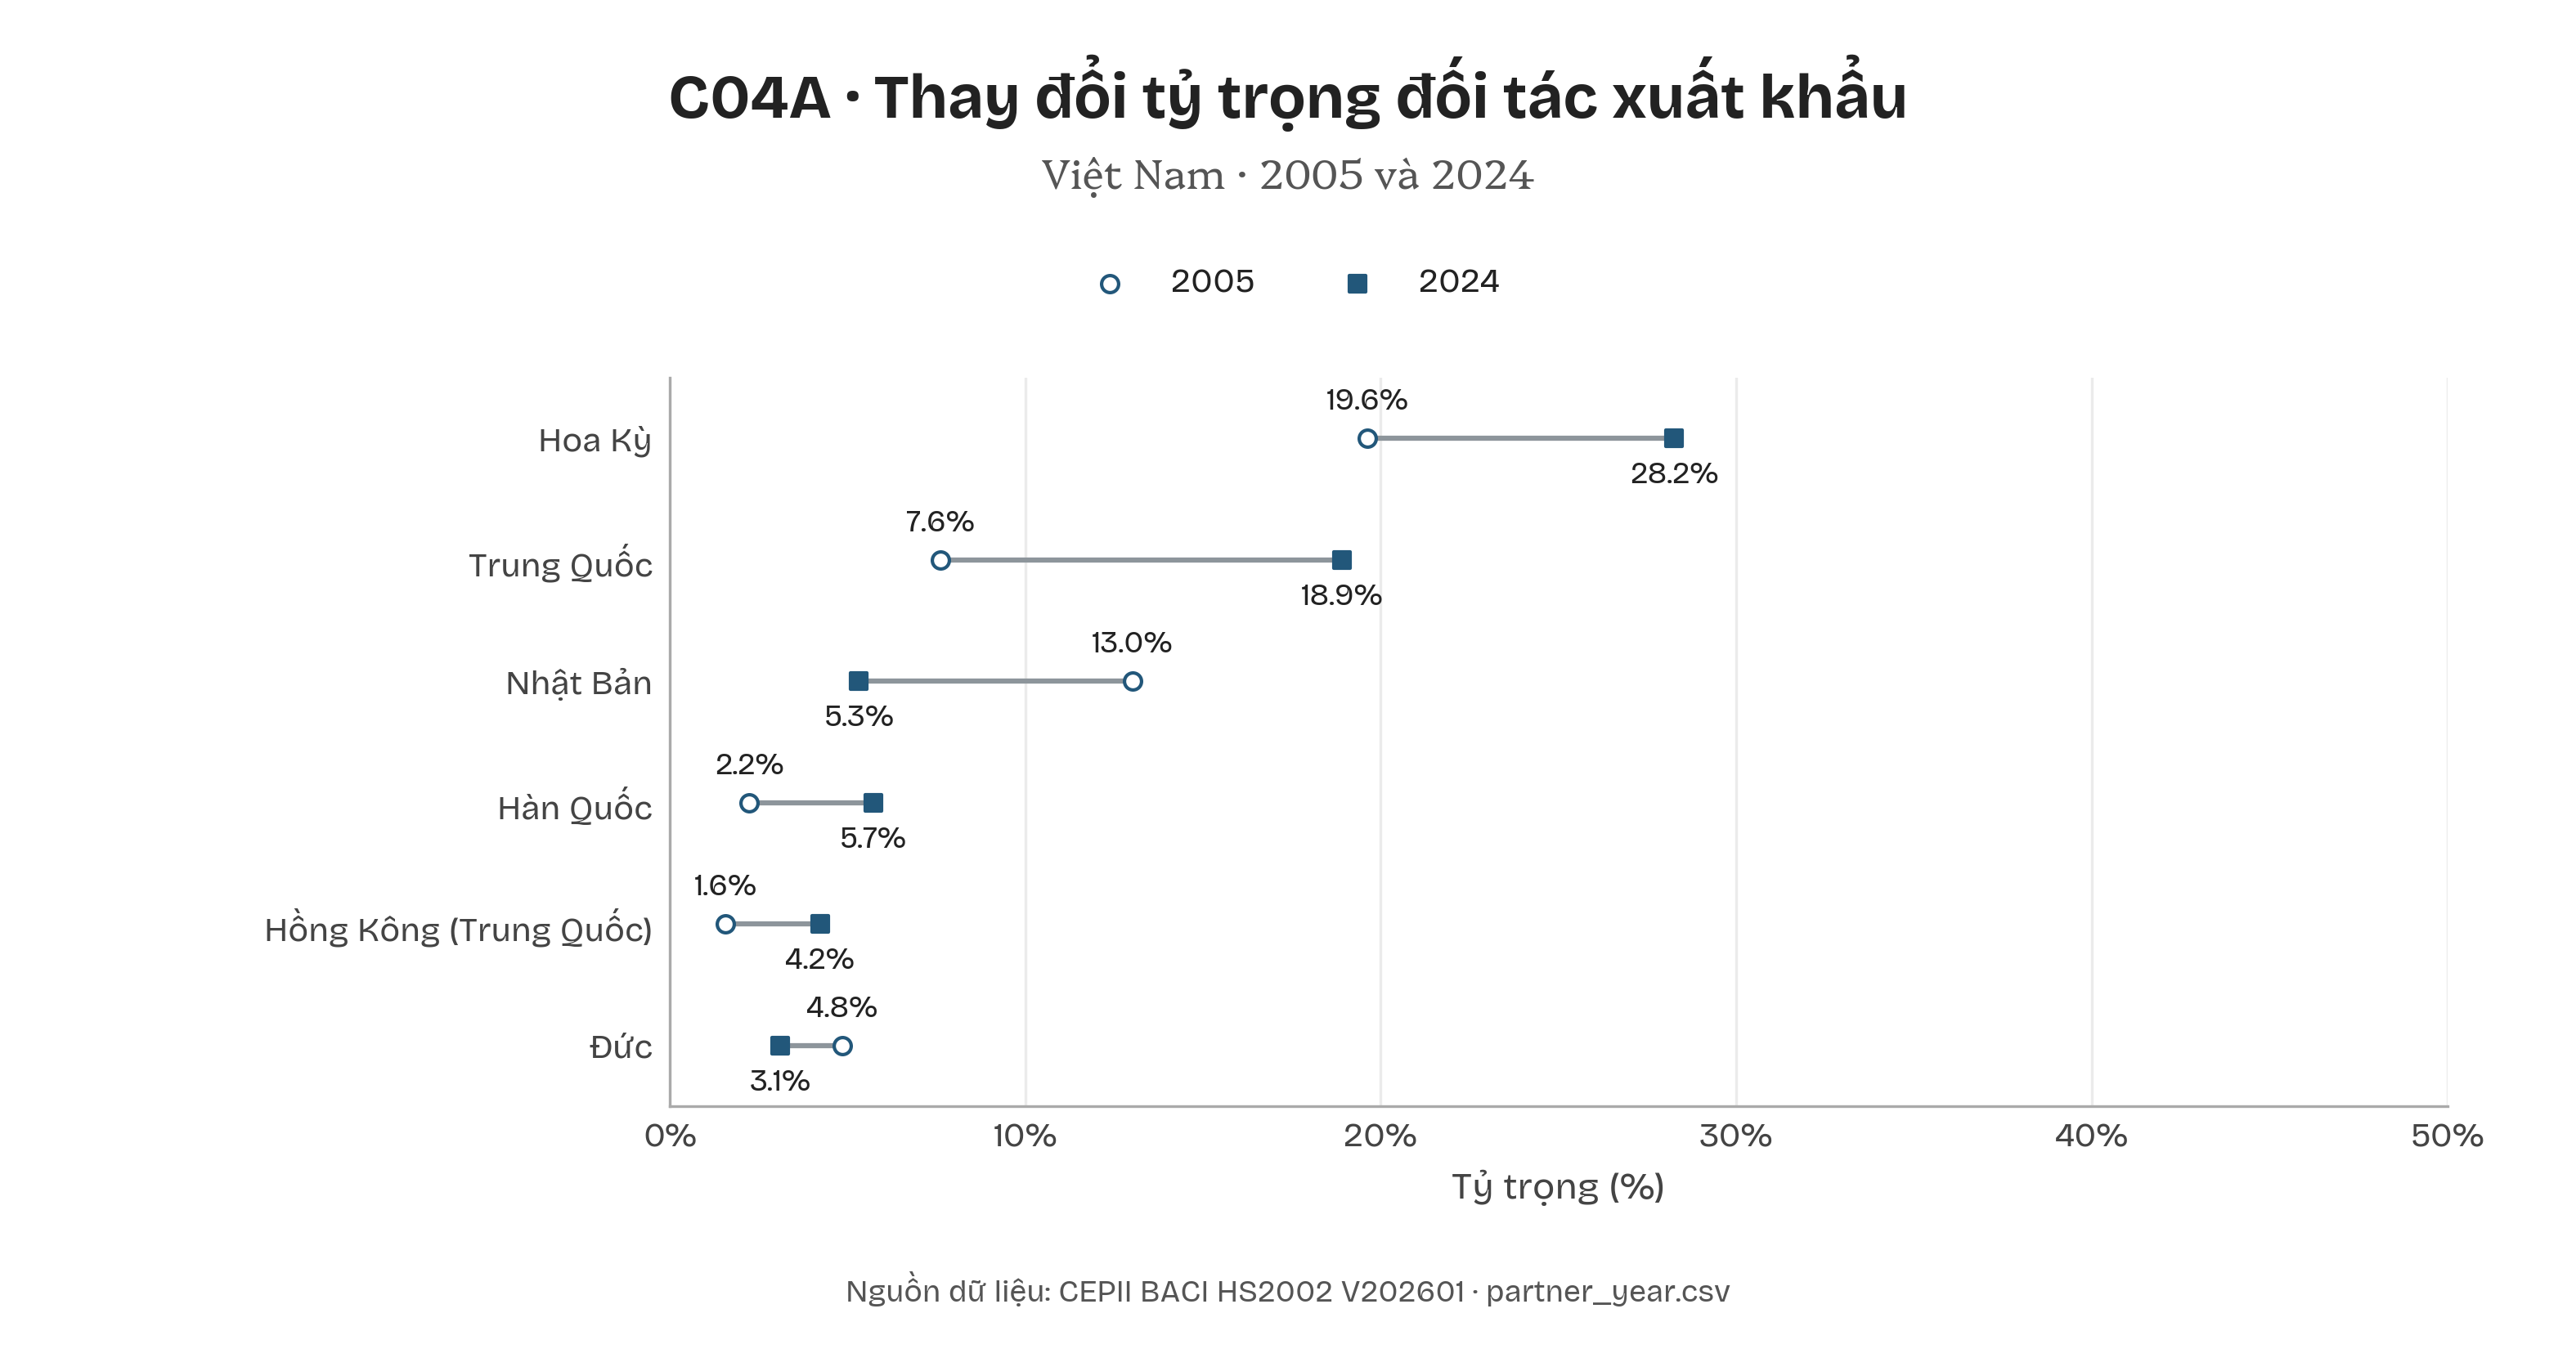

In [31]:
MA_BIEU_DO = "C04A"
data = xu_ly_c04(partners, "Export")
fig = plot_c04(data, "C04A · Thay đổi tỷ trọng đối tác xuất khẩu", "Export")
assert len(data) == 6
assert np.allclose(data["Thay đổi"], 100 * (data[2024] - data[2005]))
for points, year in zip(fig.axes[0].collections[1:], (2005, 2024), strict=True):
    assert np.allclose(points.get_offsets()[:, 0], data[year])
table = data.copy()
for year in (2005, 2024):
    table[year] = table[year].map(format_percent)
table["Thay đổi"] = table["Thay đổi"].map(lambda v: format_number(v, 1, signed=True))
print(table.rename(columns={"Thay đổi": "Thay đổi (điểm %)"}).rename_axis(columns=None))
luu_hinh(fig, MA_BIEU_DO)

### Kết luận C04A

Trong sáu đối tác, tỷ trọng xuất khẩu của **Trung Quốc** thay đổi mạnh nhất, tăng **11.3 điểm phần trăm**, từ **7.6%** lên **18.9%**.

## C04B · Thay đổi tỷ trọng đối tác nhập khẩu

- **Task** · (Q2.2) So sánh tỷ trọng đối tác nhập khẩu năm 2005 và 2024.
- **Dạng** · Biểu đồ hai điểm nối ngang. Mỗi hàng là một đối tác.
- **Lý do** · Đo hướng và độ lớn thay đổi bằng điểm phần trăm.
- **Xử lý** · Chọn sáu đối tác theo tổng kim ngạch nhập khẩu ở hai mốc. Chia cho tổng nhập khẩu của toàn bộ đối tác hợp lệ cùng năm. Giữ cùng sáu đối tác tại hai mốc. Nếu một đối tác vắng mặt trong bảng của một năm, dùng 0 tại năm đó.

**Nguồn** · `data/clean/partner_year.csv`, CEPII BACI HS2002 V202601.

                         2005   2024 Thay đổi (điểm %)
Đối tác                                               
Trung Quốc              17.1%  43.8%             +26.7
Hàn Quốc                11.4%  16.1%              +4.7
Singapore               12.7%   4.7%              −8.0
Hồng Kông (Trung Quốc)   4.1%   5.4%              +1.4
Nhật Bản                12.3%   4.4%              −7.9
Thái Lan                 8.1%   3.2%              −4.9


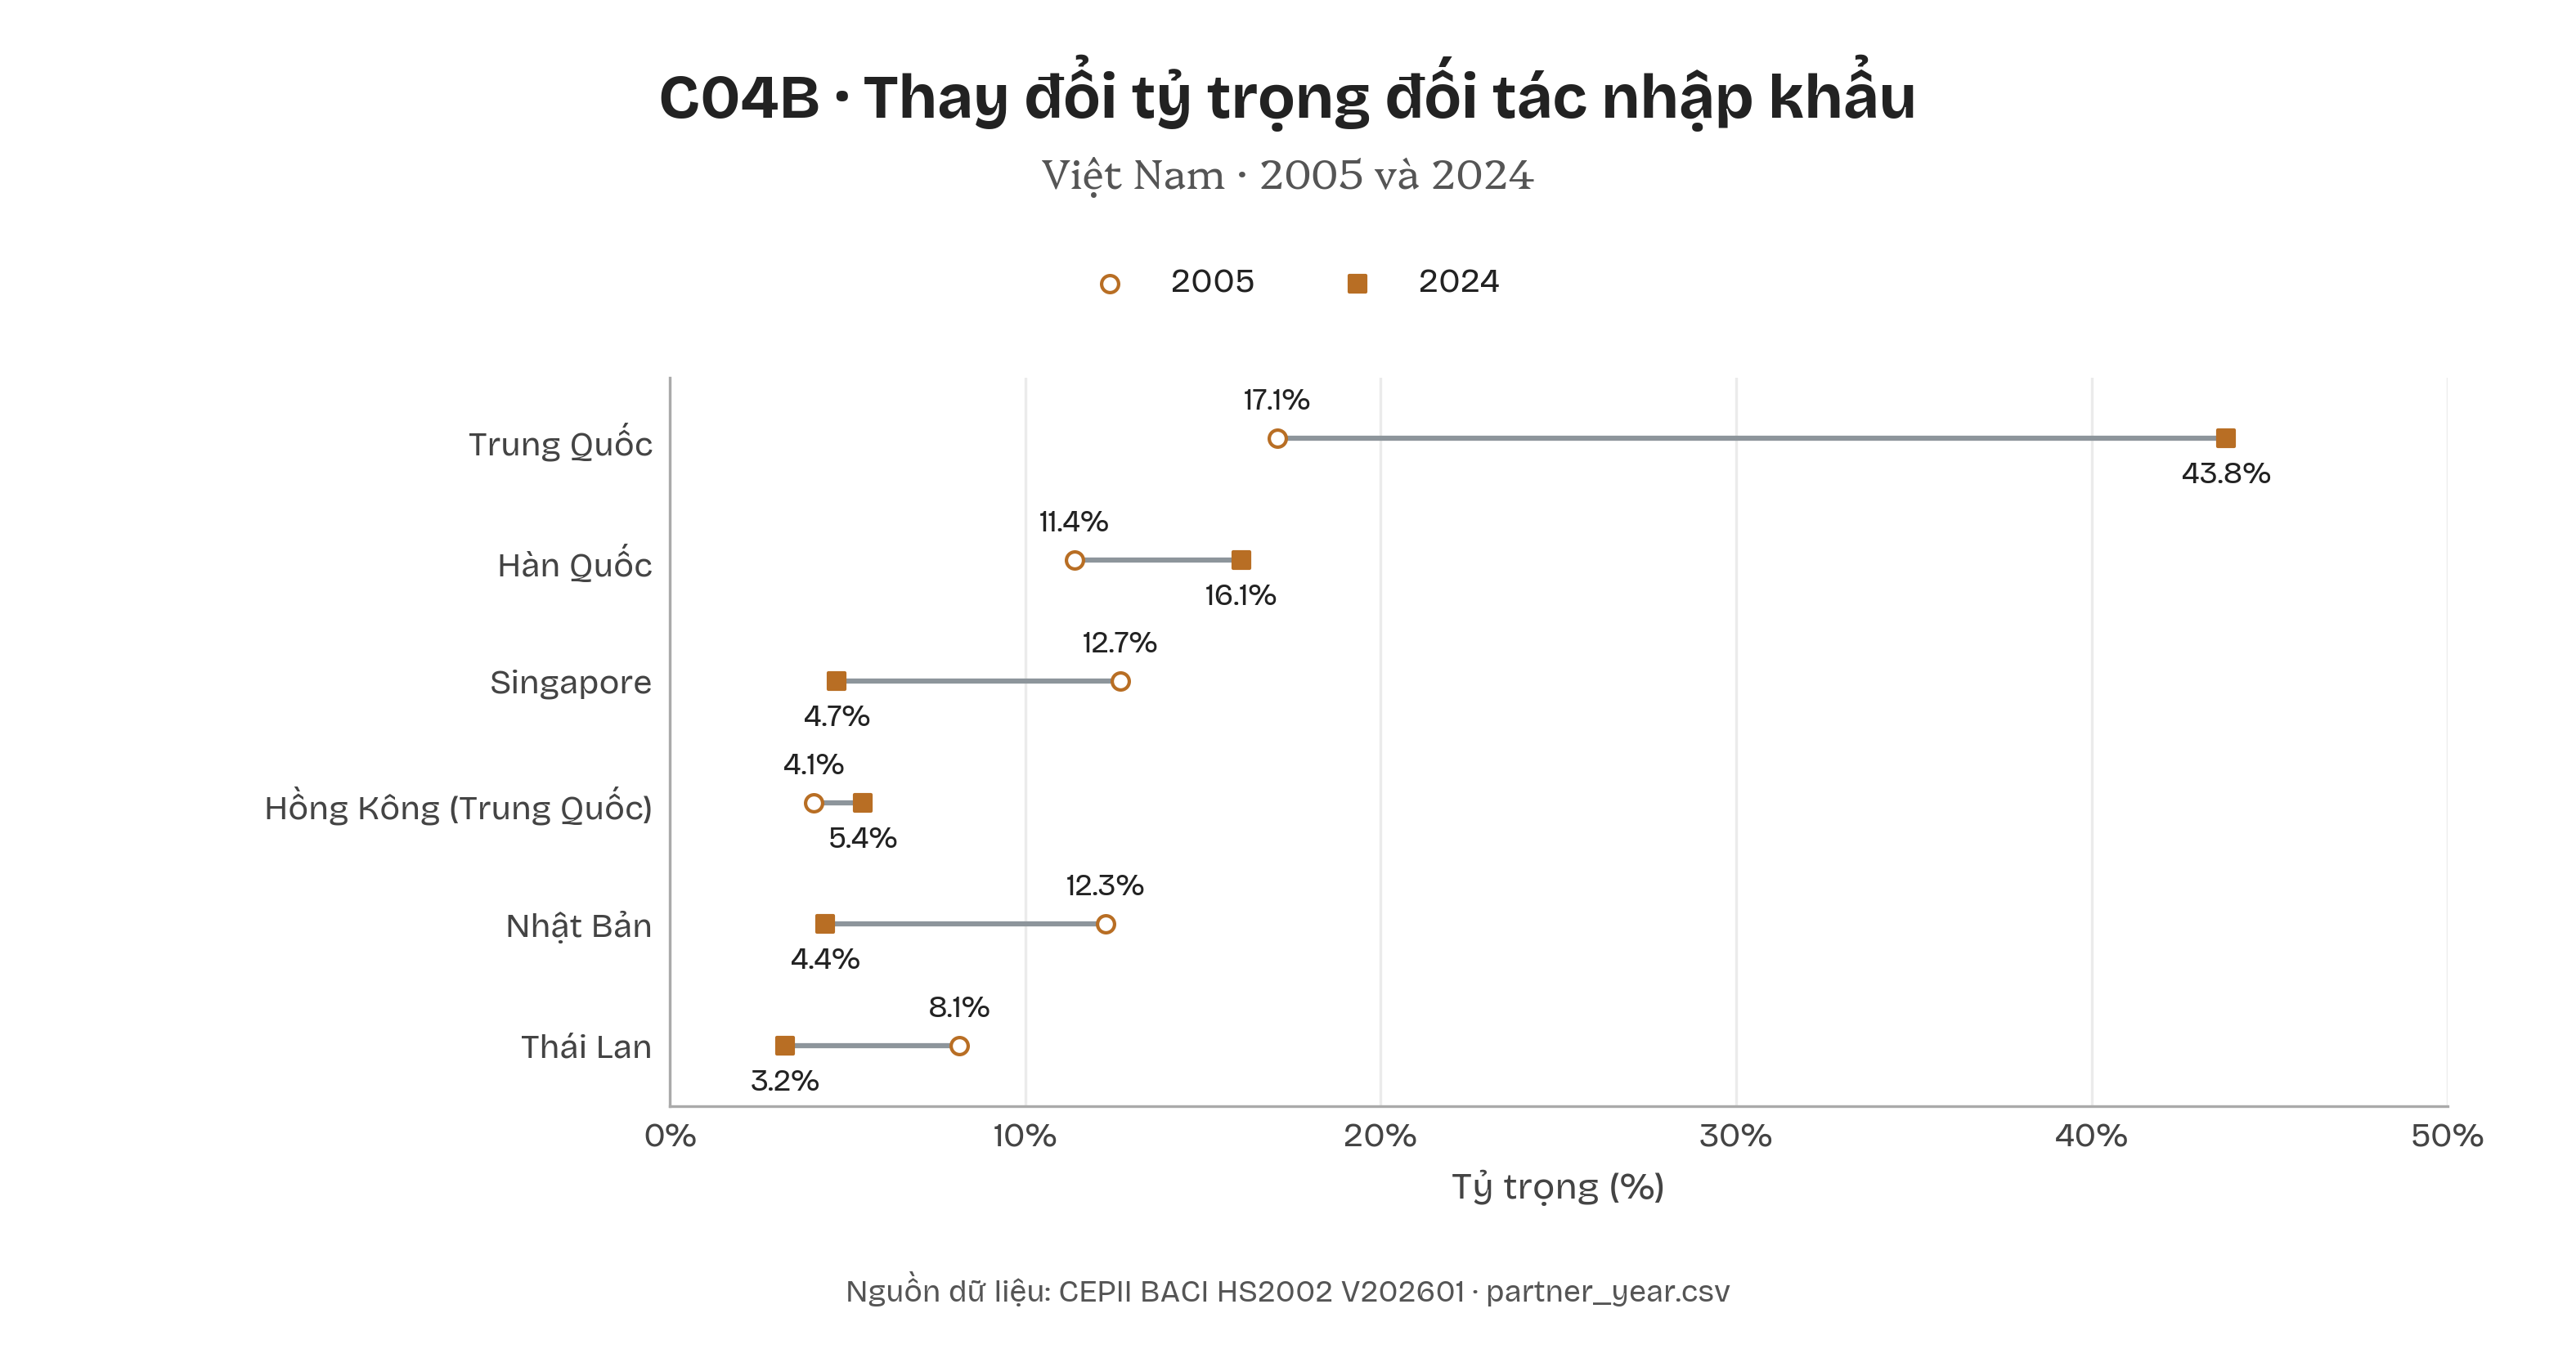

In [32]:
MA_BIEU_DO = "C04B"
data = xu_ly_c04(partners, "Import")
fig = plot_c04(data, "C04B · Thay đổi tỷ trọng đối tác nhập khẩu", "Import")
assert len(data) == 6
assert np.allclose(data["Thay đổi"], 100 * (data[2024] - data[2005]))
for points, year in zip(fig.axes[0].collections[1:], (2005, 2024), strict=True):
    assert np.allclose(points.get_offsets()[:, 0], data[year])
table = data.copy()
for year in (2005, 2024):
    table[year] = table[year].map(format_percent)
table["Thay đổi"] = table["Thay đổi"].map(lambda v: format_number(v, 1, signed=True))
print(table.rename(columns={"Thay đổi": "Thay đổi (điểm %)"}).rename_axis(columns=None))
luu_hinh(fig, MA_BIEU_DO)

### Kết luận C04B

Trong sáu đối tác, tỷ trọng nhập khẩu của **Trung Quốc** thay đổi mạnh nhất, tăng **26.7 điểm phần trăm**, từ **17.1%** lên **43.8%**.

# C05 · Mức độ tập trung đối tác thương mại

**Câu hỏi Q2.** Mức độ tập trung đối tác của Việt Nam thay đổi thế nào theo thời gian?

**Lâm Thanh Nghi** · Mở notebook trong dự án đã giải nén có cài các thư viện từ `requirements.txt` và chọn **Run All** để tạo hai hình.

Dùng quy tắc mã đối tác của bộ định dạng dự án. Loại nhóm BACI `490 / S19` (*Các nền kinh tế châu Á khác, chưa phân loại*) và mã tổng hợp khỏi cả bảng xếp hạng lẫn mẫu số. Tính tỷ trọng theo từng năm và từng chiều thương mại.

## C05A · Xu hướng chỉ số tập trung đối tác

- **Task** · (Q2.3) Theo dõi HHI xuất khẩu và nhập khẩu.
- **Dạng** · Biểu đồ đường 2005–2024, có nhãn ở hai đầu mỗi đường.
- **Lý do** · Hai đường cho thấy diễn biến tập trung trên toàn bộ đối tác qua các năm.
- **Xử lý** · Với mỗi năm và mỗi chiều, bình phương tỷ trọng dạng thập phân của từng đối tác, cộng lại và nhân 10.000.

**Nguồn** · `data/clean/partner_year.csv`, CEPII BACI HS2002 V202601.

In [33]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import rc_context
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "notebooks/house_style/house_style.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook trong thư mục dự án đã giải nén.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from notebooks.house_style.house_style import (
    SOURCE, SUBTITLE, TRADE_FLOW_COLORS, TRADE_FLOW_LABELS,
    TRADE_FLOW_LINESTYLES, TRADE_FLOW_MARKERS, TRADE_FLOW_ORDER,
    apply_style, format_number, format_percent, format_percentage_points,
    is_partner_code,
)

DATA_DIR = ROOT / "data" / "clean"
YEARS = tuple(range(2005, 2025))

def tai_du_lieu(data_dir=DATA_DIR):
    raw = pd.read_csv(data_dir / "partner_year.csv",
                      dtype={"partner_code": str, "partner_iso3": str})
    valid = raw.partner_iso3.fillna("").map(is_partner_code)
    valid &= ~raw.partner_code.str.lstrip("0").isin(["", "999"])
    data = raw.loc[valid & raw.year.between(2005, 2024)
                   & raw.trade_flow.isin(TRADE_FLOW_ORDER)].copy()
    assert np.isfinite(data.trade_usd).all() and data.trade_usd.ge(0).all()
    keys = ["year", "trade_flow", "partner_code"]
    data = data.groupby(keys, as_index=False).agg(
        trade_usd=("trade_usd", "sum"), partner_iso3=("partner_iso3", "first"))
    totals = data.groupby(["year", "trade_flow"]).trade_usd.transform("sum")
    assert totals.gt(0).all()
    data["share"] = data.trade_usd / totals
    summed = data.groupby(["year", "trade_flow"]).share.sum()
    assert len(summed) == 40 and np.allclose(summed, 1, atol=1e-12, rtol=0)
    return data

partners = tai_du_lieu()

In [34]:
def xu_ly_c05(data):
    result = data.groupby(["year", "trade_flow"]).share.agg(
        HHI=lambda shares: 10000 * shares.pow(2).sum(),
        CR5=lambda shares: shares.nlargest(5).sum(),
    )
    assert result.HHI.between(0, 10000).all() and result.CR5.between(0, 1).all()
    return result

indices = xu_ly_c05(partners)

def plot_c05(result, metric, title):
    with apply_style():
        fig = Figure(figsize=(10.5, 5.5))
        ax = fig.subplots()
        fig.subplots_adjust(left=.13, right=.94, top=.78, bottom=.18)
        trang_tri(fig, title, "Việt Nam · 2005–2024")
        percent = metric == "CR5"
        formatter = format_percent if percent else format_number
        for flow in TRADE_FLOW_ORDER:
            values = result[metric].xs(flow, level="trade_flow").reindex(YEARS)
            color = TRADE_FLOW_COLORS[flow]
            ax.plot(YEARS, values, label=TRADE_FLOW_LABELS[flow], color=color,
                    linestyle=TRADE_FLOW_LINESTYLES[flow], marker=TRADE_FLOW_MARKERS[flow],
                    markevery=[0, len(YEARS)-1])
            for year in (2005, 2024):
                ax.annotate(formatter(values.loc[year], int(percent)), (year, values.loc[year]),
                            xytext=(0, 8 if flow == "Import" else -15),
                            textcoords="offset points", ha="center", color=color, fontsize=10)
        ax.set(xlim=(2004, 2025), xticks=[2005, 2010, 2015, 2020, 2024], xlabel="Năm",
               ylabel="Tỷ trọng (%)" if percent else "HHI (điểm)")
        if percent:
            ax.set(ylim=(0, .8), yticks=np.arange(9)/10)
        else:
            ax.set_ylim(bottom=0)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: formatter(v, 0)))
        ax.grid(axis="y", alpha=.25)
        ax.legend(loc="upper left", ncol=2)
    return fig

def trang_tri(fig, title, scope):
    fig.suptitle(title, y=.97)
    fig.text(.5, .89, scope, **SUBTITLE)
    fig.text(.5, .035, "Nguồn dữ liệu: CEPII BACI HS2002 V202601 · partner_year.csv", **SOURCE)

def luu_hinh(fig, name):
    folder = ROOT / "outputs" / "core_charts" / name[:3]
    folder.mkdir(parents=True, exist_ok=True)
    paths = tuple(folder / f"{name}.{ext}" for ext in ("png", "svg"))
    with apply_style(), rc_context({"svg.fonttype": "path"}):
        for path in paths:
            fig.savefig(path)
    print("Đã lưu", " và ".join(str(path.relative_to(ROOT)) for path in paths))
    display(Image(filename=str(paths[0]), width=900))

     Xuất khẩu Nhập khẩu
Năm                     
2005       791       877
2024     1,290     2,298
Đã lưu outputs\core_charts\C05\C05A.png và outputs\core_charts\C05\C05A.svg


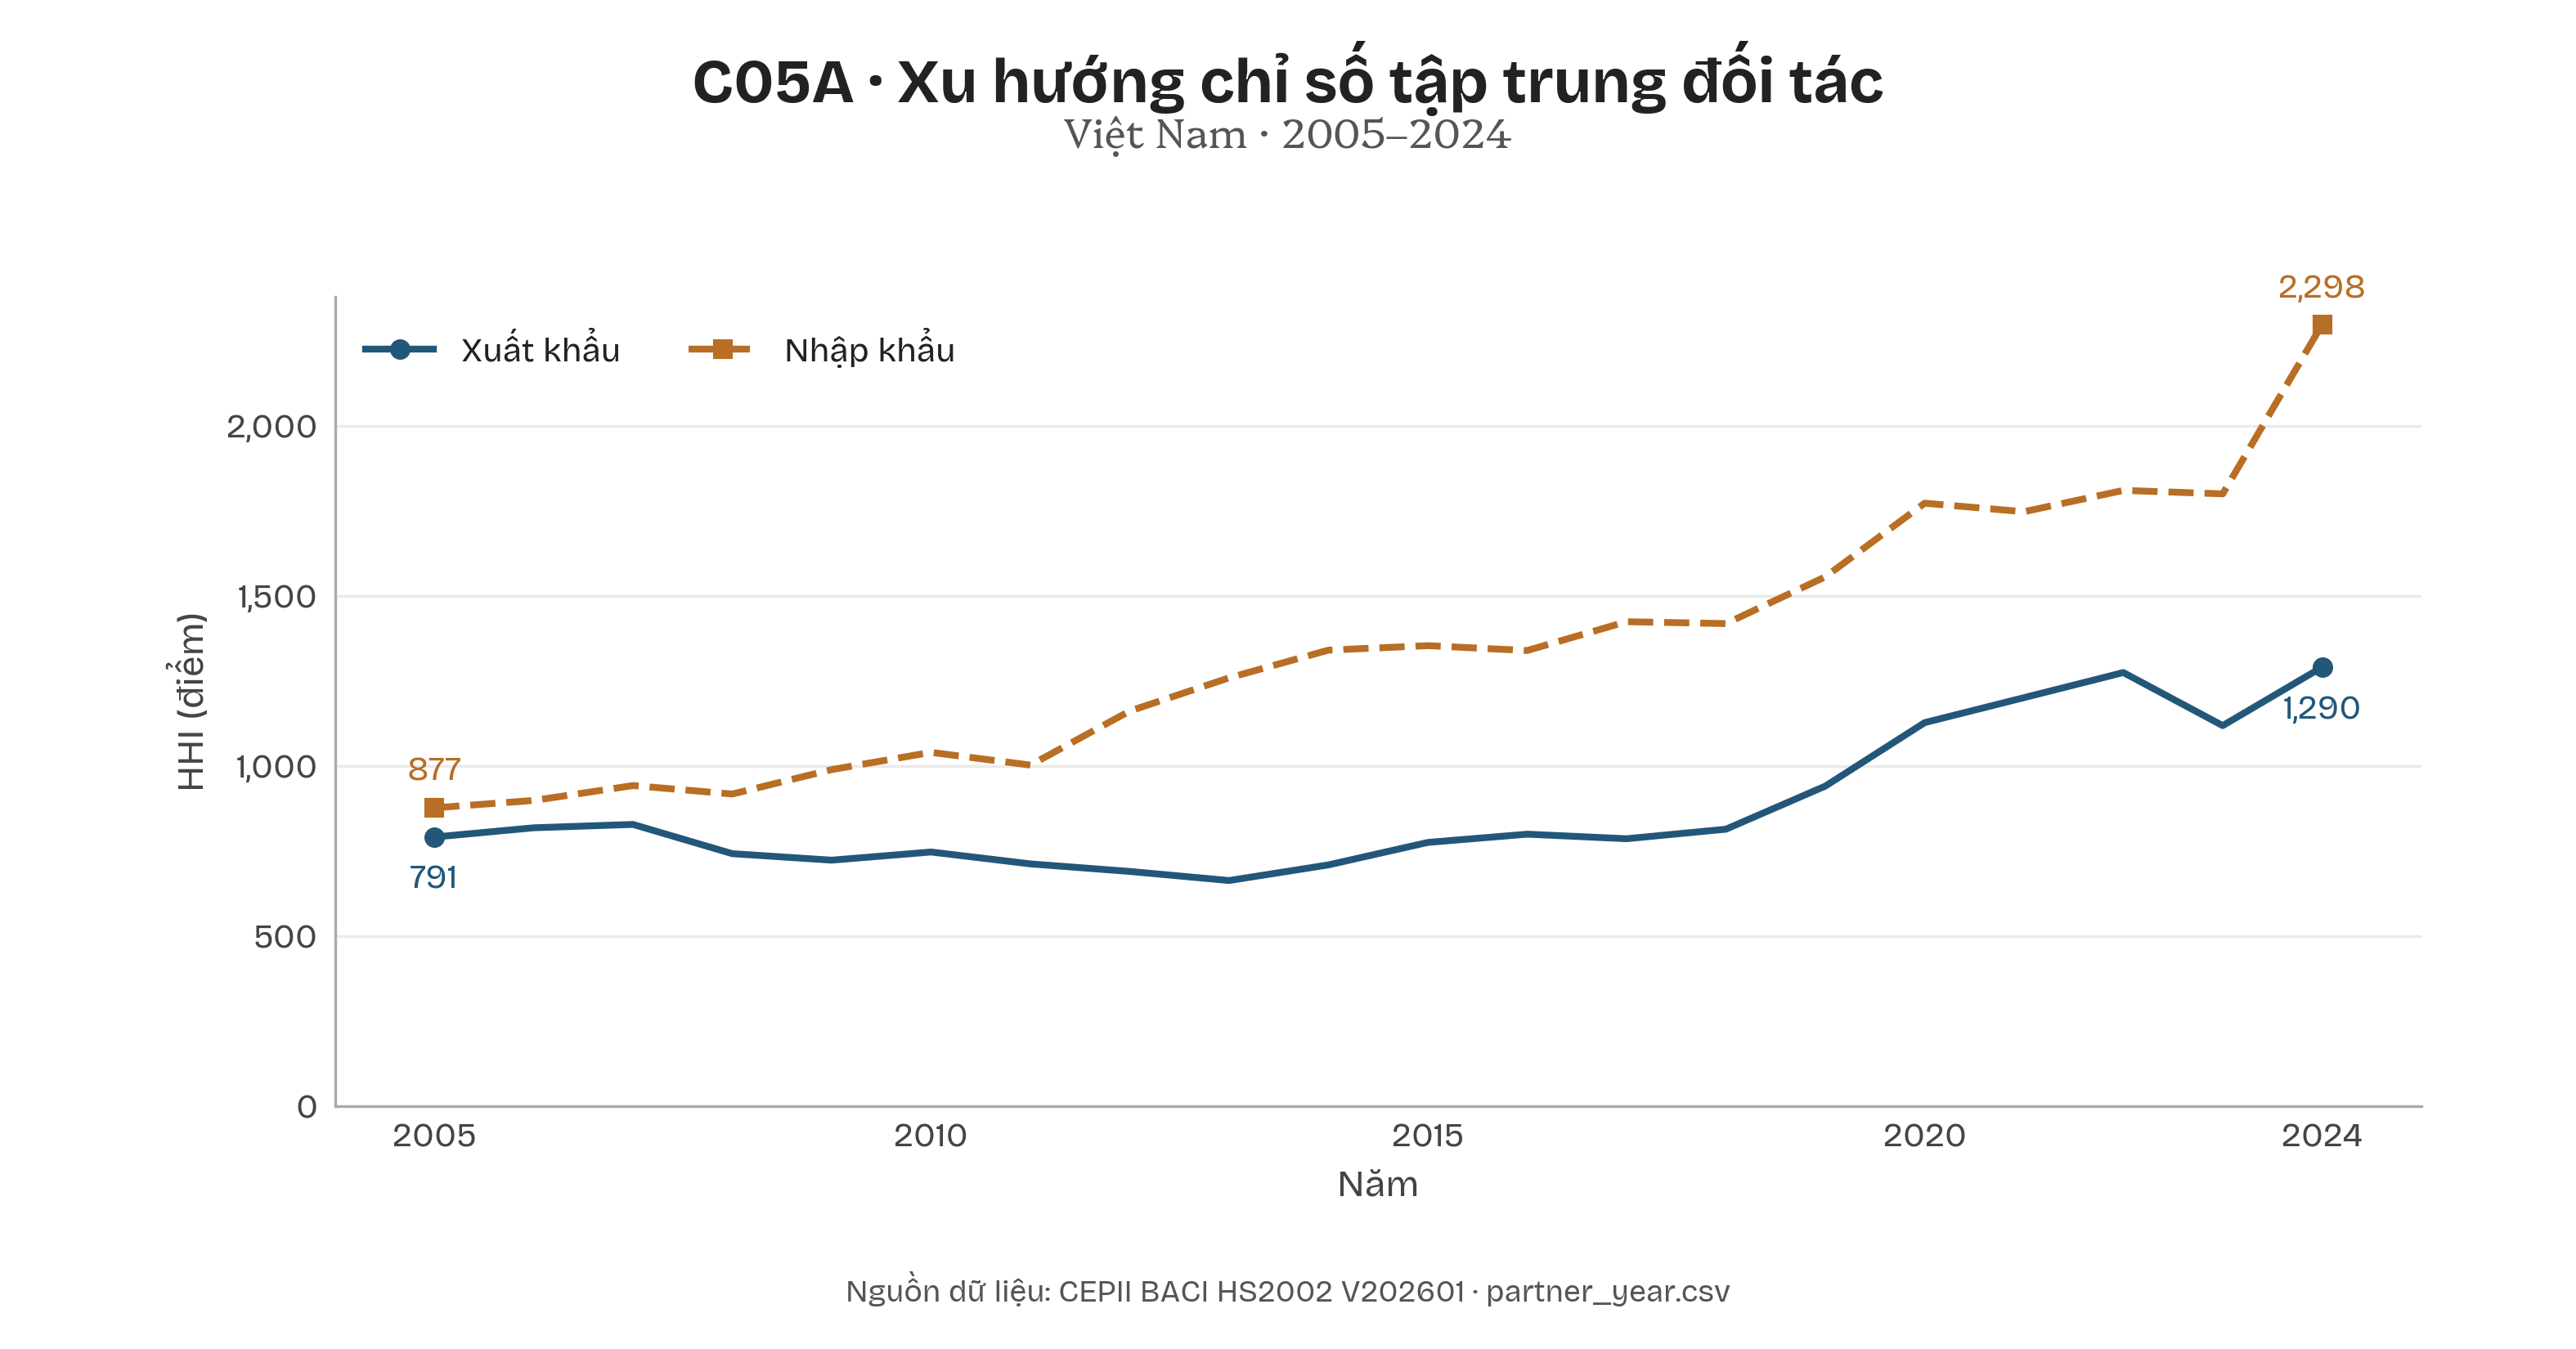

In [35]:
MA_BIEU_DO = "C05A"
fig = plot_c05(indices, "HHI", "C05A · Xu hướng chỉ số tập trung đối tác")
for line, flow in zip(fig.axes[0].lines, TRADE_FLOW_ORDER, strict=True):
    assert tuple(line.get_xdata()) == YEARS
    expected = indices["HHI"].xs(flow, level="trade_flow").reindex(YEARS)
    assert len(expected) == 20 and np.allclose(line.get_ydata(), expected)
format_value = format_percent if "HHI" == "CR5" else format_number
print(indices["HHI"].unstack().rename(columns=TRADE_FLOW_LABELS)
      .loc[[2005, 2024]].rename_axis(index="Năm", columns=None).apply(lambda col: col.map(format_value)))
luu_hinh(fig, MA_BIEU_DO)

### Kết luận C05A

HHI nhập khẩu tăng **1,421 điểm**, từ **877** năm 2005 lên **2,298** năm 2024.

## C05B · Tỷ trọng của năm đối tác lớn nhất

- **Task** · (Q2.3) Theo dõi CR5 xuất khẩu và nhập khẩu.
- **Dạng** · Biểu đồ đường 2005–2024, có nhãn ở hai đầu mỗi đường.
- **Lý do** · CR5 cho biết năm đối tác lớn nhất chiếm bao nhiêu phần trong tổng kim ngạch.
- **Xử lý** · Với mỗi năm và mỗi chiều, cộng tỷ trọng của năm đối tác đứng đầu. Hiển thị tỷ trọng dưới dạng phần trăm, với trục Y bắt đầu từ 0%.

**Nguồn** · `data/clean/partner_year.csv`, CEPII BACI HS2002 V202601.

     Xuất khẩu Nhập khẩu
Năm                     
2005     52.1%     61.6%
2024     62.4%     74.4%
Đã lưu outputs\core_charts\C05\C05B.png và outputs\core_charts\C05\C05B.svg


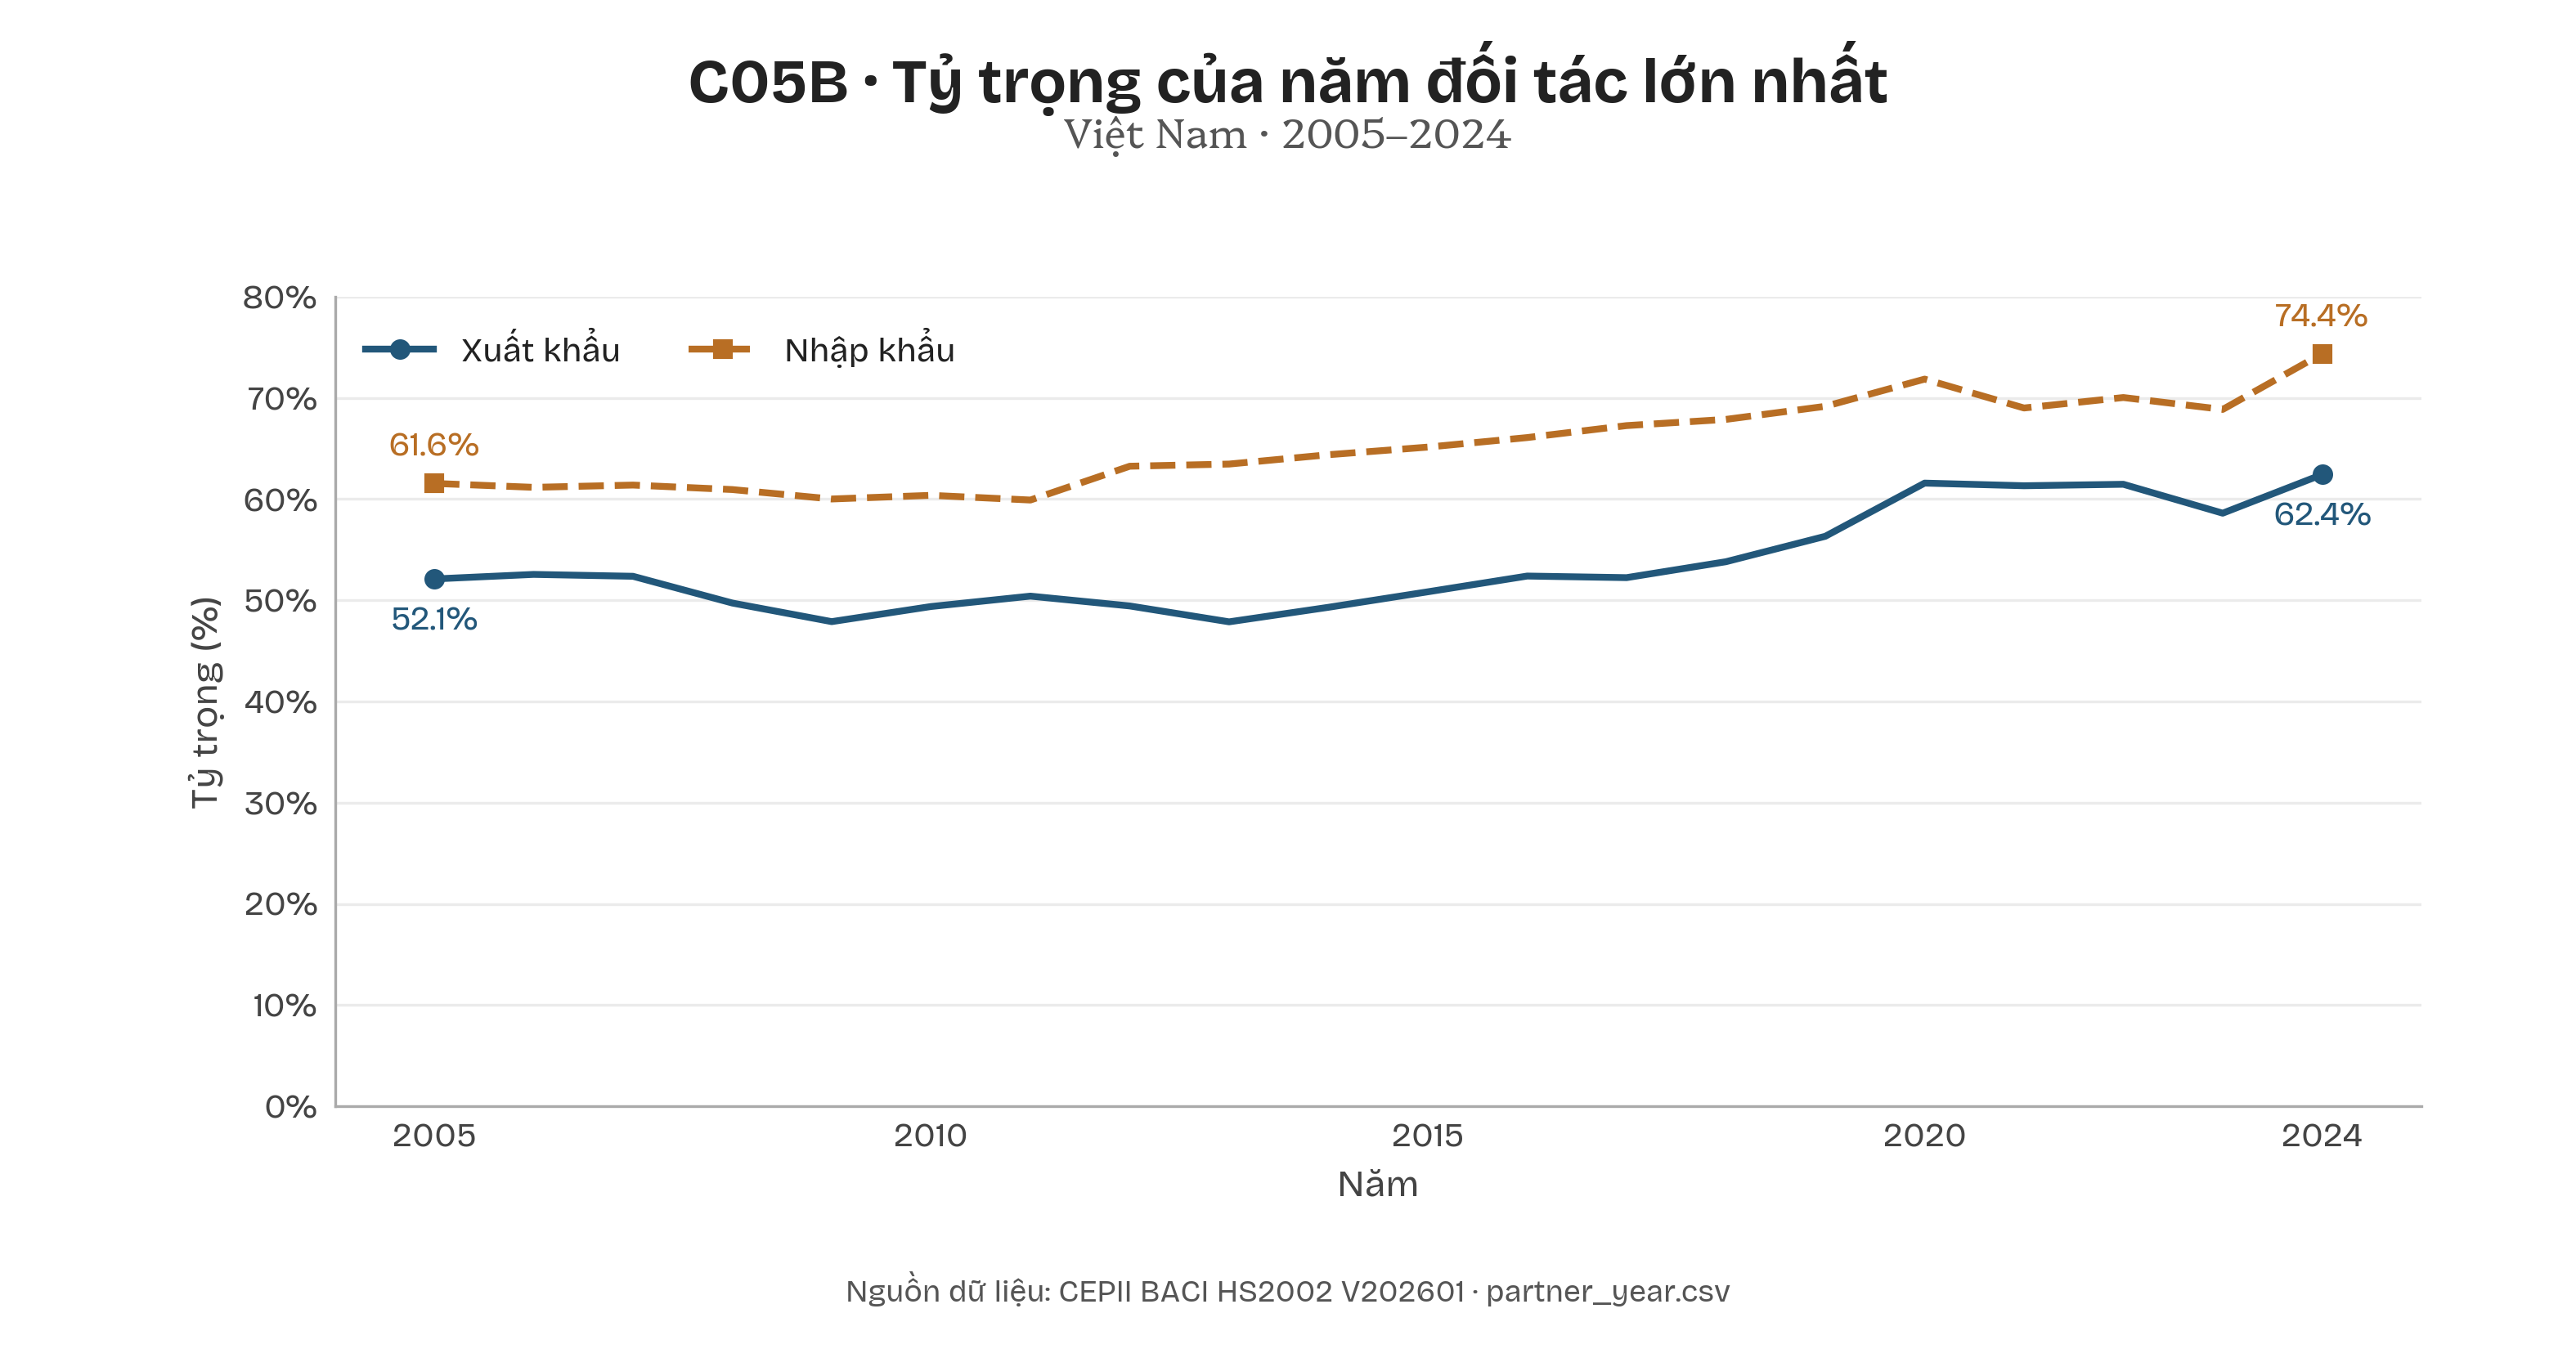

In [36]:
MA_BIEU_DO = "C05B"
fig = plot_c05(indices, "CR5", "C05B · Tỷ trọng của năm đối tác lớn nhất")
for line, flow in zip(fig.axes[0].lines, TRADE_FLOW_ORDER, strict=True):
    assert tuple(line.get_xdata()) == YEARS
    expected = indices["CR5"].xs(flow, level="trade_flow").reindex(YEARS)
    assert len(expected) == 20 and np.allclose(line.get_ydata(), expected)
format_value = format_percent if "CR5" == "CR5" else format_number
print(indices["CR5"].unstack().rename(columns=TRADE_FLOW_LABELS)
      .loc[[2005, 2024]].rename_axis(index="Năm", columns=None).apply(lambda col: col.map(format_value)))
luu_hinh(fig, MA_BIEU_DO)

### Kết luận C05B

Năm 2024, năm đối tác lớn nhất chiếm **62.4%** kim ngạch xuất khẩu và **74.4%** kim ngạch nhập khẩu.

# C06 – Xuất xứ hàng hóa trong cửa hàng TP.HCM
**Q4.** Trong cửa hàng tại TP.HCM, bao nhiêu hàng là "Made in Vietnam", xét theo ngành hàng (phần HS) và mức giá?

In [37]:
# ===== SETUP CHUNG  =====
import sys, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "clean").exists())
sys.path.insert(0, str(ROOT / "notebooks"))
from house_style.house_style import (apply_style, HS_ORDER, PARTNER_COLORS, OTHER_COLOR,
                                     SOURCE, DIRECT_LABEL, declutter, COUNTRY_COLORS)

OUT = ROOT / "outputs" / "core_charts" / "C06"
OUT.mkdir(parents=True, exist_ok=True)

VN = "Việt Nam"
VN_COLOR = COUNTRY_COLORS["VNM"]   
NGUON = "Nguồn: Khảo sát cửa hàng TP.HCM (survey_final.csv), 398 mẫu hàng tại các cửa hàng đã chọn"
ISO = {"Trung Quốc": "CHN", "Thái Lan": "THA", "Nhật Bản": "JPN", "Hàn Quốc": "KOR", "Mỹ": "USA"}
FALLBACK = ["#E69F00", "#56B4E9", "#F0E442", "#999999"]

df = pd.read_csv(ROOT / "data" / "clean" / "survey_final.csv", encoding="utf-8-sig")

def text_color(c):                      # chữ trắng trên nền tối, chữ đen trên nền sáng
    r, g, b = to_rgb(c)
    return "white" if 0.299*r + 0.587*g + 0.114*b < 0.55 else "#222222"

def hs_label(s, n):                     # nhãn trục: chỉ mã phần HS + n
    return f"{s} (n={n})"

def country_color(c, i=0):              # màu nước theo house_style, thiếu thì dùng màu dự phòng
    return PARTNER_COLORS.get(ISO.get(c), FALLBACK[i % len(FALLBACK)])

print(df.shape)

(398, 34)


### C06A – Cơ cấu xuất xứ theo ngành hàng (phần HS)
- **Câu hỏi phụ (Q4.1):** So tỷ trọng nước xuất xứ giữa các phần HS.
- **Task:** So sánh (compare) tỷ trọng nước xuất xứ giữa các phần HS.
- **Dạng biểu đồ:** 100% stacked horizontal bar.
- **Lý do chọn dạng:** 100% stacked bar so cơ cấu xuất xứ, đọc được trực tiếp tỷ lệ Việt Nam.
- **Dữ liệu:** `data/clean/survey_final.csv` — `record_id, hs2022_section, origin_country, made_in_vietnam, verify_status`; lọc: sản phẩm có phần HS và xuất xứ hợp lệ.

In [38]:
# [C06A] HÀM XỬ LÝ DỮ LIỆU
def prep_c06a(df, hs_sections=None, top_n=3, only_verified=False):
    """Tỷ trọng (%) nước xuất xứ theo phần HS. Top-N nước ngoài VN tính trên TOÀN MẪU, còn lại gộp 'Khác'."""
    d = df.dropna(subset=["hs2022_section", "origin_country"])
    if only_verified:
        d = d[d.verify_status == "OK"]
    top = d.loc[d.origin_country != VN, "origin_country"].value_counts().head(top_n).index.tolist()
    d = d.assign(nhom=np.where(d.origin_country.isin([VN] + top), d.origin_country, "Khác"))
    if hs_sections:
        d = d[d.hs2022_section.isin(hs_sections)]
    order = [s for s in HS_ORDER if s in set(d.hs2022_section)]          # xếp I → XX
    cols = [VN] + top + ["Khác"]
    ct = pd.crosstab(d.hs2022_section, d.nhom).reindex(index=order, columns=cols, fill_value=0)
    n = ct.sum(axis=1)
    return ct.div(n, axis=0) * 100, n, top, d

In [39]:
# [C06A] HÀM VẼ + ACTION TITLE + HOUSE STYLE
def plot_c06a(pct, n, title, vn_color=VN_COLOR, min_label=7, figsize=(11, 7.5), note=""):
    cols = list(pct.columns)
    colors = {VN: vn_color, "Khác": OTHER_COLOR}
    colors.update({c: country_color(c, i) for i, c in enumerate(cols[1:-1])})
    with apply_style():
        fig, ax = plt.subplots(figsize=figsize, layout="constrained")
        y = np.arange(len(pct)); left = np.zeros(len(pct))
        for c in cols:
            w = pct[c].values
            ax.barh(y, w, left=left, color=colors[c], label=c, height=0.7, edgecolor="white", linewidth=0.8)
            for yi, (l, wi) in enumerate(zip(left, w)):
                if wi >= min_label:                                  # chỉ ghi % khi đủ rộng
                    ax.text(l + wi/2, yi, f"{wi:.1f}%", ha="center", va="center",
                            color=text_color(colors[c]), **DIRECT_LABEL)
            left += w
        ax.set_yticks(y, [hs_label(s, n[s]) for s in pct.index])
        ax.invert_yaxis()                                            # I ở trên cùng
        ax.set_xlim(0, 100)
        ax.set_xlabel("Tỷ trọng sản phẩm theo nước xuất xứ (%)")
        ax.set_ylabel("Phần HS")
        declutter(ax, "x")
        ax.legend(ncol=len(cols), loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
        fig.suptitle(textwrap.fill(title, 80))                       # ACTION TITLE
        fig.supxlabel(NGUON + note, **SOURCE)
    return fig, ax

Top nước ngoài VN: ['Trung Quốc', 'Thái Lan', 'Nhật Bản'] | n = 398 | cần xác minh: 14


nhom,Việt Nam,Trung Quốc,Thái Lan,Nhật Bản,Khác,n
hs2022_section,,,,,,
I,90.5,4.8,0.0,0.0,4.8,21
II,0.0,0.0,0.0,100.0,0.0,1
IV,60.4,1.9,9.4,1.9,26.4,106
VI,51.3,10.3,12.0,14.5,12.0,117
VII,60.0,40.0,0.0,0.0,0.0,5
VIII,45.5,54.5,0.0,0.0,0.0,11
X,66.7,33.3,0.0,0.0,0.0,9
XI,93.3,0.0,0.0,0.0,6.7,45
XII,66.7,16.7,16.7,0.0,0.0,6


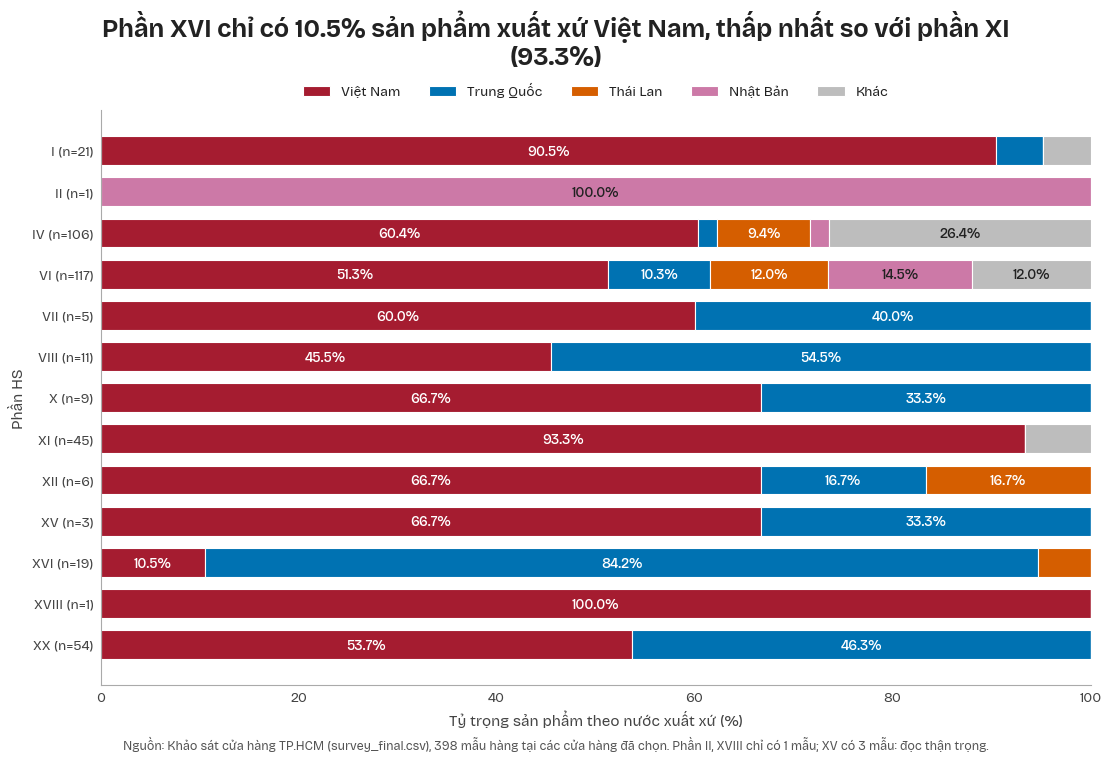

In [40]:
# [C06A] THAM SỐ → GỌI HÀM → KIỂM TRA → LƯU ẢNH
# ---- THAM SỐ  ----
HS_SECTIONS   = None      # None = tất cả; hoặc ["I", "IV", "VI"]
TOP_N         = 3         # số nước ngoài VN hiển thị riêng
ONLY_VERIFIED = False     # True = bỏ mẫu "Cần xác minh"
COLOR_VN      = VN_COLOR  # đổi màu Việt Nam, ví dụ "#D55E00"
MIN_LABEL     = 7         # ngưỡng % tối thiểu để ghi nhãn trong thanh
ACTION_TITLE  = "Phần XVI chỉ có 10.5% sản phẩm xuất xứ Việt Nam, thấp nhất so với phần XI (93.3%)"
NOTE          = ". Phần II, XVIII chỉ có 1 mẫu; XV có 3 mẫu: đọc thận trọng."
FILE_A        = "C06A_co_cau_xuat_xu_theo_hs.png"

pct_c06a, n_c06a, top_c06a, df_c06a = prep_c06a(df, HS_SECTIONS, TOP_N, ONLY_VERIFIED)
print("Top nước ngoài VN:", top_c06a, "| n =", len(df_c06a), "| cần xác minh:", (df_c06a.verify_status != "OK").sum())
display(pct_c06a.round(1).assign(n=n_c06a))

fig_c06a, ax_c06a = plot_c06a(pct_c06a, n_c06a, ACTION_TITLE, COLOR_VN, MIN_LABEL, note=NOTE)
with apply_style():
    fig_c06a.savefig(OUT / FILE_A, dpi=300)
plt.show()

**Insight & kết luận (C06A)**
- Hàng Việt chiếm áp đảo ở phần XI Dệt may (93.3%) và phần I Động vật (90.5%); phần IV (60.4%) và VI (51.3%), hai phần lớn nhất mẫu, có Việt Nam chiếm từ một nửa đến 60%.
- Phần XVI Máy móc, thiết bị điện là ngoại lệ rõ nhất: chỉ 10.5% Việt Nam, Trung Quốc chiếm 84.2%.
- Trung Quốc là nước ngoài xuất hiện nhiều nhất (phần VII, VIII, X, XV, XX từ 33.3% đến 54.5%); Thái Lan, Nhật Bản chủ yếu xuất hiện ở phần IV và VI.

**Hạn chế:** mẫu 398 hàng tại các cửa hàng đã chọn, không suy rộng thị phần TP.HCM. Phần II, XVIII (n=1), XV (n=3), VII, XII, X (n ≤ 9) quá ít mẫu. `origin_country` ≠ `brand_origin`. Mẫu `Cần xác minh` vẫn được giữ trong hình.

### C06B – Tỷ trọng hàng Việt theo mức giá
- **Câu hỏi phụ (Q4.2):** So tỷ trọng hàng Made in Vietnam theo mức giá.
- **Task:** So sánh (compare) tỷ trọng hàng Made in Vietnam theo mức giá.
- **Dạng biểu đồ:** 100% stacked horizontal bar.
- **Lý do chọn dạng:** Chồng 100% thuận tiện so Việt Nam / ngoài Việt Nam ở ba nhóm giá.
- **Dữ liệu:** `data/clean/survey_final.csv` — `record_id, price_tier, made_in_vietnam, origin_country, verify_status, category_clean, price_comparison_unit`; lọc: xuất xứ hợp lệ, mức giá Thấp / Trung bình / Cao (mẫu thiếu tier ghi riêng). Dùng mức giá đã phân theo danh mục và đơn vị so sánh giá, không tự đặt ngưỡng chung.

In [41]:
# [C06B] HÀM XỬ LÝ DỮ LIỆU
def prep_c06b(df, tiers=("Thấp", "Trung bình", "Cao"), hs_sections=None,
              show_unclassified=True, only_verified=False):
    """% VN / ngoài VN theo mức giá; mẫu không có tier gom thành 'Chưa phân loại'."""
    d = df.dropna(subset=["origin_country"])
    if only_verified:
        d = d[d.verify_status == "OK"]
    if hs_sections:
        d = d[d.hs2022_section.isin(hs_sections)]
    d = d.assign(tier=d.price_tier.where(d.price_tier.isin(tiers), "Chưa phân loại"))
    rows = list(tiers) + (["Chưa phân loại"] if show_unclassified else [])
    g = d.groupby("tier").made_in_vietnam.agg(n="size", vn="sum").reindex(rows).fillna(0)
    g["pct_vn"] = g.vn / g.n * 100
    g["pct_ngoai"] = 100 - g.pct_vn
    return g, d

In [42]:
# [C06B] HÀM VẼ + ACTION TITLE + HOUSE STYLE
def plot_c06b(g, title, vn_color=VN_COLOR, other_color=OTHER_COLOR, figsize=(10, 5), note=""):
    k = len(g)
    ypos = np.arange(k, dtype=float)
    if g.index[-1] == "Chưa phân loại":
        ypos[-1] += 0.4                                              # tách thanh "Chưa phân loại"
    with apply_style():
        fig, ax = plt.subplots(figsize=figsize, layout="constrained")
        for lab, col, key in [("Việt Nam", vn_color, "pct_vn"), ("Ngoài Việt Nam", other_color, "pct_ngoai")]:
            left = np.zeros(k) if key == "pct_vn" else g.pct_vn.values
            ax.barh(ypos, g[key], left=left, color=col, label=lab, height=0.6, edgecolor="white")
            for yi, v, l in zip(ypos, g[key], left):
                ax.text(l + v/2, yi, f"{v:.1f}%", ha="center", va="center", color=text_color(col), **DIRECT_LABEL)
        ax.set_yticks(ypos, [f"{r} (n={int(g.n[r])})" for r in g.index])
        ax.invert_yaxis()
        ax.set_xlim(0, 100)
        ax.set_xlabel("Tỷ trọng sản phẩm (%)")
        ax.set_ylabel("Mức giá")
        declutter(ax, "x")
        ax.legend(ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
        fig.suptitle(textwrap.fill(title, 80))                       # ACTION TITLE
        fig.supxlabel(NGUON + note, **SOURCE)
    return fig, ax

n = 398 | cần xác minh: 14


,n,vn,pct_vn,pct_ngoai
tier,,,,
Thấp,119,88,73.9,26.1
Trung bình,93,61,65.6,34.4
Cao,94,44,46.8,53.2
Chưa phân loại,92,44,47.8,52.2


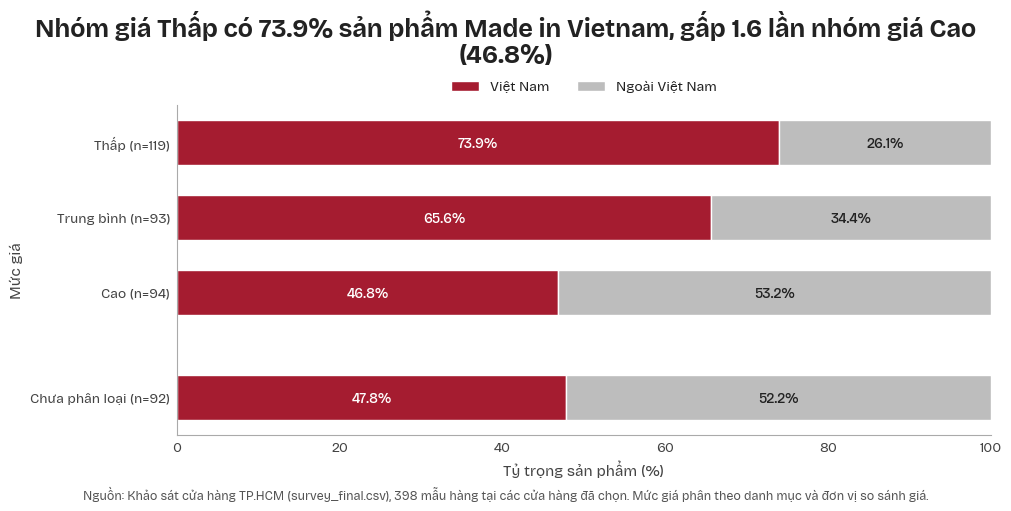

In [43]:
# [C06B] THAM SỐ → GỌI HÀM → KIỂM TRA → LƯU ẢNH
# ---- THAM SỐ ----
TIERS             = ("Thấp", "Trung bình", "Cao")   # thứ tự thanh
HS_SECTIONS_B     = None      # None = tất cả; hoặc ["IV", "VI"] để lọc phần HS
SHOW_UNCLASSIFIED = True      # False = ẩn thanh "Chưa phân loại"
ONLY_VERIFIED_B   = False
COLOR_VN_B        = VN_COLOR
COLOR_OTHER_B     = OTHER_COLOR
ACTION_TITLE_B    = "Nhóm giá Thấp có 73.9% sản phẩm Made in Vietnam, gấp 1.6 lần nhóm giá Cao (46.8%)"
NOTE_B            = ". Mức giá phân theo danh mục và đơn vị so sánh giá."
FILE_B            = "C06B_ty_trong_hang_viet_theo_muc_gia.png"

g_c06b, df_c06b = prep_c06b(df, TIERS, HS_SECTIONS_B, SHOW_UNCLASSIFIED, ONLY_VERIFIED_B)
print("n =", len(df_c06b), "| cần xác minh:", (df_c06b.verify_status != "OK").sum())
display(g_c06b.round(1))

fig_c06b, ax_c06b = plot_c06b(g_c06b, ACTION_TITLE_B, COLOR_VN_B, COLOR_OTHER_B, note=NOTE_B)
with apply_style():
    fig_c06b.savefig(OUT / FILE_B, dpi=300)
plt.show()

**Insight & kết luận (C06B)**
- Tỷ trọng hàng Việt giảm dần khi mức giá tăng: Thấp 73.9% → Trung bình 65.6% → Cao 46.8%.
- Nhóm giá Cao có nhiều hàng ngoài Việt Nam hơn hàng Việt (53.2% so với 46.8%).
- 92 mẫu chưa phân loại mức giá có 47.8% hàng Việt, được tách thanh riêng, không gộp vào ba nhóm.

**Hạn chế:** mẫu 398 hàng tại các cửa hàng đã chọn, không suy rộng thị phần TP.HCM. Mức giá phân theo `category_clean` và `price_comparison_unit`, nên chỉ so được tương đối trong từng danh mục. Mẫu `Cần xác minh` vẫn được giữ trong hình.

### C06C – Mức tập trung xuất xứ (CR3) theo ngành hàng
- **Câu hỏi phụ (Q4.3):** Tính mức tập trung ba nước xuất xứ hàng đầu (CR3) theo phần HS.
- **Task:** Tính / so sánh (compute / compare) CR3 theo phần HS.
- **Dạng biểu đồ:** Lollipop chart.
- **Lý do chọn dạng:** Lollipop giúp so thứ tự tập trung theo phần HS.
- **Dữ liệu:** `data/clean/survey_final.csv` — `record_id, hs2022_section, origin_country, verify_status`; lọc: sản phẩm có phần HS và xuất xứ hợp lệ.
- **Cách tính:** trong mỗi phần HS, CR3 = (số sản phẩm của 3 nước nhiều nhất / tổng sản phẩm biết xuất xứ) × 100. Phần có ≤ 3 nước thì CR3 = 100% hiển nhiên (chấm rỗng).

In [44]:
# [C06C] HÀM XỬ LÝ DỮ LIỆU
def prep_c06c(df, hs_sections=None, top_k=3, only_verified=False, sort_by="hs"):
    """CR-k theo phần HS. sort_by: 'hs' (I → XX) hoặc 'cr' (giảm dần)."""
    d = df.dropna(subset=["hs2022_section", "origin_country"])
    if only_verified:
        d = d[d.verify_status == "OK"]
    if hs_sections:
        d = d[d.hs2022_section.isin(hs_sections)]
    rec = []
    for s in [s for s in HS_ORDER if s in set(d.hs2022_section)]:
        vc = d.loc[d.hs2022_section == s, "origin_country"].value_counts()
        rec.append(dict(hs=s, n=vc.sum(), n_nuoc=len(vc), cr=vc.head(top_k).sum() / vc.sum() * 100,
                        top=", ".join(vc.head(top_k).index)))
    out = pd.DataFrame(rec).set_index("hs")
    if sort_by == "cr":
        out = out.sort_values("cr", ascending=False)
    return out, d

In [45]:
# [C06C] HÀM VẼ + ACTION TITLE + HOUSE STYLE
def plot_c06c(res, title, top_k=3, color=VN_COLOR, figsize=(12, 7), note=""):
    with apply_style():
        fig, (ax, ax_txt) = plt.subplots(1, 2, figsize=figsize, sharey=True,
                                         width_ratios=[3, 2], layout="constrained")
        y = np.arange(len(res))
        ax.hlines(y, 0, res.cr, color=OTHER_COLOR, linewidth=2)
        full = (res.n_nuoc > top_k).values
        ax.scatter(res.cr[full], y[full], s=110, color=color, zorder=3, clip_on=False,
                   label=f"CR{top_k} (> {top_k} nước có dữ liệu)")
        ax.scatter(res.cr[~full], y[~full], s=110, facecolor="white", edgecolor=color, linewidth=2,
                   zorder=3, clip_on=False, label=f"≤ {top_k} nước: CR{top_k} = 100% hiển nhiên")
        ax_txt.axis("off")                                            # cột nhãn bên phải
        ax_txt.text(0, -0.9, f"CR{top_k} · {top_k} nước hàng đầu · số nước", va="center", ha="left",
                    fontweight="bold", fontsize=DIRECT_LABEL.get("fontsize", 10))
        for yi, (s, r) in zip(y, res.iterrows()):
            ax_txt.text(0, yi, f"{r.cr:.1f}% · {r.top} · {int(r.n_nuoc)} nước", va="center", ha="left", **DIRECT_LABEL)
        ax.set_yticks(y, [hs_label(s, int(r.n)) for s, r in res.iterrows()])
        ax.set_ylim(len(y) - 0.4, -1.4)                               # I ở trên cùng, chừa chỗ tiêu đề cột
        ax.set_xlim(0, 100)
        ax.set_xlabel(f"CR{top_k} – tỷ trọng {top_k} nước xuất xứ hàng đầu (%)")
        ax.set_ylabel("Phần HS")
        declutter(ax, "x")
        ax.legend(ncol=1, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
        fig.suptitle(textwrap.fill(title, 75))                        # ACTION TITLE
        fig.supxlabel(NGUON + note, **SOURCE)
    return fig, ax

n = 398 | cần xác minh: 14


,n,n_nuoc,cr,top
hs,,,,
I,21,3,100.0,"Việt Nam, Trung Quốc, Canada"
II,1,1,100.0,Nhật Bản
IV,106,14,77.4,"Việt Nam, Thái Lan, Hàn Quốc"
VI,117,12,77.8,"Việt Nam, Nhật Bản, Thái Lan"
VII,5,2,100.0,"Việt Nam, Trung Quốc"
VIII,11,2,100.0,"Trung Quốc, Việt Nam"
X,9,2,100.0,"Việt Nam, Trung Quốc"
XI,45,2,100.0,"Việt Nam, Campuchia"
XII,6,3,100.0,"Việt Nam, Trung Quốc, Thái Lan"


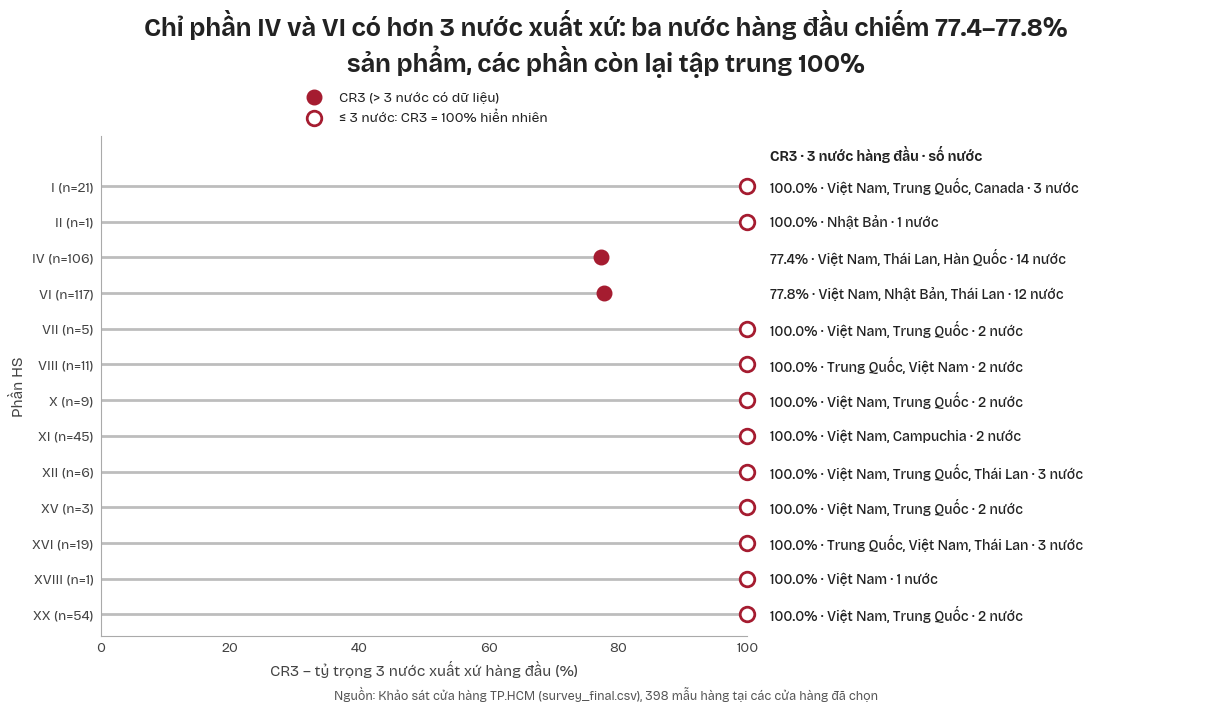

In [46]:
# [C06C] THAM SỐ → GỌI HÀM → KIỂM TRA → LƯU ẢNH
# ---- THAM SỐ ----
HS_SECTIONS_C   = None     # None = tất cả; hoặc ["IV", "VI"]
TOP_K           = 3        # CR3 → đổi 2 hoặc 5 để ra CR2 / CR5
SORT_BY         = "hs"     # "hs" = I → XX ; "cr" = giảm dần theo CR
ONLY_VERIFIED_C = False
COLOR_C         = VN_COLOR
ACTION_TITLE_C  = ("Chỉ phần IV và VI có hơn 3 nước xuất xứ: ba nước hàng đầu chiếm 77.4–77.8% sản phẩm, "
                   "các phần còn lại tập trung 100%")
NOTE_C          = ""
FILE_C          = "C06C_cr3_theo_hs.png"

cr_c06c, df_c06c = prep_c06c(df, HS_SECTIONS_C, TOP_K, ONLY_VERIFIED_C, SORT_BY)
print("n =", len(df_c06c), "| cần xác minh:", (df_c06c.verify_status != "OK").sum())
display(cr_c06c.round(1))

fig_c06c, ax_c06c = plot_c06c(cr_c06c, ACTION_TITLE_C, TOP_K, COLOR_C, note=NOTE_C)
with apply_style():
    fig_c06c.savefig(OUT / FILE_C, dpi=300)
plt.show()

**Insight & kết luận (C06C)**
- Chỉ hai phần có đủ nhiều nước xuất xứ để CR3 có ý nghĩa: IV (14 nước, CR3 = 77.4%: Việt Nam, Thái Lan, Hàn Quốc) và VI (12 nước, CR3 = 77.8%: Việt Nam, Nhật Bản, Thái Lan).
- Mười một phần còn lại chỉ có 1–3 nước nên CR3 = 100% hiển nhiên, không phản ánh mức tập trung thật.

**Hạn chế:** CR3 nhạy với số mẫu; phần có n nhỏ (II, XVIII, XV...) không diễn giải được. Mẫu 398 hàng tại các cửa hàng đã chọn, không suy rộng thị phần TP.HCM. Mẫu `Cần xác minh` vẫn được giữ trong hình.

## C07A – Nghịch lý xuất khẩu và xuất xứ hàng trên kệ

- **Câu hỏi phụ** - Q4.4.
- **Task** - Đối chiếu tỷ trọng xuất khẩu với tỷ lệ hàng ngoài Việt Nam trên kệ cùng chương HS.
- **Dạng** - Bubble scatter.
- **Lý do** - Hai trục thể hiện hai tỷ lệ, còn diện tích vòng tròn thể hiện quy mô mẫu của từng chương.
- **Nguồn** - `data/clean/baci_hs_summary.csv` và `data/clean/survey_final.csv`.

**Đối chiếu phiên bản HS** — Dùng hai cột HS02 và HS22 trong [bảng tương quan của UNSD](https://unstats.un.org/unsd/classifications/Econ/tables/HS-SITC-BEC%20Correlations_2022.xlsx). Rút mã sáu chữ số về chương hai chữ số ở cả hai phía. Tiêu chí giữ một chương là các liên kết quan sát được trong bảng đều nằm trong cùng chương khi rà cả hai chiều. Các chương có liên kết sang chương khác được loại vì dữ liệu BACI đầu vào chỉ có tổng cấp chương.

- **Giữ 9 chương** - 09, 33, 34, 40, 42, 49, 64, 65, 82.
- **Loại 17 chương có liên kết chéo** - 03, 16, 17, 19, 20, 21, 22, 38, 39, 48, 61, 62, 84, 85, 90, 95, 96.
- **Mẫu số trục X** - Vẫn dùng tổng xuất khẩu của tất cả chương BACI trong năm đã chọn.


In [47]:
import pandas as pd

def lay_du_lieu_c07a(trade_path, survey_path, year, min_n, compatible_hs2):
    """Tính tỷ trọng xuất khẩu, tỷ lệ ngoài Việt Nam và số mẫu theo chương."""
    trade = pd.read_csv(trade_path, dtype={"hs2": "string"})
    exports = trade.loc[trade["year"].eq(year) & trade["trade_flow"].eq("Export")]
    exports = exports.groupby("hs2")["trade_usd"].sum()
    if exports.sum() <= 0:
        raise ValueError(f"Không tìm thấy kim ngạch xuất khẩu hợp lệ cho năm {year}.")
    share = (100 * exports / exports.sum()).rename("export_share_pct")

    survey = pd.read_csv(survey_path, dtype={"hs2": "string"})
    origin = survey["origin_country"].str.strip()
    needs_origin_check = survey["verify_fields"].fillna("").str.contains(r"\borigin\b", case=False)
    valid = survey["hs2"].str.fullmatch(r"[0-9]{2}", na=False) & origin.notna() & origin.ne("") & ~needs_origin_check
    sample = survey.loc[valid, ["hs2", "record_id"]].copy()
    if sample["record_id"].duplicated().any():
        raise ValueError("Có mã sản phẩm khảo sát bị trùng.")
    sample["outside_vn"] = origin.loc[valid].ne("Việt Nam")
    counts = sample.groupby("hs2").agg(n=("record_id", "size"), outside_vn=("outside_vn", "sum"))
    result = counts.join(share, how="inner")
    result["outside_vn_pct"] = 100 * result["outside_vn"] / result["n"]
    if compatible_hs2 is not None:
        result = result.loc[result.index.isin(compatible_hs2)]
    result = result.loc[result["n"].ge(min_n)].reset_index()
    if result.empty:
        raise ValueError("Không có chương thỏa điều kiện ghép và cỡ mẫu.")
    return result

In [48]:
import matplotlib.pyplot as plt
import numpy as np

def ve_c07a(data, year, color, bubble_scale, provisional):
    """Vẽ một biểu đồ với diện tích điểm tỷ lệ thuận số mẫu."""
    fig, ax = plt.subplots(figsize=(12, 7), layout="constrained")
    ax.scatter(data["export_share_pct"], data["outside_vn_pct"], s=bubble_scale * data["n"],
               facecolors="none", edgecolors=color, linewidths=1.2)
    lead = data.loc[data["export_share_pct"].idxmax()]
    title = (f"HS{lead.hs2} chiếm {hs.format_percent(lead.export_share_pct / 100)} xuất khẩu năm {year}; "
             f"{hs.format_percent(lead.outside_vn_pct / 100)} mẫu có xuất xứ ngoài Việt Nam (n={lead.n})")
    ax.set_title(title.replace("; ", "\n"), loc="center", fontweight="bold", fontsize=18)
    ax.set(xlim=(-.6, max(2, data["export_share_pct"].max()*1.13)), ylim=(-4, 105),
           xlabel=f"Tỷ trọng kim ngạch xuất khẩu Việt Nam năm {year} (%)",
           ylabel="Sản phẩm xuất xứ ngoài Việt Nam trong mẫu (%)")
    hs.declutter(ax)
    fig.canvas.draw()

    # Dời nhãn theo khoảng cách trên trang để nhãn đọc được ở vùng điểm dày.
    points = ax.transData.transform(data[["export_share_pct", "outside_vn_pct"]].to_numpy()) * 72 / fig.dpi
    placed = []
    offsets = [(dx, dy) for dx in (10, 24, 40, 58, 78) for dy in (7, -7, 18, -18, 30, -30, 43, -43)]
    for row, (x, y) in zip(data.itertuples(index=False), points):
        dx, dy = next(((dx, dy) for dx, dy in offsets
                       if row.outside_vn_pct < 95 or dy < 0
                       if all(abs(x+dx-px) >= 15 or abs(y+dy-py) >= 11 for px, py in placed)
                       and np.all(np.hypot(points[:, 0]-x-dx, points[:, 1]-y-dy) >= 8)),
                      (10, 7))
        placed.append((x+dx, y+dy))
        ax.annotate(row.hs2, (row.export_share_pct, row.outside_vn_pct), xytext=(dx, dy),
                    textcoords="offset points", fontsize=8,
                    arrowprops={"arrowstyle": "-", "color": color, "lw": .55})

    for n in (5, 20, 50):
        ax.scatter([], [], s=bubble_scale*n, facecolors="none", edgecolors=color, label=str(n))
    ax.legend(title="Số sản phẩm (n)", loc="lower right")
    note = "Ghép sơ bộ HS2002/HS2022 theo mã chương. " if provisional else ""
    fig.supxlabel(note + "Nguồn: BACI và khảo sát của nhóm.", **hs.SOURCE)
    return fig, ax

hs2  n  outside_vn  export_share_pct  outside_vn_pct
 09  1           1               1.2           100.0
 33 62          41               0.1            66.1
 34 53          15               0.2            28.3
 40  1           0               1.5             0.0
 42 11           6               1.0            54.5
 49  3           2               0.1            66.7
 64  2           1               6.5            50.0
 65  4           1               0.2            25.0
 82  3           1               0.3            33.3


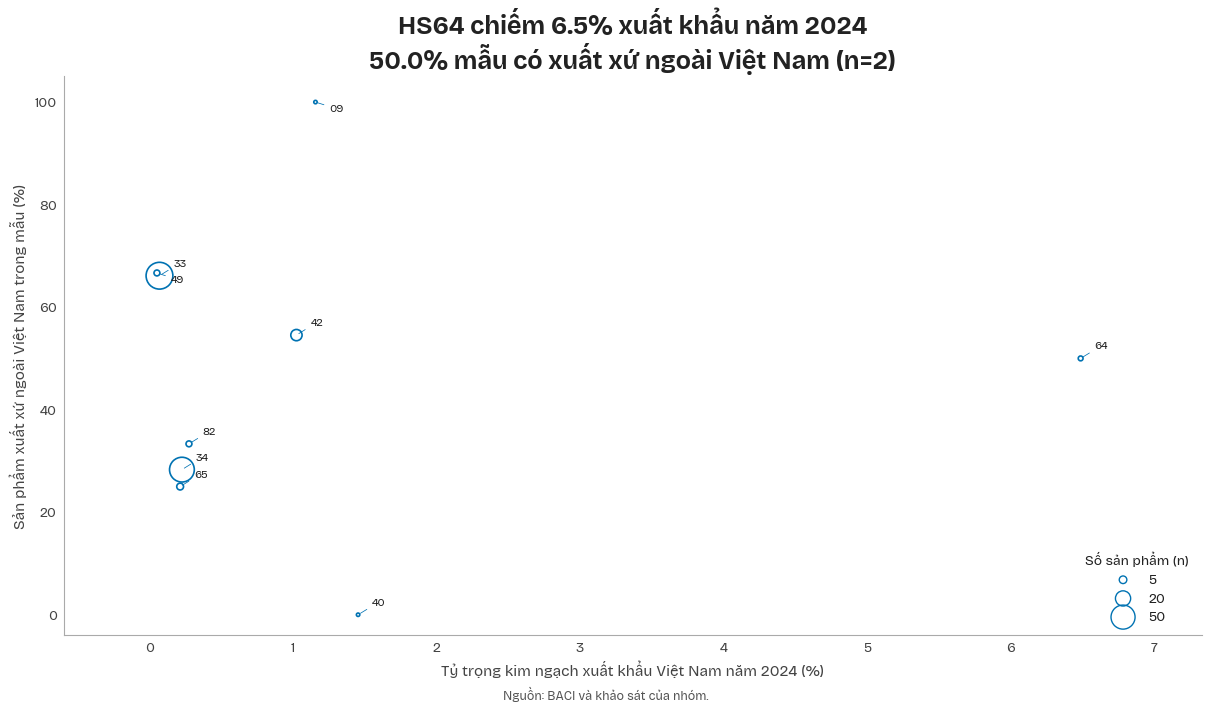

In [49]:
from pathlib import Path
import sys

year_c07a = 2024
min_n_c07a = 1
color_c07a = None  # None dùng màu nhấn mặc định của T10.
bubble_scale_c07a = 6
compatible_hs2_c07a = {"09", "33", "34", "40", "42", "49", "64", "65", "82"}  # Đối chiếu UNSD tại Cell 1.

root_c07a = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/clean/baci_hs_summary.csv").is_file()),
    Path.cwd(),
)
style_dir_c07a = str(root_c07a / "notebooks")
if style_dir_c07a not in sys.path:
    sys.path.insert(0, style_dir_c07a)
from house_style import house_style as hs

df_c07a = lay_du_lieu_c07a(root_c07a / "data/clean/baci_hs_summary.csv",
                           root_c07a / "data/clean/survey_final.csv", year_c07a,
                           min_n_c07a, compatible_hs2_c07a)
assert df_c07a["hs2"].is_unique
assert df_c07a["outside_vn_pct"].between(0, 100).all()
assert df_c07a["export_share_pct"].between(0, 100).all()
assert df_c07a["export_share_pct"].sum() <= 100 + 1e-8
print(df_c07a.to_string(index=False, float_format=lambda x: f"{x:.1f}"))
with hs.apply_style():
    fig_c07a, ax_c07a = ve_c07a(df_c07a, year_c07a, color_c07a or hs.ACCENT_COLOR, bubble_scale_c07a,
                               provisional=compatible_hs2_c07a is None)
    output_c07a = root_c07a / f"outputs/core_charts/C07/C07A_{year_c07a}.png"
    output_c07a.parent.mkdir(parents=True, exist_ok=True)
    fig_c07a.savefig(output_c07a, dpi=hs.THEME["savefig.dpi"])
    plt.show()


### Kết luận · C07A

**Action title** - Trong 9 chương được giữ, HS64 chiếm **6.5%** kim ngạch xuất khẩu Việt Nam năm 2024, còn **50.0%** mẫu HS64 có xuất xứ ngoài Việt Nam (**1/2 sản phẩm**).

HS64 có cỡ mẫu nhỏ. Ở HS33, chương có nhiều sản phẩm khảo sát nhất trong hình, **41/62 sản phẩm (66.1%)** có xuất xứ ngoài Việt Nam và chương chiếm khoảng **0.1%** tổng xuất khẩu Việt Nam. Kết quả mô tả mẫu tại các cửa hàng khảo sát.

Phạm vi hiển thị gồm **9 chương và 140 sản phẩm** sau khi loại các dòng cần xác minh xuất xứ và các chương có liên kết chéo HS2002–HS2022 theo tiêu chí ở Cell 1.
